In [2]:
#Importing Main Modules

%matplotlib inline 
import numpy as np 
import matplotlib.pyplot as plt 
from IPython.display import Image

# From Routes to Bridges: Investigating Numerical Computation Methods for Solving Scientific Problems

### Zaheer Taher

## Abstract

This report investigated two interesting computational problems: one was an optimisation problem and the other related to modelling a physical system. The first was an instance of the Travelling Salesman Problem (TSP) related to 30 capital cities in the USA, for which a Nearest Neighbour algorithm obtained a benchmark shortest tour length of 2338.63, whilst the Simulated Annealing (SA) algorithm achieved 2285.92 – the Genetic Algorithm beat both heuristics with a length of 2202.91. However, it was significant to note that the latter two methods were susceptible to stochastic effects, meaning the solutions obtained required repeated runs and continuous exploration of the solution space compared to the deterministic nature of the NN algorithm. The other problem investigated was related to the collapse of the Tacoma Narrows bridge, modelling the bridge as a beam suspended by two wires based on the McKenna Tuama model; it was found from a series of heatmaps, frequency-response curves and phase-trajectory plots that there was non-linear coupling between the vertical displacement and torsional angle, with maximal injection of energy from the vertical mode to the torsional mode near resonant frequencies, providing a possible justification for the bridge’s collapse. Additionally, an implementation of a tuned mass damper (TMD) as a solution and modelling the bridge as a series of joined segments (using Object-Oriented Programming) were also explored.

## 1. Introduction

This report aimed to investigate two types of interesting computational problems; these were optimisation problems and modelling physical systems. Numerical modelling or analysis can be defined as a branch of mathematics and computer science focused on developing and analysing algorithms to find approximate numerical solutions to complex problems (www.maths.manchester.ac.uk, n.d.). However, its significance extends across many other scientific disciplines as it has evolved into dedicated subfields, such as computational physics, computational biology and computational chemistry. In the latter two fields, an example of using numerical modelling or analysis is in drug discovery and development through molecular dynamics simulations. (Zhang et al., 2022) Another example in relation to Earth science and geophysics is how computers have transformed the understanding of the role of chaos and exponential error growth in weather forecasting, as well as the regional impacts of climate change. For instance, high-end computing has demonstrated the critical role of eddies in controlling ocean climate and how the likelihood of extreme weather events may respond to rising greenhouse gas concentrations. (Allen, 2016) 

More related to physics is the investigation of ‘complex systems’ (systems composed of many similar, interacting components such as atoms within a solid and liquid) and extending this concept to interacting organisms or traders within financial markets; recent developments in modelling and computational simulation have made it possible to apply physics-based methods to these previously difficult real-world systems, providing insights into phenomena such as disease transmission, traffic flow, and the organisation of large-scale human societies. (Newman, 2016) In fact, the UK government explicitly highlighted its commitment to advancing computational modelling for similar purposes in 2018 through the Computational Modelling: Technological Futures (Blackett Review). The report highlighted the Council for Science and Technology’s interest in strengthening the UK’s modelling capabilities and ensuring they were more effectively utilised across both the public and private sectors: some areas of interest included public policy, business and manufacturing, cities and infrastructure, finance and economics, and environmental applications. (Government Office for Science, 2018). 
Looking to the future, the UK government intends to use quantum technologies to exponentially increase computing power as outlined in the National Quantum Strategy, with one of the key goals being making the UK home to world-leading quantum science and engineering (HM Government, 2023). In relation to this, numerical modelling has been powerful in the research undertaken to accomplish these goals, for instance through enabling the efficient and highly accurate simulation of complex quantum many-body systems, that due to the exponential complexity of the Schrödinger equation would otherwise be infeasible; this is achievable via modern classical computers in particular due to Tensor Network State techniques (Wahl, 2016). Furthermore, many remarkable phenomena in condensed matter physics — including superconductivity and the quantum Hall effect — that arise from the collective quantum interactions of large numbers of electrons can be studied further through this modelling.

The first of the problems investigated in this report was an example of the Travelling Salesman Problem (TSP) in the context of 30 US capital cities – the objective was to find the shortest possible tour that would visit all 30 cities once and return to the starting city. Since this problem is known as an NP-hard problem (Non-deterministic Polynomial-time hard), brute force methods would not be viable, meaning that heuristics were implemented to provide approximate solutions. The first of these were a Nearest Neighbour (NN) algorithm that served as a deterministic benchmark for the other two probabilistic methods used that were Simulated Annealing (SA) and Genetic Algorithms (GA), both of which taking inspiration from nature through metallurgy and evolution respectively. Finally, the use of these algorithms in other scenarios was explored, such as in finding the longest tour length or avoiding coast-to-coast travel. The second problem examined concerned one of the most well-known cases of engineering failure — the collapse of the Tacoma Narrows Bridge; this was done with reference to McKenna Tuama’s modelling framework of representing the deck as a coupled system relating the vertical displacement and torsional angle. An implementation of a tuned mass damper (TMD) was also considered as potential strategy to prevent the structural instability, and an object-oriented programming (OOP) approach was employed to construct a bridge through modelling it as a series of interconnected segments. The report concluded with a description of how the 5CCP211C Introduction to Numerical Modelling course equipped me with the knowledge to complete these investigations, as well as explored future outlooks and extensions of the implementations in this report.


## 2. Around the U.S. in 30 Cities: An Exploration of the Travelling Salesman Problem

The Travelling Salesman Problem (TSP) has the objective of finding the shortest route that visits each city (or place of interest) exactly once and returning to the starting point; this report applies this to 30 capital cities in the United States. While the problem is easy to state, the difficulty arises in minimising the total distance, making it a challenging optimisation task. 

For a small number of cities, one could do this by hand, such as for an instance of four cities where there would be twelve routes to compute from which the shortest could be chosen. However, as the number of cities increase, the number of possible tours grows factorially, rendering brute-force methods such as this impractical; this would result in a time complexity of $O(n!)$. The TSP is therefore classified as NP-hard (GeeksforGeeks, 2020): in essence, this means that although a proposed tour can be verified quickly, finding the optimal tour from scratch becomes computationally intractable for large instances.
Exact methods exist that have a lower time complexity such as the Held-Karp algorithm, which uses dynamic programming to systematically build optimal tours from smaller subproblems; this reduces the time complexity to $O(n^2 2^n)$, and despite still being exponential, it represents a significant improvement over brute force and allows moderately sized instances to be solved exactly (Luu, 2023). Alternative methods include frameworks such as branch-and-bound and branch-and-cut that explore the space of tours more intelligently by discarding partial solutions that cannot lead to an optimal result; the former achieves this by using bounds to prune inefficient routes early, whilst the latter further improves performance by introducing additional constraints to eliminate invalid structures, such as incomplete subtours. Despite not removing the exponential nature of the problem in theory, they are often far more efficient for solving much larger instances of the TSP exactly than brute force methods. More recently, Ambainis et al. developed a quantum exact algorithm for the Travelling Salesman Problem with a time complexity of $O(1.728^n)$, which as of 2019 is the most efficient known exact method. Nevertheless, despite its improved theoretical performance, it is not yet feasible for solving large instances in practice given current quantum computing constraints (Ambainis et al., 2019).

However, in practice, heuristic and metaheuristic approaches are often preferred for larger problems, with heuristics being a single, problem-focused strategy, whilst metaheuristics serve as a general framework that manages or combines heuristics to tackle complex problems more effectively. An example of a heuristic is the Christofides algorithm that constructs a tour guaranteed to be no more than 1.5 times the optimal length (provided the triangle equality is obeyed where going directly is never longer than going via another city); this is achieved by constructing a minimum spanning tree (connecting the cities in the cheapest possible way without any loops) and then adding just enough extra connections to make it possible to travel through every city in one continuous tour before finally rearranging this route into a valid round tour (Krymgand, n.d.). Another example (explored in this report) is the Nearest Neighbour (NN) heuristic, that builds a tour by making the best local choice at each step such that it always selects the nearest unvisited city – this makes it known as a greedy algorithm. Examples of metaheuristics include Simulated Annealing (SA) and Genetic Algorithms (GA) that are discussed in further detail in their respective sections of this report, as well as Ant Colony Optimisation (ACO), that as the name suggests is inspired by how real ants find the shortest path to food, as in nature, ants lay down chemical trails (pheromones) such that shorter paths accumulate stronger trails because they are travelled more frequently, meaning other ants are then more likely to follow these stronger paths. The computational version of this entails many simulated ‘ants’ building possible solutions, with the better solutions depositing more virtual pheromone so that over time the good routes are reinforced whilst the poorer ones fade away such that the algorithm converges to a near-optimal solution (Dorigo, 2007).

One could trace the historical background of the TSP back to the 19th century, where despite no mathematical formulation of the problem, a similar premise was found mentioned in an 1832 manual for travelling salesman that included example tours of 45 German cities to optimise their routes for commerce (Cook, 2012). Preceding this was a mathematical problem from 1736 reminiscent of the TSP known as the Seven Bridges of Königsberg; served as the basis for Euler’s invention of the field called “the geometry of position”, now known today as graph theory. The problem involved finding a walk through the city of Königsberg by passing over each of its seven bridges exactly once, and Euler’s investigation revealed that this was not possible by abstracting the problem into a graph such as the one seen in Figure 1. 




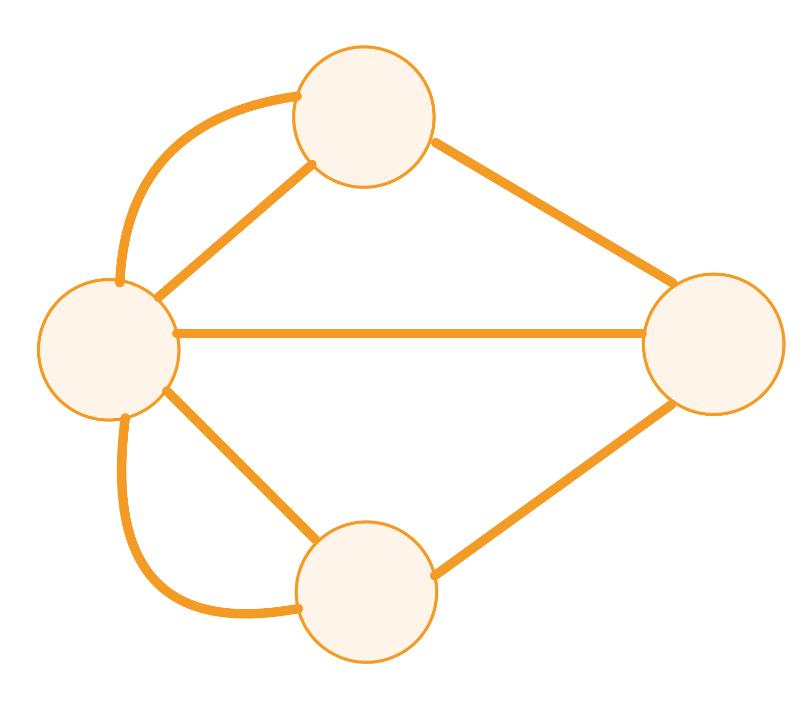

In [4]:
Image(filename='Seven_Bridges_Diagram.png')

*Figure 1: An abstracted diagram representing the Seven Bridges of Königsberg problem, where the circles represent the landmasses and the lines represent the bridges.*

Notable work was done related to the TSP and graph theory by the Irish mathematician Sir William Rowan Hamilton and by the British mathematician Thomas Penyngton Kirkman in the 1800s, with Hamilton's Icosian Game being an example that required players to complete tours through the 20 points using only the specified connections (Figure 2). It was not until the 1930s where the general form of the TSP appeared to be formalised by Karl Menger in Vienna and Harvard, with the problem later promoted by Hassler Whitney and Merrill Flood at Princeton. The work of George Dantzig, Ray Fulkerson, and Selmer Johnson in 1954 revealed a breakthrough in solution methods for the TSP through the use of linear programming methods such as the cutting-plane method, and their investigation shows a likeness to the problem investigated in this report as their problem was designed to find the shortest route connecting the capital cities of the 48 states in the contiguous United States, plus Washington, D.C. (Uwaterloo.ca, 2023).

The TSP remains relevant in the modern day, with many applications beyond being a benchmark to test computational power, in particular for transportation applications such as the routing of trucks for parcel post pickup and the logistics of last-mile delivery problems (Guo, Mo and Wang, 2023). Another area where the TSP has been useful is the scheduling of a machine to drill holes in a circuit board or other object, where the holes to be drilled are the cities whilst the cost of travel is the time taken to move the drill head from one hole to the next. Returning back to computational biology, researchers at the National Institute of Health utilised the Concorde's TSP solver to construct radiation hybrid maps for ongoing work in genome sequencing, and a group at AT&T have also used Concorde to compute DNA sequences in a genetic engineering research project. (www.math.uwaterloo.ca, n.d.)

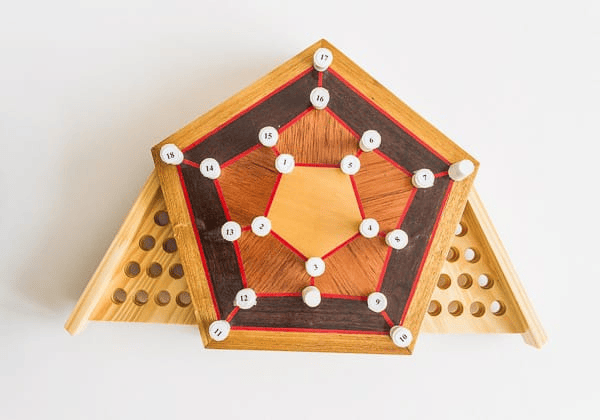

In [5]:
Image(filename='Icosian_Game.png')

*Figure 2: An image of Hamilton's Icosian Game (Ricardo, 2014)*

### 2.1 Nearest Neighbour

This section of the report details an implementation of the Nearest Neighbour (NN) algorithm, 
which constructs a TSP tour by repeatedly selecting the shortest available distance from the 
current city to an unvisited city. Due to this behaviour, it is known as a greedy algorithm can produce sub-optimal global routes when early locally optimal choices prevent 
exploration of more efficient long-range connections.

#### 2.1.1 Initial Implementation

[('Oklahoma City', (392.8, 356.4)), ('Montgomery', (559.6, 404.8)), ('Salt Lake City', (204.0, 243.2))]


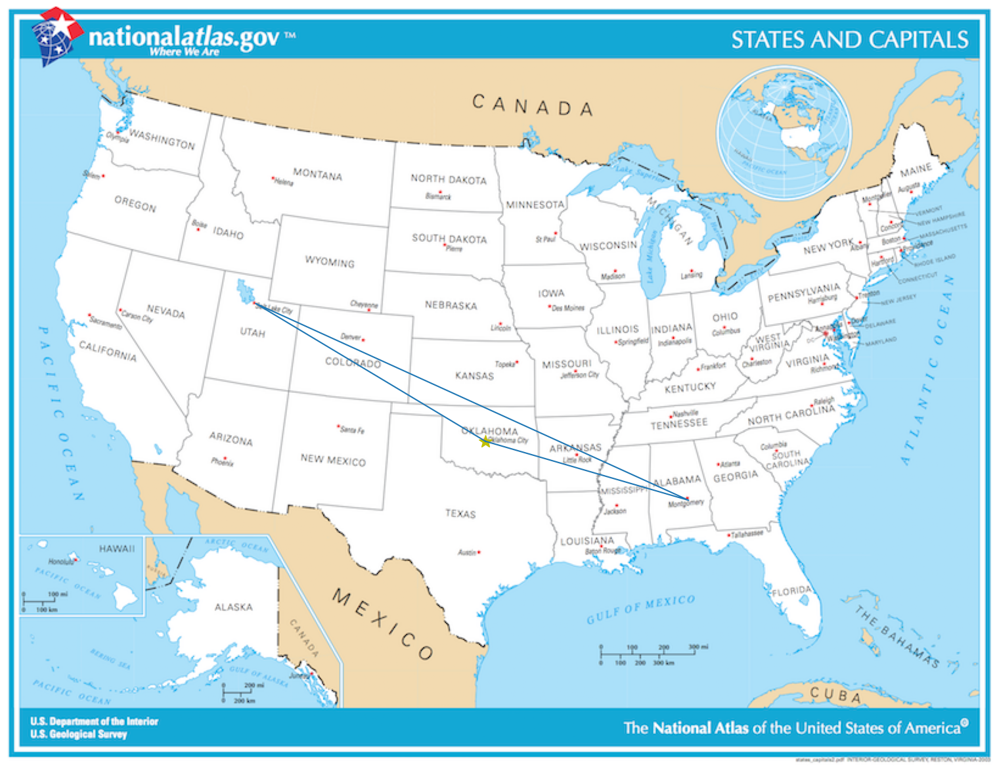

In [6]:
# ============================================================
# JSON DATA LOADING AND PREPROCESSING (TSP)
# ============================================================

"""
Loads capital city data from a JSON file and prepares it for use in
Travelling Salesman Problem (TSP) algorithms and visualisation.

City data are stored as:
    (city_name, (x, y))
to preserve both identity and geometric information.
"""

import json
import random  
import matplotlib.image as mpimg
from matplotlib.patches import Patch
from IPython.core.interactiveshell import InteractiveShell

# Reduce notebook output clutter - changed from "all" to "last_expr"
InteractiveShell.ast_node_interactivity = "last_expr"

# Background map (visualisation only)
"""
The map image is used solely for plotting TSP paths.
City coordinates are given in pixel units corresponding to this image.
"""
map = mpimg.imread("map.png")

# Load capital city data
"""
JSON format:
    city_name : [x, y]

Converted into a list of tuples for indexed access and algorithmic use.
"""
with open("capitals.json", "r") as capitals_file:
    capitals_dictionary = json.load(capitals_file)

# Convert dictionary to list of (city_name, (x, y))
capitals_list = [
    (city_name, tuple(xy))
    for city_name, xy in capitals_dictionary.items()
]


# ============================================================
# COORDINATE EXTRACTION UTILITIES
# ============================================================

"""
Helper functions to separate geometric data from city labels.
This avoids repeated tuple unpacking and improves readability
throughout the TSP code.
"""

def get_city_coordinates(city):
    """
    Extract (x, y) coordinates from a city tuple.

    Example:
        ("Atlanta", (585.6, 376.8)) to (585.6, 376.8)
    """
    _, coordinates = city
    return coordinates


def get_path_coordinates(path):
    """
    Extract a list of (x, y) coordinates from a city path.

    Example:
        [("Atlanta", (585.6, 376.8)), ...] to [(585.6, 376.8), ...]
    """
    _, coordinates = zip(*path)
    return coordinates


# ============================================================
# PATH VISUALISATION
# ============================================================

"""
Overlays a TSP path onto the map image.
"""

def show_path(path, starting_city, w=35, h=15):
    """Plot a TSP path over the background map."""
    
    path_coordinates = get_path_coordinates(path)
    x, y = zip(*path_coordinates)

    x0, y0 = get_city_coordinates(starting_city)

    plt.imshow(map)
    plt.plot(x0, y0, "y*", markersize=15)   # Starting city highlighted with a yellow star
    plt.plot(x + x[:1], y + y[:1])          # Close the tour loop to represent a full tour
    plt.axis("off")                         # Axes removed for clarity

    fig = plt.gcf()
    fig.set_size_inches([w, h])


# ============================================================
# BASIC VALIDATION
# ============================================================

"""
Short sanity check to confirm correct functionality
"""

test_path = [capitals_list[0], capitals_list[1], capitals_list[4]]
print(test_path)

show_path(test_path, capitals_list[0])
plt.show()

This section loaded and preprocessed the capital city data from the capitals.json file for use in the TSP algorithms investigated, reading the city coordinates from the file and converting them into a list of (city_name, (x, y)) tuples, enabling indexed access whilst preserving their identity and geometric information. Furthermore, the background image was loaded in for use during visualisation of the routes, with city coordinates defined in pixel units consistent with the image.
<br>
<br>
Additionally, helper/utility functions were introduced to cleanly separate the coordinate extraction from the city labels to improve readability and reduce repetition throughout the code. A plotting function could then plot the candidate tours onto the map, with the starting city marked explicitly with a yellow star and the path closed in order to represent a full TSP cycle.
<br>
<br>
Lastly, a short sanity check was used to confirm that the data was loaded in correctly, the coordinate utilities behaved as expected, and that the path visualisation executed without error.

In [7]:
# ============================================================
# DISTANCE METRIC
# ============================================================

"""
Computes the Euclidean distance between two cities.

This distance is the cost metric used by all TSP algorithms
in the project.
"""

def calculate_distance(city_a, city_b):
    """
    Calculate the straight-line distance between two cities.
    """

    # Extract coordinates from city tuples

    _, (x1, y1) = city_a
    _, (x2, y2) = city_b

    # Calculate distance using Pythagorean theorem

    return np.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

The function calculate_distance utilised Pythagorean theorem to compute the distance between two cities solely based on their coordinates; the specification of Euclidean distance was to avoid confusion with other kinds of distance measure, such as Manhattan, Geodesic or Haversine distance. Abstracting the distance calculation into a single function ensured consistency across all algorithms and avoided duplicated logic, providing a simple, well-defined measure of tour length that could be used for comparison.

In [8]:
# ============================================================
# TOTAL PATH LENGTH CALCULATION
# ============================================================

"""
Computes the total length of a Travelling Salesman Problem (TSP) tour.
"""

def calculate_total_path_length(path):

    total_length = 0.0 # Initialise accumulator

    total_path = path + [path[0]] # Close the tour (return to start)

    # Sum distances between consecutive cities
    
    for city1, city2 in zip(total_path, total_path[1:]):
        total_length += calculate_distance(city1, city2)

    return total_length

This function computed the total cost of a TSP tour by summing the distances between consecutive cities in the visiting sequence, with the path explicitly closed by reconnecting the final city to the starting city to ensure the result represented a valid TSP cycle; this was separated in a similar fashion to the function calculate_distance so that it could be reused as a clear definition of the total tour length for all the TSP algorithms explored. 

Starting city: Providence
Nearest Neighbour Tour Length: 2585.1130820602575
Nearest Neighbour tour: ['Providence', 'Boston', 'Hartford', 'Albany', 'Trenton', 'Harrisburg', 'Richmond', 'Raleigh', 'Columbia', 'Atlanta', 'Montgomery', 'Tallahassee', 'Jackson', 'Baton Rouge', 'Little Rock', 'Oklahoma City', 'Austin', 'Nashville', 'Indianapolis', 'Columbus', 'Lansing', 'Madison', 'Saint Paul', 'Des Moines', 'Denver', 'Salt Lake City', 'Boise', 'Salem', 'Sacramento', 'Phoenix']


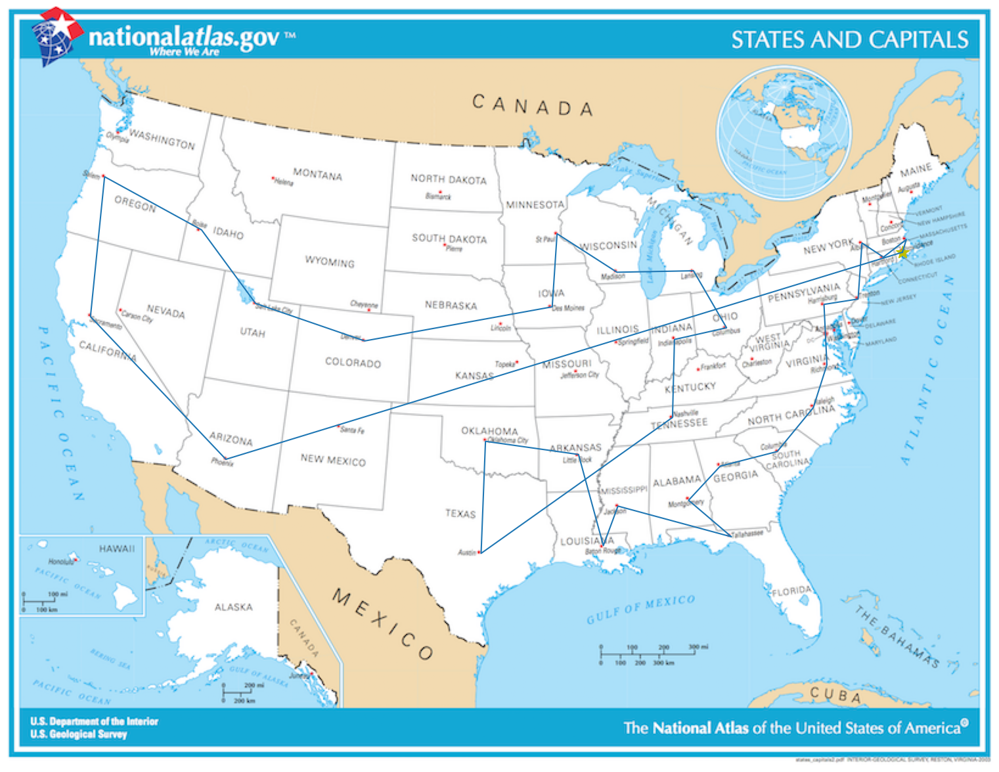

In [41]:
# ============================================================
# NEAREST NEIGHBOUR HEURISTIC (TSP)
# ============================================================

"""
Constructs an approximate TSP tour using the nearest neighbour heuristic.
"""

def nearest_neighbour_tsp(capitals_list, starting_city):

    # Initialise path and unvisited list

    unvisited_cities = capitals_list.copy()
    path = [starting_city]
    unvisited_cities.remove(starting_city)

    current_city = starting_city

    # Greedy selection of nearest unvisited city

    while unvisited_cities:

        nearest_city = min(
            unvisited_cities,
            key=lambda city: calculate_distance(current_city, city)
        )

        path.append(nearest_city)
        unvisited_cities.remove(nearest_city)
        current_city = nearest_city

    return path

# ============================================================
# TEST: NEAREST NEIGHBOUR (SINGLE START)
# ============================================================

"""
Quick sanity check for the nearest neighbour heuristic using a single
random starting city.
"""

starting_city_test = random.choice(capitals_list) # Select random starting city
print("Starting city:", starting_city_test[0])

# Generate NN tour and compute length

nearest_neighbour_tour_test = nearest_neighbour_tsp(
    capitals_list,
    starting_city_test
)

tour_length = calculate_total_path_length(nearest_neighbour_tour_test)
print("Nearest Neighbour Tour Length:", tour_length)

print(
    "Nearest Neighbour tour:",
    [city[0] for city in nearest_neighbour_tour_test]
) # Print tour as city names for readability


# Visualise tour

plt.clf()  # Clear previous figure
show_path(nearest_neighbour_tour_test, nearest_neighbour_tour_test[0])
plt.show()

The Nearest Neighbour (NN) heuristic was finally implemented here as a simple, greedy approach to constructing a TSP tour, and achieved this by beginning from a random starting city from the list of capitals and starting the path there, with the algorithm repeatedly selecting the closest unvisited city according to calculate_distance until gradually a complete TSP tour was built (in accordance with the while loop ensuring all cities were visited). 
<br>
<br>
Whilst this method was computationally inexpensive and easy to interpret, the effects of its greedy nature were made prominent from the example used to test its functionality, where it can be seen that from the map that for the starting city of Providence, whilst it does make locally optimal decisions, at the end of the tour as the algorithm returns from Phoenix it covers a large distance across the USA, significantly increasing the total tour length and resulting in a sub-optimal global tour.

#### 2.1.2 Starting the Nearest Neighbour Heuristic for All Cities

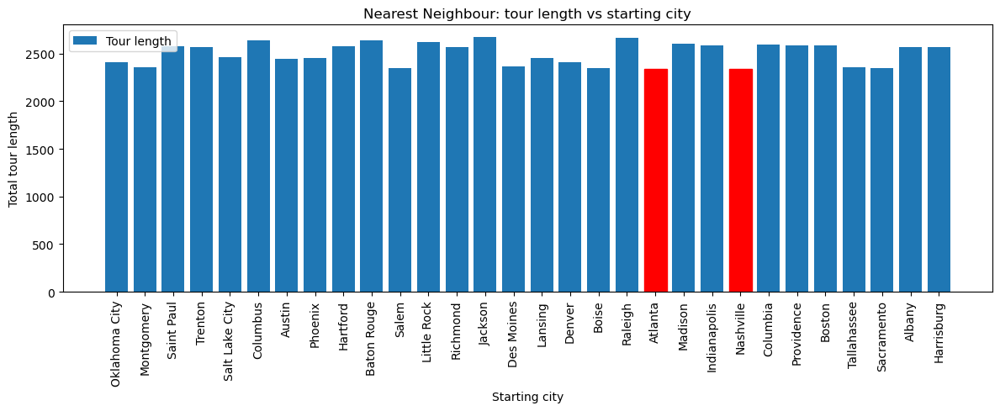

Minimum Tour Length: 2338.63
Starting Cities Achieving Minimum:
Index 19: Atlanta
Index 22: Nashville


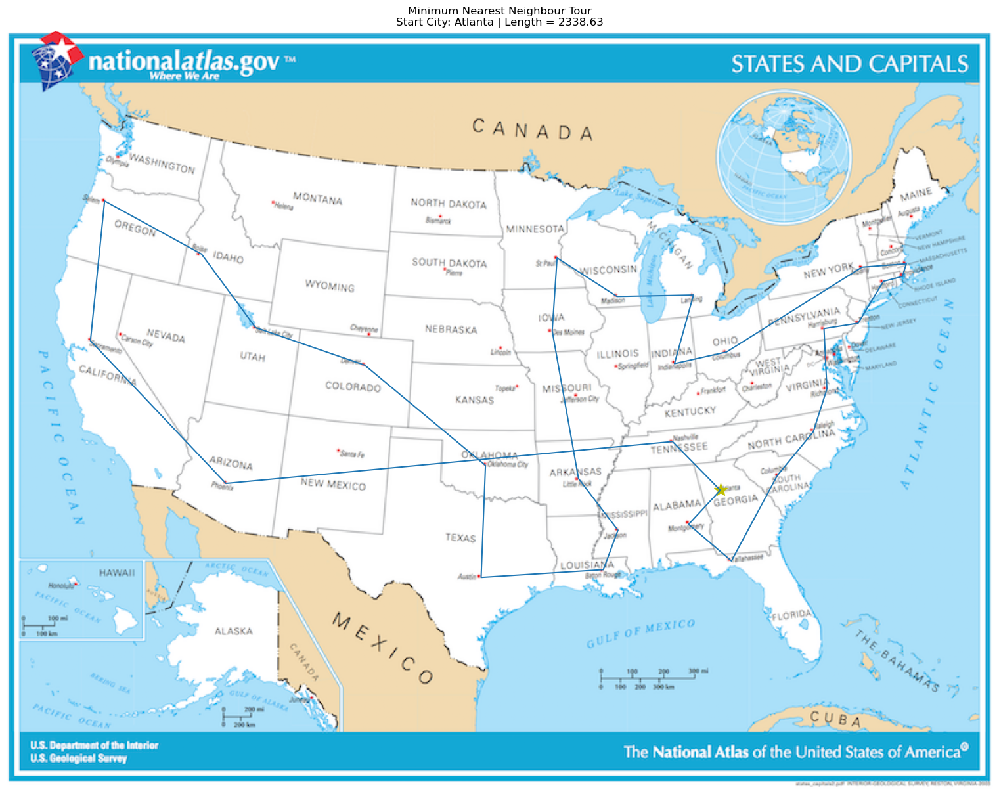

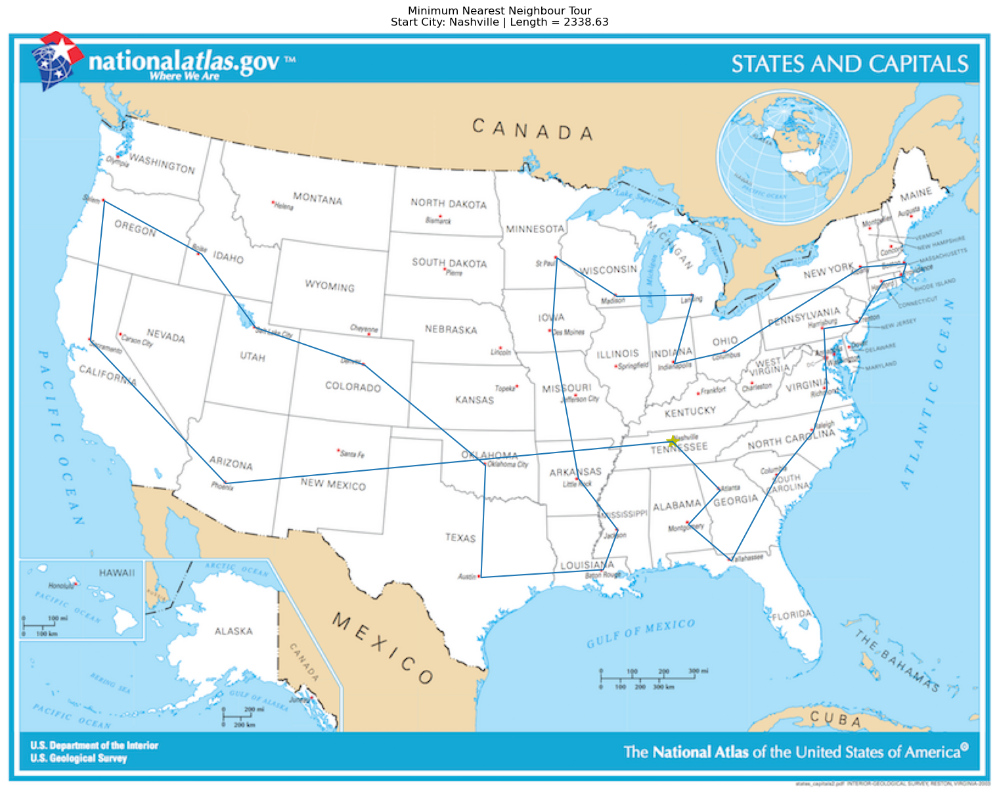

In [42]:
# ============================================================
# ALL STARTING CITIES SWEEP FOR NEAREST NEIGHBOUR HEURISTIC
# ============================================================

"""
Runs NN from every possible starting city to show how sensitive the
greedy tour length is to the start choice, and to find the best NN tour(s).
"""

# Run NN from every starting city and store results

def nearest_neighbour_analysis_all_starts(cities):

    # Storage arrays (one entry per starting city)
    start_indices = []
    start_city_names = []
    tour_lengths = []
    tours_by_start = []

    # Run NN once per start
    for start_index, start_city in enumerate(cities):
        tour = nearest_neighbour_tsp(cities, start_city)
        length = calculate_total_path_length(tour)

        start_indices.append(start_index)
        start_city_names.append(start_city[0])
        tour_lengths.append(length)
        tours_by_start.append(tour)

    # Best length (include ties)
    best_length = min(tour_lengths)
    best_start_indices = [
        idx for idx, tour_len in enumerate(tour_lengths) if tour_len == best_length
    ]

    return (
        start_indices,
        start_city_names,
        tour_lengths,
        tours_by_start,
        best_start_indices,
        best_length,
    )

# Plot tour lengths by starting city, highlighting best starts

def plot_nn_lengths_by_start(start_indices, start_city_names, tour_lengths, best_start_indices):

    plt.figure(figsize=(12, 5))
    bars = plt.bar(start_indices, tour_lengths)

    # Highlight best (minimum length) starts
    for best_idx in best_start_indices:
        bars[best_idx].set_color("red")

    plt.xticks(start_indices, start_city_names, rotation=90)
    plt.xlabel("Starting city")
    plt.ylabel("Total tour length")
    plt.title("Nearest Neighbour: tour length vs starting city")
    plt.legend(["Tour length", "Minimum tour length"])

    plt.tight_layout()
    plt.show()

# Printing and plotting best tour(s) (handles ties)

def plot_best_tours(tours_by_start, best_start_indices, best_length, cities):

    print(f"Minimum Tour Length: {best_length:.2f}")
    print("Starting Cities Achieving Minimum:")

    for best_idx in best_start_indices:
        print(f"Index {best_idx}: {cities[best_idx][0]}")

    # Plot each best tour (handles ties)
    for best_idx in best_start_indices:
        best_tour = tours_by_start[best_idx]

        plt.figure()
        show_path(best_tour, best_tour[0])
        plt.title(
            "Minimum Nearest Neighbour Tour\n"
            f"Start City: {cities[best_idx][0]} | Length = {best_length:.2f}"
        )
        plt.show()

# Running the analysis and plotting results

(
    start_indices,
    start_city_names,
    tour_lengths,
    tours_by_start,
    best_start_indices,
    best_length
) = nearest_neighbour_analysis_all_starts(capitals_list)

plot_nn_lengths_by_start(start_indices, start_city_names, tour_lengths, best_start_indices)
plot_best_tours(tours_by_start, best_start_indices, best_length, capitals_list)

Due to the deterministic and non-random nature of the NN algorithm, any variation in tour length would arise solely from the choice of starting city rather than stochaistic effects, so this section extended the NN heuristic to run from every possible starting city to exhaust all possible NN tour lengths. For each start, it stored the constructed tour, computed its total length, and then identified the minimum tour length (including ties) so that the best NN start(s) could be reported consistently.
<br>
<br>
Since the starting cities were a discrete categorical variable, a bar chart was used to visualise the total tour length against starting city, with the best starting cities highlighted in red to be Atlanta and Nashville, both tied for a total length of 2338.63; the maps of these were also presented, revealing that the same issues discussed previously arose of crossing large distances to return to the starting city due to early greedy decisions made - in this case, this was travelling from Phoenix to Nashville for both routes. 
<br>
<br>
The significance of this result was that it served as a benchmark for the other algorithms investigated; the use of the other heuristics would have to be justified by them providing a more optimal tour length despite their greater complexity and computational costs relative to the NN algorithm.

### 2.2 Simulated Annealing

Simulated Annealing (SA) is an algorithm that takes inspiration from annealing in metallurgy, where a metal is rapidly heated and then cooled slowly to improve its structural properties. At high temperatures, atoms gain enough energy to move freely and explore many different configurations; as the material is gradually cooled, this motion is reduced, allowing the atoms to settle into a more stable, lower-energy arrangement (Brownlee, 2021).

The algorithm starts with an initial solution and a high temperature, with a perturbation generating a neighbouring solution by making a small random change (such as the pairwise exchange used in this report). Next, an acceptance criterion Is used in the evaluation of the objective function, such that if it is better, then it is accepted, but if it is worse, then it is accepted dependent on the probability outlined in Equation 1:

$$
P(\text{accept}) = \exp\!\left(-\frac{\Delta E}{T}\right)
\tag{1}
$$

where:
- $\Delta E = E_{\text{new}} - E_{\text{current}}$ is the change in the objective function (e.g. change in tour length for the TSP),
- $T$ is the current temperature of the system,
- $P(\text{accept})$ denotes the probability of accepting the solution.

This equation implies that worse solutions ($\Delta E > 0$) can still be accepted with a probability that decreases as the increase in cost becomes larger or as the temperature decreases. When $T$ is high, the probability of accepting worse solutions is relatively large, encouraging exploration of the solution space. As $T$ decreases, this probability becomes smaller, promoting convergence towards lower-energy (better) solutions. This behaviour is based on the Boltzmann distribution, which describes the probability of a system being in a certain state at a given temperature. 

A cooling schedule gradually decreases the temperature after each iteration, playing a crucial role in the performance of the SA algorithm; if the temperature decreases too quickly, the algorithm may converge prematurely to a suboptimal solution (local optimum), however if the cooling is too slow, the algorithm may take an excessively long time to obtain an optimal solution. Hence, it is essential to attain the right balance between exploration (high temperature) and exploitation (low temperature). (GeeksforGeeks, 2024)

This process then repeats until the temperature becomes very low or after a fixed number of iterations, at which point the algorithm is terminated. 

The first application of this concept to the TSP can be traced back to Kirkpatrick, Gelatt Jr. and Vecchi in 1983 (Kirkpatrick, Gelatt and Vecchi, 1983).  

#### 2.2.1 Initial Implementation


In [44]:
# ============================================================
# TEMPERATURE SCHEDULING (SIMULATED ANNEALING)
# ============================================================

"""
Defines a flexible temperature scheduling framework for simulated annealing.
Different cooling laws can be tested without changing the core SA algorithm.
"""

def temperature_schedule(step, cooling_function, **cooling_parameters):
    """
    Return the temperature at a given iteration step.
    """

    return cooling_function(step, **cooling_parameters)

# ============================================================
# EXPONENTIAL COOLING LAW
# ============================================================

def exponential_cooling(step, initial_temperature, cooling_rate):
    """
    Exponential cooling:
        T(step) = T_0 · α^step
    """

    return initial_temperature * (cooling_rate ** step)

The function temperature_schedule was implemented such that it decoupled the SA algorithm from any specific temperature schedule to improve modularity and experimental flexibility by enabling alternative cooling laws to be investigated through passing a different function and parameter set.
<br>
<br>
However, due to the fact it provides smooth, monotonic decay of temperature and gradually reduces the probability of accepting uphill (worse) moves, the commonly used exponential cooling function was utilised when investigating the SA algorithm, as described by Equation 2:

$$
T(t) = T_0 \cdot \alpha^t
\tag{2}
$$ 

where:

- $T(t)$ is the value of temperature at time $t$  
- $T_0$ is the initial temperature value (when $t = 0$)  
- $\alpha$ is the cooling rate  
- $t$ is time (or discrete step number)


In [ ]:
# ============================================================
# RANDOM PATH GENERATION 
# ============================================================

"""
Generate a random TSP path containing a specified number of distinct cities.
"""

def define_random_path(num_cities):

    path = []

    # Randomly select distinct cities until required length is reached
    while len(path) < num_cities:
        city = random.choice(capitals_list)

        if city not in path:
            path.append(city)

    return path

# ============================================================
# PAIRWISE SWAP 
# ============================================================

"""
Generate a neighbouring TSP path by swapping two distinct cities.
"""

def perform_pairwise_swap(path):

    # Select two distinct indices
    first_index = random.randint(0, len(path) - 1)
    second_index = random.randint(0, len(path) - 1)

    while first_index == second_index:
        second_index = random.randint(0, len(path) - 1)

    # Copy path to avoid in-place modification
    new_path = path.copy()

    # Swap selected cities
    new_path[first_index], new_path[second_index] = (
        new_path[second_index],
        new_path[first_index]
    )

    return new_path


# ============================================================
# TEST RANDOM PATH GENERATION AND PAIRWISE SWAP
# ============================================================

random_path_test = define_random_path(num_cities=8)
random_path_test_swapped = perform_pairwise_swap(random_path_test)

print("Original random path:", random_path_test)
print("Swapped random path:", random_path_test_swapped)

Original random path: [('Nashville', (546.4, 336.8)), ('Raleigh', (662.0, 328.8)), ('Austin', (389.2, 448.4)), ('Salem', (80.0, 139.2)), ('Salt Lake City', (204.0, 243.2)), ('Columbus', (590.8, 263.2)), ('Madison', (500.8, 217.6)), ('Boise', (159.6, 182.8))]
Swapped random path: [('Nashville', (546.4, 336.8)), ('Salt Lake City', (204.0, 243.2)), ('Austin', (389.2, 448.4)), ('Salem', (80.0, 139.2)), ('Raleigh', (662.0, 328.8)), ('Columbus', (590.8, 263.2)), ('Madison', (500.8, 217.6)), ('Boise', (159.6, 182.8))]


The function define_random_path constructed a random TSP tour by repeatedly sampling cities until the required number of distinct locations was reached, with the randomness of the initial conditions being well-suited for the SA algorithm as it allowed for diversity at the start to promote exploration. The perform_pairwise_swap function then performed the pairwise swap by choosing two distinct positions in a tour at random (with the while loop ensuring that two different positions were chosen) and then exchanging the cities, producing a new tour that would still be valid and visit each city exactly once (since no cities were added or removed), however be different and close to the original solution in structure. The path was copied in order to ensure the original tour remained unchanged so that unintended side effects could be prevented when evaluating and comparing multiple solutions.
<br>
<br>
The example usage demonstrated the effect of a single swap, providing a quick check that the function behaved as expected and produced a valid alternative tour.

Best path length found by SA: 1514.3597516983036
Best path found by SA: ['Providence', 'Harrisburg', 'Columbia', 'Montgomery', 'Phoenix', 'Sacramento', 'Lansing', 'Boston']


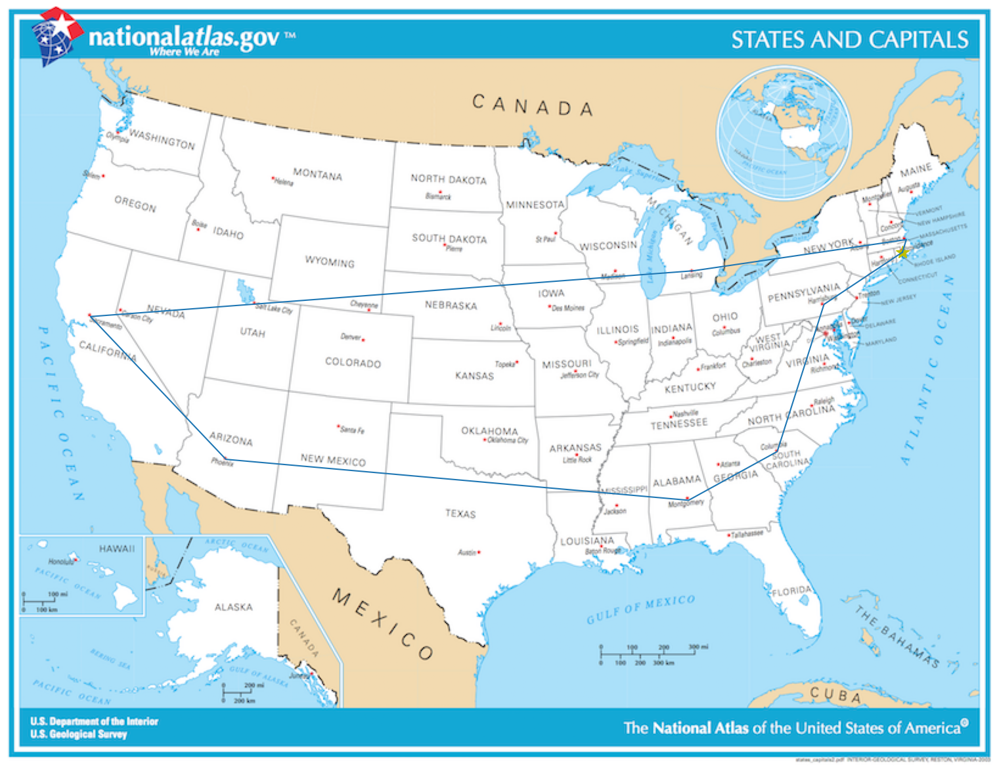

In [48]:
# ============================================================
# SIMULATED ANNEALING HEURISTIC (TSP)
# ============================================================

"""
Apply the simulated annealing heuristic to find a shorter TSP tour.
"""

def simulated_annealing_tsp(
    initial_path,
    cooling_function,
    cooling_parameters,
    max_steps
):
    """
    Runs SA and returns:
      distance_history, temperature_history, best_path, best_length
    """

    # Input path validation
    if initial_path is None:
        raise ValueError("initial_path must not be None")

    # Current solution
    current_path = initial_path
    current_length = calculate_total_path_length(current_path)

    # Best solution seen
    best_path = current_path
    best_length = current_length

    # Tracking distance and temperature for plots / analysis
    distance_history = []
    temperature_history = []

    # Main SA loop
    for step in range(max_steps):

        # Temperature from chosen schedule
        temperature = temperature_schedule(
            step,
            cooling_function,
            **cooling_parameters
        )
        temperature = max(temperature, 1e-12)

        distance_history.append(current_length)
        temperature_history.append(temperature)

        # Neighbour proposal
        new_path = perform_pairwise_swap(current_path)
        new_length = calculate_total_path_length(new_path)

        delta_length = new_length - current_length

        # Accept improvement, or accept worse with probability exp(-ΔL/T)
        if delta_length < 0 or random.uniform(0, 1) < np.exp(-delta_length / temperature):
            current_path = new_path
            current_length = new_length

            if current_length < best_length:
                best_path = current_path
                best_length = current_length

    return distance_history, temperature_history, best_path, best_length


# ============================================================
# TEST SIMULATED ANNEALING HEURISTIC
# ============================================================

distance_history_sa, temperature_history_sa, best_path_sa, best_length_sa = (
    simulated_annealing_tsp(
        initial_path=define_random_path(num_cities=8),
        cooling_function=exponential_cooling,
        cooling_parameters={
            "initial_temperature": 1000,
            "cooling_rate": 0.97
        },
        max_steps=200
    )
)

print("Best path length found by SA:", best_length_sa)
print("Best path found by SA:", [city[0] for city in best_path_sa])

plt.clf()
show_path(best_path_sa, best_path_sa[0])
plt.show()

This section implemented the full simulated annealing (SA) algorithm by starting with an initial (typically random) path (as a precaution, if there was no path then a ValueError would be raised to prevent the algorithm from crashing unexpectedly) and iteratively proposing nearby candidate tours using the pairwise_swap function and evaluating their total length. Improvements were always accepted, whilst worse solutions could still be accepted with a probabitity dependent on the increase in path length and the current temperature, following a Metropolis Monte Carlo criteria. 


The modularity of temperature_schedule meant that different cooling laws could be tested without ordering the core SA logic, and at high temperatures, the algorithm was more likely to accept uphill moves in order to escape local minima, whilst gradual cooling reduced this probability to drive convergence towards a stable solution, with the imposition of a small lower bound on the temperature in order to avoid numerical issues in the acceptance probability.  


Both the current tour length and temperature were recorded for later analysis throughout the run, with the best solution encountered tracked independently of the current state, and an example usage presented a complete SA run for a tour of 8 cities, reporting the best tour and its length, as well as displaying this on the map to demonstrate functionality.

#### 2.2.2 Optimising Number of Iterations (Timesteps)

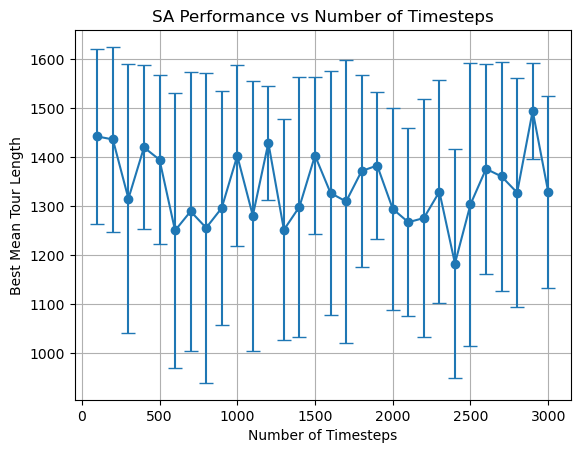

Five timestep values with the lowest mean best tour lengths:
N = 2400 | Mean best length = 1182.4647 (std = 233.3979)
N =  600 | Mean best length = 1249.8434 (std = 279.8355)
N = 1300 | Mean best length = 1251.2636 (std = 225.1700)
N =  800 | Mean best length = 1255.2529 (std = 316.4509)
N = 2100 | Mean best length = 1266.7370 (std = 192.3532)


In [49]:
# ============================================================
# SA SENSITIVITY: NUMBER OF ITERATIONS (TIMESTEPS)
# ============================================================

"""
Test how SA performance changes as the number of iterations increases.
"""

# Range of SA iteration counts to test
timesteps_tests = np.arange(100, 3001, 100)

# Runs per timestep value (to get mean and spread of results)
number_of_runs = 20

# Store mean and spread of best lengths
mean_best_lengths = []
standard_deviation_best_lengths = []

# Sweep over iteration counts
for timesteps in timesteps_tests:
    run_lengths = []

    for _ in range(number_of_runs):
        _, _, _, best_length = simulated_annealing_tsp(
            initial_path=define_random_path(num_cities=8),
            cooling_function=exponential_cooling,
            cooling_parameters={
                "initial_temperature": 1000,
                "cooling_rate": 0.97
            },
            max_steps=timesteps
        )
        run_lengths.append(best_length)

    mean_best_lengths.append(np.mean(run_lengths))
    standard_deviation_best_lengths.append(np.std(run_lengths))


# Plotting mean best lengths with error bars for standard deviation

plt.figure()

plt.errorbar(
    timesteps_tests,
    mean_best_lengths,
    yerr=standard_deviation_best_lengths,
    marker="o",
    capsize=5
)

plt.xlabel("Number of Timesteps")
plt.ylabel("Best Mean Tour Length")
plt.title("SA Performance vs Number of Timesteps")
plt.grid(True)
plt.show()

# Best timestep values (lowest mean)

sorted_indices = np.argsort(mean_best_lengths)

top_timestep_values = 5
best_indices = sorted_indices[:top_timestep_values]

print("Five timestep values with the lowest mean best tour lengths:")
for idx in best_indices:
    print(
        f"N = {timesteps_tests[idx]:4d} | "
        f"Mean best length = {mean_best_lengths[idx]:.4f} "
        f"(std = {standard_deviation_best_lengths[idx]:.4f})"
    )

This section investigated how the performance of SA depended on the number of iterations used, with the SA algorithm run over a sweep oftimestep values from 100 to 3000, and for each value multiple independent runs performed to account for the stochastic nature of SA. The mean and standard deviation were used to summarise the tour length from each run, capturing both typical perfomance and variability; the five timesteps with the lowest means were printed so that a decision could be made regarding which value to use going forward. 

The graph revealed that the stochaistic effects dominated, making it hard to distinguish which timestep values would be effective due to the large error bars overlapping. Ultimately, $ N = 1300 $ was selected since it was only slightly worse than the best mean at 2400, but with about half the runtime cost. It was still significant to consider how the impact of randomness meant rerunning the analysis could yield different results, but looking at values beyond 1300 there appeared to be diminishing returns - 1300 also seemed like a suitable spot between the lowest of 100 timesteps and the highest of 3000 timesteps.  

#### 2.2.3 Optimising the Cooling Rate

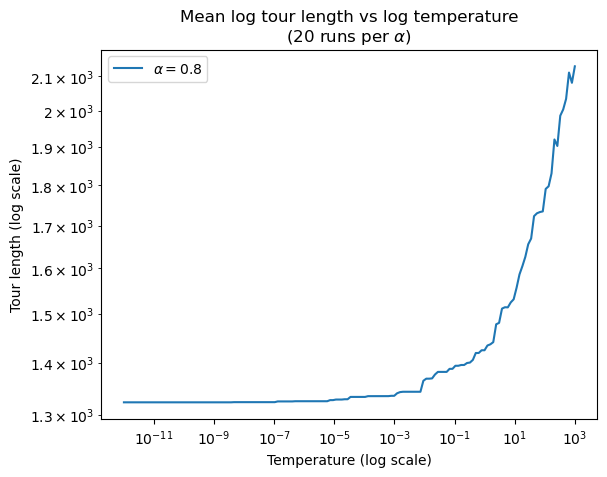

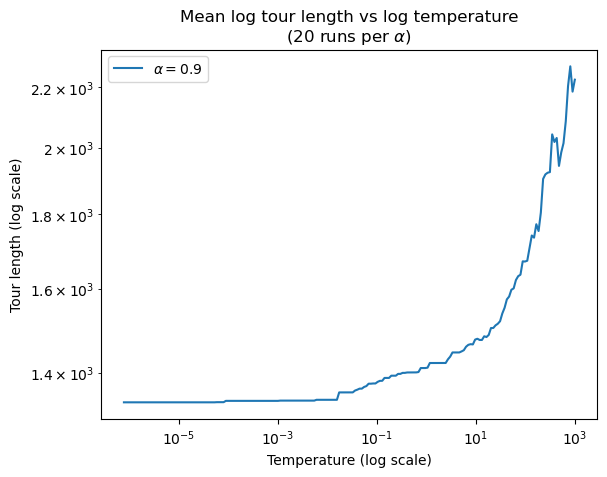

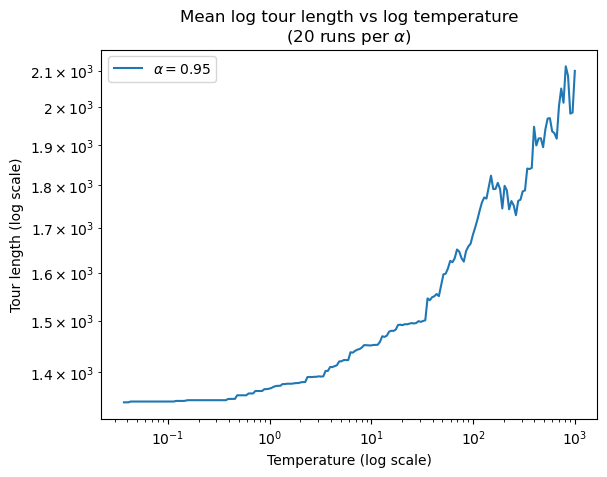

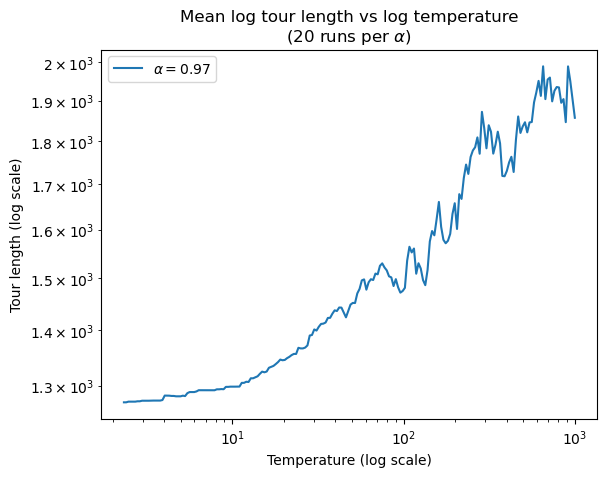

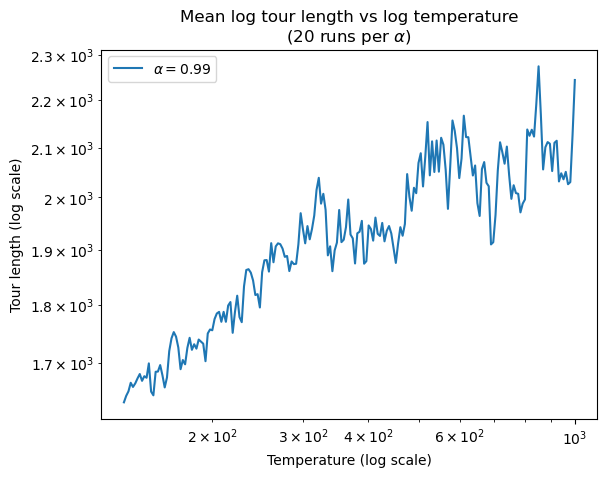

In [50]:
# ============================================================
# SA SENSITIVITY: COOLING RATE (α)
# ============================================================

"""
Compare SA behaviour for different exponential cooling rates α by plotting
the mean log–log trajectory (tour length vs temperature) across runs.
"""

alpha_tests = [0.80, 0.90, 0.95, 0.97, 0.99]
number_of_runs = 20
max_steps = 200

plt.figure()

for alpha in alpha_tests:

    all_distances = []
    all_temperatures = []

    # Multiple runs per α (to get mean and spread of results)
    for _ in range(number_of_runs):
        distance_history_sa, temperature_history_sa, _, _ = simulated_annealing_tsp(
            initial_path=define_random_path(num_cities=8),
            cooling_function=exponential_cooling,
            cooling_parameters={
                "initial_temperature": 1000,
                "cooling_rate": alpha
            },
            max_steps=max_steps
        )

        all_distances.append(distance_history_sa)
        all_temperatures.append(temperature_history_sa)

    # Mean trajectory across runs
    all_distances = np.array(all_distances)
    all_temperatures = np.array(all_temperatures)

    mean_distance = np.mean(all_distances, axis=0)
    mean_temperature = np.mean(all_temperatures, axis=0)

    plt.plot(
        mean_temperature,
        mean_distance,
        label=rf"$\alpha = {alpha}$"
    )

    plt.xscale("log")
    plt.yscale("log")
    
    plt.xlabel("Temperature (log scale)")
    plt.ylabel("Tour length (log scale)")
    plt.title("Mean log tour length vs log temperature\n(20 runs per $\\alpha$)")
    plt.legend()
    plt.show()

This section investigated how sensitive the SA was to the exponential cooling rate $\alpha$; the algorithm was run multiple times for each $\alpha$ value to average out randomness, with the mean trajectory of tour length temperature computed across runs to isolate the typical behaviour of the algorithm at each cooling rate as opposed to relying on a single noisy run.
<br>
<br>
Log scales were used to make it easier to compare trends across orders of magnitude in temperature and to see whether improvemnet happened gradually or only during specific temperature ranges. For the cooling rates of $\alpha$ = 0.80 and $\alpha$ = 0.90, the curve flattened rapidly at low temperatures, indicating that the temperature drop was too quick so the algorithm became greedy early in the run; this would restrict exploration and cause the algorithm to settle quickly into a local minimum. As a result, although convergence may be fast, it is often premature, reducing the chance of finding higher-quality tours later in the run.
<br>
<br>
For $\alpha$ = 0.95, the trajectory displayed more gradual improvement across a wider temperature range, however, the curve still began to plateau relatively early, suggesting that despite improvements in comparison to faster cooling rates, cooling was still fast enough to limit refinement during later stages of the run. 
<br>
<br>
The opposite was observed for $\alpha$ = 0.99, where the temperature decreased very slowly, leading to large fluctations in tour length over much of the run; this extensive exploration could be seen as 'over-exploration', where convergence would be weak meaning that there would be inefficient use of computational effort whilst the mean tour length could still remain comparatively high. 
<br>
<br>
Ultimately, $\alpha$ = 0.97 was chosen since it demonstrated the most balanced behaviour, exhibiting sustained improvement across the full temperature range with less early plateau or excessive noise. It allowed enough exploration to escape poor local minima in comparison to faster cooling rates, whilst still cooling quickly enough to refine the solution towards the end of the run. Compared to the other side of the spectrum, slower cooling rates tended to spend too long at higher temperatures, resulting in unnecessary wandering and weaker convergence within the fixed iteration budget, so $\alpha$ = 0.97 was the optimal compromise that balanced between exploration and convergence effectively without incurring unnecessary computational costs.   

#### 2.2.4 Optimising the Initial Temperature

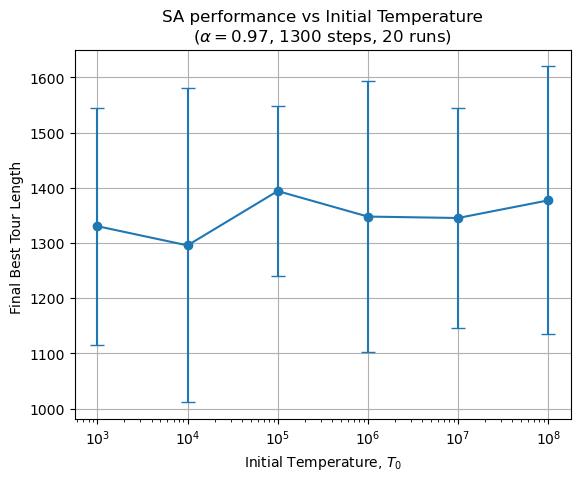

In [54]:
# ============================================================
# SA SENSITIVITY: INITIAL TEMPERATURE T₀
# ============================================================

"""
Test how the choice of initial temperature T₀ affects final SA performance.
"""

# Initial temperature values (log-spaced)
T0_tests = np.logspace(3, 8, num=6)   # 1e3 to 1e8

# Runs per T₀ value
number_of_runs = 20

# Fixed SA settings
max_steps = 1300
alpha = 0.97

# Store mean and spread of best lengths
mean_best_lengths = []
standard_deviation_best_lengths = []

# Sweep over T₀ values
for T0 in T0_tests:
    run_lengths = []

    for _ in range(number_of_runs):
        _, _, _, best_length = simulated_annealing_tsp(
            initial_path=define_random_path(num_cities=8),
            cooling_function=exponential_cooling,
            cooling_parameters={
                "initial_temperature": T0,
                "cooling_rate": alpha
            },
            max_steps=max_steps
        )
        run_lengths.append(best_length)

    mean_best_lengths.append(np.mean(run_lengths))
    standard_deviation_best_lengths.append(np.std(run_lengths))


# Plotting mean best lengths with error bars for standard deviation

plt.figure()

plt.errorbar(
    T0_tests,
    mean_best_lengths,
    yerr=standard_deviation_best_lengths,
    marker="o",
    capsize=5
)

plt.xscale("log")
plt.xlabel(r"Initial Temperature, $T_0$")
plt.ylabel("Final Best Tour Length ")
plt.title(
    "SA performance vs Initial Temperature\n"
    rf"($\alpha={alpha}$, {max_steps} steps, {number_of_runs} runs)"
)
plt.grid(True)
plt.show()

This final tuning of parameters was related to the initial temperature $T_0$, examining how it influenced the final performance of SA whilst keeping the cooling rate and iteration count fixed. Log-spaced values were utilised to allow the effect to be explored across several orders of magnitude so that both under- and over-heated regimes were captured without bias towards any single scale. As done previously, multiple runs were performed to account for stochaistic effects, with the means and standard deviations of the best tour lengths also plotted.
<br>
<br>
The results showed that lower initial temperatures produced shorter final tour lengths on average, indicating that orders of $10^3$ or $10^4$ were already sufficient for early exploration without the introduction of excessive randomness. Contrastingly, beyond $10^4$, the mean final length worsened, indicating perhaps that at very high initial temperatures the algorithm spent too much of the fixed run time in a highly stochaistic regime such that refinement was delayed, reducing efficiency. 
<br>
<br>
Improvements to this tuning could involve analysing smaller orders of magnitude or in between these orders of magnitude as well as considering runtime, but this plot was enough to conclude that $T_0$ = $10^4$ was well justified by avoiding unnecessary high-temperature wandering within the fixed iteration budget and achieving a strong, stable performance, especially since it yielded the best final tour length. Nevertheless, it is key to note as done previously that the error bars indicate dominant stochaistic effects that the results obtained are susceptible to, such that rerunning the code could yield a different outcome despite an attempt to account for this by taking averages.

#### 2.2.5 Repeated Runs of Simulated Annealing

Nearest Neighbour Length 2338.63 NOT Beaten Within 30 Runs.
Continuing Until Beaten (or Hard Cap Reached)...
Beaten at Run 93.
Best Length when First Beaten: 2285.92 (target 2338.63).
Overall Best at Run 93: 2285.92.


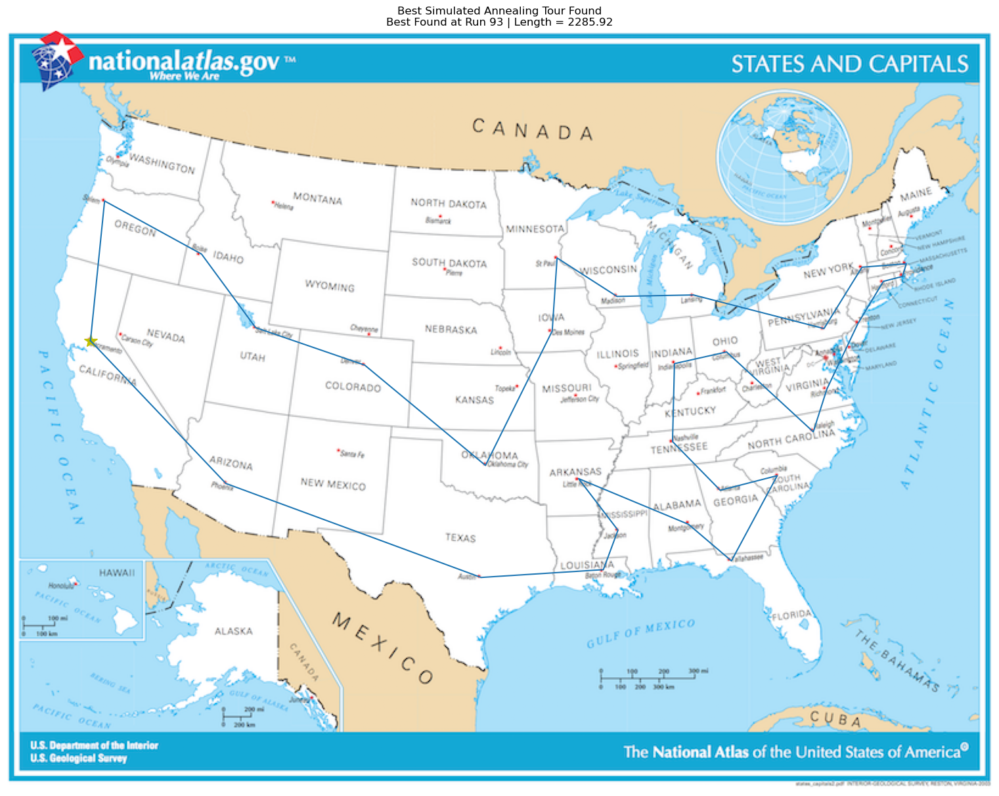

Best Simulated Annealing Tour Path:
('Sacramento', (68.4, 254.0))
('Salem', (80.0, 139.2))
('Boise', (159.6, 182.8))
('Salt Lake City', (204.0, 243.2))
('Denver', (293.6, 274.0))
('Oklahoma City', (392.8, 356.4))
('Des Moines', (447.6, 246.0))
('Saint Paul', (451.6, 186.0))
('Madison', (500.8, 217.6))
('Lansing', (563.6, 216.4))
('Harrisburg', (670.8, 244.0))
('Albany', (702.0, 193.6))
('Boston', (738.4, 190.8))
('Providence', (735.2, 201.2))
('Hartford', (719.6, 205.2))
('Trenton', (698.8, 239.6))
('Richmond', (673.2, 293.6))
('Raleigh', (662.0, 328.8))
('Columbus', (590.8, 263.2))
('Indianapolis', (548.0, 272.8))
('Nashville', (546.4, 336.8))
('Atlanta', (585.6, 376.8))
('Columbia', (632.4, 364.8))
('Tallahassee', (594.8, 434.8))
('Montgomery', (559.6, 404.8))
('Little Rock', (469.2, 367.2))
('Jackson', (501.6, 409.6))
('Baton Rouge', (489.6, 442.0))
('Austin', (389.2, 448.4))
('Phoenix', (179.6, 371.2))

Total tour length = 2285.92


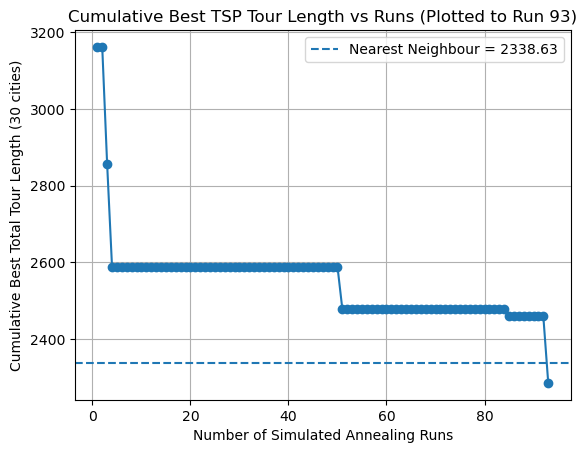

In [63]:
# ============================================================
# REPEATED SA RUNS UNTIL NEAREST NEIGHBOUR IS BEATEN
# ============================================================

"""
Run simulated annealing repeatedly and track the best result across runs,
stopping once the nearest neighbour baseline is beaten (or a hard cap is hit).
"""

# Fixed parameters

num_cities = 30
max_steps_final = 1300
cooling_rate_final = 0.97
initial_temperature_final = 1e4

nearest_neighbour_length = 2338.63   # baseline to beat

runs_num_to_beat = 30
hard_cap_runs = 100 # Ensure the algorithm does not run indefinitely

# Tracking variables

best_so_far = np.inf
best_path_so_far = None
best_run_index = None

best_lengths_so_far = []

beat_run_index = None
beat_length = None

reported_not_beaten_in_30 = False

# Repeat SA until baseline is beaten (or hard cap)

run = 0
while run < hard_cap_runs and beat_run_index is None:
    run += 1

    _, _, path, length = simulated_annealing_tsp(
        initial_path=define_random_path(num_cities=num_cities),
        cooling_function=exponential_cooling,
        cooling_parameters={
            "initial_temperature": initial_temperature_final,
            "cooling_rate": cooling_rate_final
        },
        max_steps=max_steps_final
    )

    # Update best-so-far
    if length < best_so_far:
        best_so_far = length
        best_path_so_far = path
        best_run_index = run

    best_lengths_so_far.append(best_so_far)

    # One-time message at runs_num_to_beat if still not beaten
    if run == runs_num_to_beat and best_so_far >= nearest_neighbour_length and not reported_not_beaten_in_30:
        print(f"Nearest Neighbour Length {nearest_neighbour_length} NOT Beaten Within {runs_num_to_beat} Runs.")
        print("Continuing Until Beaten (or Hard Cap Reached)...")
        reported_not_beaten_in_30 = True

    # Stop once baseline is beaten
    if best_so_far < nearest_neighbour_length:
        beat_run_index = run
        beat_length = best_so_far


# Final reporting

if beat_run_index is None:
    print(
        f"Nearest Neighbour Length {nearest_neighbour_length} NOT Beaten "
        f"after {hard_cap_runs} runs."
    )
    print(f"Best Length Found was {best_so_far:.2f}.")
else:
    print(f"Beaten at Run {beat_run_index}.")
    print(
        f"Best Length when First Beaten: {beat_length:.2f} "
        f"(target {nearest_neighbour_length})."
    )
    print(
        f"Overall Best at Run {best_run_index}: "
        f"{best_so_far:.6g}."
    )

    if best_path_so_far is not None:
        plt.clf()
        show_path(best_path_so_far, best_path_so_far[0])
        plt.title(
            "Best Simulated Annealing Tour Found\n"
            f"Best Found at Run {best_run_index} | Length = {best_so_far:.2f}"
        )
        plt.show()

    print("Best Simulated Annealing Tour Path:")
    for city in best_path_so_far:
        print(city)
    print(f"\nTotal tour length = {best_so_far:.2f}")


# Plot cumulative best length vs run

best_lengths_so_far = np.array(best_lengths_so_far, dtype=float)
final_run = len(best_lengths_so_far)

rounding_step = 5 if final_run <= 35 else 10
plot_upto = int(np.ceil(final_run / rounding_step) * rounding_step)
plot_upto = min(plot_upto, final_run)

run_indices = np.arange(1, plot_upto + 1)

plt.figure()
plt.plot(run_indices, best_lengths_so_far[:plot_upto], marker="o")

plt.axhline(
    nearest_neighbour_length,
    linestyle="--",
    label=f"Nearest Neighbour = {nearest_neighbour_length}"
)

plt.xlabel("Number of Simulated Annealing Runs")
plt.ylabel("Cumulative Best Total Tour Length (30 cities)")
plt.title(f"Cumulative Best TSP Tour Length vs Runs (Plotted to Run {plot_upto})")
plt.grid(True)
plt.legend()
plt.show()


Once the simulated annealing parameters had been tuned, the algorithm was applied to the full 30-city Travelling Salesman Problem, with the smaller 8-city system used during tuning to reduce computational cost. The best Nearest Neighbour tour length was taken as a deterministic baseline, and SA algorithm was then run repeatedly from independent random initial paths until this baseline was beaten. A hard cap was imposed to prevent the algorithm from running indefinitely, and an additional target of outperforming the NN result within 30 SA runs was set, reflecting the fact that the NN algorithm itself had been evaluated from all 30 starting cities.

The results show that simulated annealing does not reliably outperform nearest neighbour in every individual run, but is capable of doing so probabilistically given enough independent restarts. Although the NN baseline was not beaten within the first 30 runs, a substantially shorter tour was found at Run 93, demonstrating SA’s ability to escape the greedy limitations of NN, with the cumulative best-so-far plot highlighting this behaviour explicitly, as can be seen by how SA can make rapid early improvements followed by a long plateau and then a breakthrough.

Overall, this suggests that simulated annealing works best when run repeatedly, with its real strength coming from rare but valuable exploratory successes rather than gradual improvement in each individual run. Nevertheless, a final SA tour length that beat the best NN tour length was found to be 2285.92, and this would be adequate to present as a final SA solution.

#### 2.2.6 Multiple Batches of Simulated Annealing

[Batch 1] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

[Batch 1] Not Beaten After 100 Runs. Best This Batch = 2435.41
[Batch 2] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

[Batch 2] Not Beaten After 100 Runs. Best This Batch = 2384.82
[Batch 3] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

[Batch 3] Not Beaten After 100 Runs. Best This Batch = 2380.31
[Batch 4] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

[Batch 4] Not Beaten After 100 Runs. Best This Batch = 2381.69
[Batch 5] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

[Batch 5] Not Beaten After 100 Runs. Best This Batch = 2456.15
[Batch 6] Nearest Neighbour 2338.63 Not Beaten Within 30 Runs. Continuing...

Nearest Neighbour Beaten in Batch 6, Run 62. Best in Batch = 2310.14

Final Summary:
Nearest Neighbour 2338.63 was Beaten.
Global Best Found: 2310.14 (Batch 6, Run 62)


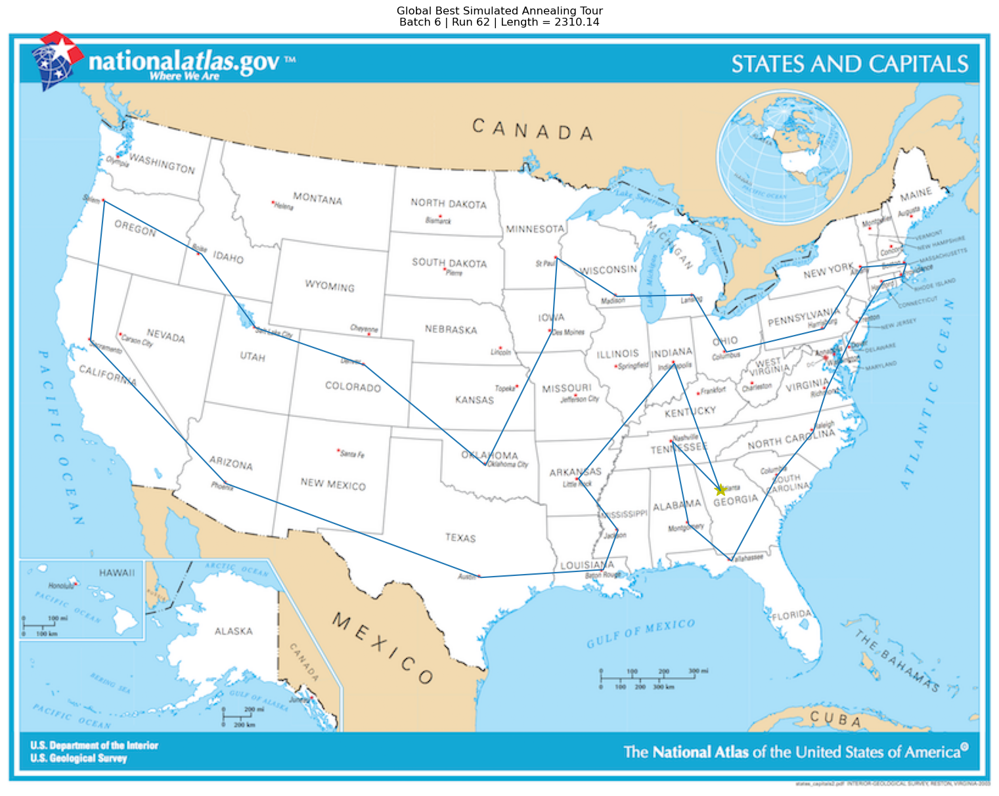

Global Best Simulated Annealing Tour Path:
('Atlanta', (585.6, 376.8))
('Nashville', (546.4, 336.8))
('Montgomery', (559.6, 404.8))
('Tallahassee', (594.8, 434.8))
('Columbia', (632.4, 364.8))
('Raleigh', (662.0, 328.8))
('Richmond', (673.2, 293.6))
('Trenton', (698.8, 239.6))
('Hartford', (719.6, 205.2))
('Providence', (735.2, 201.2))
('Boston', (738.4, 190.8))
('Albany', (702.0, 193.6))
('Harrisburg', (670.8, 244.0))
('Columbus', (590.8, 263.2))
('Lansing', (563.6, 216.4))
('Madison', (500.8, 217.6))
('Saint Paul', (451.6, 186.0))
('Des Moines', (447.6, 246.0))
('Oklahoma City', (392.8, 356.4))
('Denver', (293.6, 274.0))
('Salt Lake City', (204.0, 243.2))
('Boise', (159.6, 182.8))
('Salem', (80.0, 139.2))
('Sacramento', (68.4, 254.0))
('Phoenix', (179.6, 371.2))
('Austin', (389.2, 448.4))
('Baton Rouge', (489.6, 442.0))
('Jackson', (501.6, 409.6))
('Little Rock', (469.2, 367.2))
('Indianapolis', (548.0, 272.8))

Total tour length = 2310.14


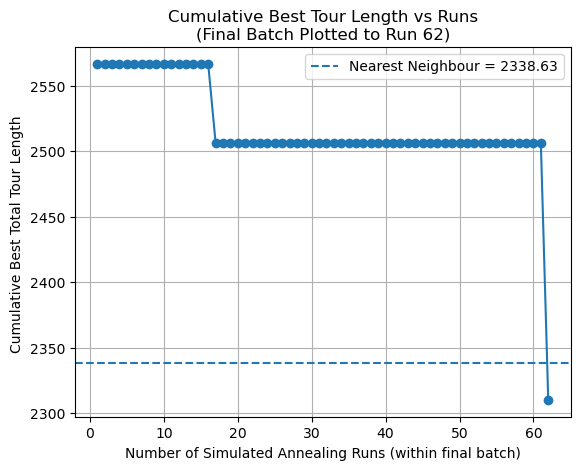

In [66]:
# ============================================================
# SA RESTARTS: MULTIPLE BATCHES UNTIL NN BASELINE IS BEATEN
# ============================================================

"""
Run SA in batches (independent restarts). Track the best tour overall and
stop early if the nearest neighbour baseline is beaten.
Included to demonsrate the extent of SA's probabilistic nature.
"""

# Fixed parameters

num_cities = 30
max_steps_final = 1200
cooling_rate_final = 0.97
initial_temperature_final = 10000

nearest_neighbour_length = 2338.63
runs_num_to_beat = 30
hard_cap_runs = 100

max_batches = 10

# Global best across all batches

global_best_length = np.inf
global_best_path = None
global_best_run = None
global_best_batch = None

nearest_neighbour_beaten = False

# Run batches

for batch in range(1, max_batches + 1):

    # Per-batch best (resets each batch)
    batch_best_length = np.inf
    batch_best_path = None
    batch_best_run = None

    batch_best_lengths_so_far = []

    beat_run_in_batch = None
    reported_not_beaten_in_30 = False

    # Repeated SA runs within this batch
    run = 0
    while run < hard_cap_runs and beat_run_in_batch is None:
        run += 1

        _, _, path, length = simulated_annealing_tsp(
            initial_path=define_random_path(num_cities=num_cities),
            cooling_function=exponential_cooling,
            cooling_parameters={
                "initial_temperature": initial_temperature_final,
                "cooling_rate": cooling_rate_final
            },
            max_steps=max_steps_final
        )

        # Update batch best
        if length < batch_best_length:
            batch_best_length = length
            batch_best_path = path
            batch_best_run = run

        batch_best_lengths_so_far.append(batch_best_length)

        # One-time message at runs_num_to_beat if still not beaten
        if run == runs_num_to_beat and batch_best_length >= nearest_neighbour_length and not reported_not_beaten_in_30:
            print(
                f"[Batch {batch}] Nearest Neighbour {nearest_neighbour_length} Not Beaten Within {runs_num_to_beat} Runs. Continuing..."
            )
            reported_not_beaten_in_30 = True

        # Stop within this batch if baseline beaten
        if batch_best_length < nearest_neighbour_length:
            beat_run_in_batch = run

    # Update global best
    if batch_best_length < global_best_length:
        global_best_length = batch_best_length
        global_best_path = batch_best_path
        global_best_run = batch_best_run
        global_best_batch = batch

    # Stop all batches if beaten
    if beat_run_in_batch is not None:
        nearest_neighbour_beaten = True
        print(
            f"\nNearest Neighbour Beaten in Batch {batch}, Run {beat_run_in_batch}. "
            f"Best in Batch = {batch_best_length:.2f}"
        )
        break
    else:
        print(
            f"\n[Batch {batch}] Not Beaten After {hard_cap_runs} Runs. "
            f"Best This Batch = {batch_best_length:.2f}"
        )

# Print final summary 

print("\nFinal Summary:")

if nearest_neighbour_beaten:
    print(f"Nearest Neighbour {nearest_neighbour_length} was Beaten.")
else:
    print(
        f"Nearest Neighbour {nearest_neighbour_length} was NOT Beaten after {max_batches} Batches "
        f"(total runs = {max_batches * hard_cap_runs})."
    )

print(
    f"Global Best Found: {global_best_length:.2f} "
    f"(Batch {global_best_batch}, Run {global_best_run})"
)


# Plot global best tour

if global_best_path is not None:
    plt.clf()
    show_path(global_best_path, global_best_path[0])
    plt.title(
        "Global Best Simulated Annealing Tour\n"
        f"Batch {global_best_batch} | Run {global_best_run} | Length = {global_best_length:.2f}"
    )
    plt.show()

    print("Global Best Simulated Annealing Tour Path:")
    for city in global_best_path:
        print(city)
    print(f"\nTotal tour length = {global_best_length:.2f}")


# Plot cumulative best within the final batch

batch_best_lengths_so_far = np.array(batch_best_lengths_so_far, dtype=float)
final_run_count = len(batch_best_lengths_so_far)

rounding_step = 5 if final_run_count <= 35 else 10
plot_upto = int(np.ceil(final_run_count / rounding_step) * rounding_step)
plot_upto = min(plot_upto, final_run_count) # Included to make the final plot more readable (rounding to nearest 5 or 10 runs)

run_indices = np.arange(1, plot_upto + 1)

plt.figure()
plt.plot(run_indices, batch_best_lengths_so_far[:plot_upto], marker="o")
plt.axhline(
    nearest_neighbour_length,
    linestyle="--",
    label=f"Nearest Neighbour = {nearest_neighbour_length}"
)

plt.xlabel("Number of Simulated Annealing Runs (within final batch)")
plt.ylabel("Cumulative Best Total Tour Length ")
plt.title(
    "Cumulative Best Tour Length vs Runs\n"
    f"(Final Batch Plotted to Run {plot_upto})"
)
plt.grid(True)
plt.legend()
plt.show()

In this final stage, SA was run in structured batches, with each batch consisting of multiple independent restarts from random tours. The NN solution was used as a fixed reference, and each batch was allowed to terminate early if this baseline was beaten, while a hard cap ensured the total computation remained bounded; tracking both the best result within each batch and the global best across all batches avoided over-interpreting any single favourable run and provided a clearer picture of how SA behaved in practice.
<br>
<br>
The results showed that SA could beat the NN solution, but not in a smooth or consistent manner. The cumulative best-so-far plot revealed a long plateau where many runs converged to similar suboptimal solutions, supporting the idea discussed previously that SA often became trapped in local minima before making a breakthrough. In fact, a clear improvement only occurred in the 6th batch where the NN baseline was finally beaten, further confirming how SA’s effectiveness depended on repeated runs and persistence, rather than guaranteed improvement in every individual run. One could attempt to tune the SA parameters further (such as by exploring greater resolutions), but ultimately solutions have been found that beat the NN baseline with the current parameters so they are sufficient. 
<br>
<br>
A final note is that whilst this section of code introduces another for loop that significantly increases the time complexity, it is equivalent to rerunning the previous section of code repeatedly until the NN baseline is beaten; this batch representation was only to fully emphasise the probabilistic nature of SA, and that by chance the previous SA solution was obtained. 

### 2.3 Genetic Algorithm

Genetic Algorithms (GA) take inspiration from a concept from biology – evolution. Natural 
selection is a force that drives evolution, and nature’s problem is to find the optimal 
combinations of traits that allow an organism to survive and reproduce by utilising this force to put 
different sets of traits in competition with each other, ultimately choosing the best combinations. GA 
function in a similar manner by pitting different solutions against each other and using selection 
to evolve them into the best solution (McKee, 2024).

The algorithm begins by creating a population of candidate solutions, where each solution is represented by a chromosome — typically a sequence of values (genes) that encodes a possible solution to the problem (this would be the possible tours). These chromosomes are generated randomly within the problem constraints (achievable using the SA random path function) and are then evaluated using a fitness function that assigns a score based on how good each solution is (in this case the distance metric established previously). Through selection methods such as roulette-wheel selection, tournament selection, or stochastic universal sampling (SUS), reproduction is biased towards better performing chromosomes while still preserving diversity, meaning solutions with higher fitness (or tours with shorter lengths) are more likely to be chosen as parents. Selected parents can then undergo crossover, where parts of their genetic material are combined to create new offspring, enabling the inheritance of useful features from different solutions. Additionally, mutation is applied by making small random changes to the genes to help prevent premature convergence and enable exploration of new solutions. The resulting offspring form a new generation that replaces the old population, with this process repeating over many generations to gradually improve the solution quality until the algorithm terminates once a stopping condition is met, such as reaching a maximum number of generations or convergence. The best chromosome found can then be returned as the final solution 
(GeeksforGeeks, 2017).

The foundations of GA were first formally developed by John Holland in the 1960s and 1970s, 
who introduced the idea of applying principles of natural selection and genetics to optimisation 
and search problem (Hayes-Roth, 1975).

#### 2.3.1 Initial Implementation of the Genetic Algorithm Heuristic

In [ ]:
# ============================================================
# INITIAL POPULATION + FITNESS EVALUATION
# ============================================================

def generate_initial_population(population_size, number_of_cities):
    """
    Generate a population of random TSP tours.
    """
    return [
        define_random_path(num_cities=number_of_cities)
        for _ in range(population_size)
    ]


def evaluate_population(tours):
    """
    Compute tour lengths for a population (lower = better).
    """
    return np.array([
        calculate_total_path_length(tour)
        for tour in tours
    ])

Firstly, two helper functions were defined that were used to support the Genetic Algorithm (GA), with the initial population created by generating a set of random, valid TSP tours using the define_random_path function used in the SA heuristic; this ensured diversity at the start of the search and avoiding any built-in bias toward particular structures. The population evaluation step then computed the total tour length for each candidate solution using the same distance metric as the rest of the project, with shorter tours corresponding to fitter individuals in the GA framework.

In [ ]:
# ============================================================
# ELITISM + TOURNAMENT SELECTION
# ============================================================

def get_elite_tours(tours, tour_lengths, elite_size):
    """
    Preserve the best-performing tours unchanged.
    """

    # Indices of the shortest tours
    elite_indices = np.argsort(tour_lengths)[:elite_size]

    # Copy elites to avoid modifying originals
    elite_tours = [tours[i].copy() for i in elite_indices]

    return elite_tours, elite_indices


def tournament_selection(tours, tour_lengths, tournament_size):
    """
    Select one parent using tournament selection.
    """

    population_size = len(tours)

    # Randomly sample competitors
    competitor_indices = random.sample(
        range(population_size),
        tournament_size
    )

    # Keep the shortest tour among competitors
    best_index = competitor_indices[0]
    for idx in competitor_indices[1:]:
        if tour_lengths[idx] < tour_lengths[best_index]:
            best_index = idx

    return tours[best_index].copy()

Elitism was implemented to ensure that the best tours found so far were carried straight into the next generation without any changes, protecting strong solutions from being lost due to randomness in crossover or mutation. Furthermore, the implementation of tournament selection was used to pick parents in a simple and intuitive manner by choosing a small group of tours at random, and selecting the best one from that group as a parent; this meant that shorter tours were favoured whilst still allowing some randomness to ensure that the algorithm kept exploring new solutions instead of getting stuck too early.

In [69]:
# ============================================================
# GENETIC OPERATORS: CROSSOVER AND MUTATION
# ============================================================

def order_crossover_one_cut(parent_a, parent_b, number_of_cities):
    """
    Create a valid child tour using a one-cut order crossover.
    A prefix is taken from parent_a, and the remaining cities are filled
    in using the order from parent_b (skipping duplicates).
    """

    # Choose a non-trivial cut point
    cut_index = random.randint(1, number_of_cities - 2)

    # Copy prefix from parent A
    child = parent_a[:cut_index]

    # Fill remaining cities using parent B's order
    for city in parent_b:
        if city not in child:
            child.append(city)

    return child


def mutate_pairwise_swap(tour):
    """
    Apply a simple swap mutation by exchanging two cities.
    """
    return perform_pairwise_swap(tour)


def make_child(
    parent_a,
    parent_b,
    number_of_cities,
    crossover_probability,
    mutation_probability
):
    """
    Generate a single child tour using probabilistic crossover and mutation.
    """

    # Optional crossover
    if random.random() < crossover_probability:
        child = order_crossover_one_cut(parent_a, parent_b, number_of_cities)
    else:
        child = parent_a.copy()

    # Optional mutation
    if random.random() < mutation_probability:
        child = mutate_pairwise_swap(child)

    return child

New tours were created and modified in the GA through the crossover function combining two parent tours by taking an initial segment from one parent and then filling in the remaining cities using the order from the other parent; this preserved valid tours (as each city appeared exactly once) whilst allowing useful structures from both parents to be passed on to the next generation. Additionally, mutation was implemented as a pairwise swap (reused from the SA algorithm) to introduce small, random changes that helped maintain diversity in the population and reduced the risk of the algorithm becoming trapped in a poor solution too early. Lastly, the make_child function combined these two together, with the crossover and mutation applied probabilistically such that not every child underwent both operations. This balance enabled the algorithm to build on good existing solutions whilst still introducing enough variation to explore new possibilities - this was crucial for avoiding stagnation and improving solution quality over time.

In [70]:
# ============================================================
# ELITISM + REPRODUCTION
# ============================================================

def build_next_population(
    current_population,
    current_lengths,
    elite_size,
    tournament_size,
    crossover_probability,
    mutation_probability,
    number_of_cities
):
    """
    Build the next population using elitism, then fill the rest using
    selection + crossover + mutation.
    """

    # Start with elites
    next_population, _ = get_elite_tours(
        current_population,
        current_lengths,
        elite_size
    )

    # Fill remaining slots
    while len(next_population) < len(current_population):

        parent_1 = tournament_selection(
            current_population,
            current_lengths,
            tournament_size
        )
        parent_2 = tournament_selection(
            current_population,
            current_lengths,
            tournament_size
        )

        child = make_child(
            parent_1,
            parent_2,
            number_of_cities,
            crossover_probability,
            mutation_probability
        )

        next_population.append(child)

    return next_population

This function built a new GA generation in two stages, with the first copying a small set of the best tours unchanged using elitism, such that the strongest solutions found so far were guaranteed to survive; the rest of the population was then filled by repeatedly selecting two parents via tournament selection and producing a child using crossover and (optionally) mutation. Ultimately, it was designed to keep progress via elites whilst still generating fresh candidates each generation so that the population could improve without losing diversity too quickly.

Best Tour Length Found by the Genetic Algorithm: 2576.49
Best Tour Found by the Genetic Algorithm:
['Indianapolis', 'Hartford', 'Providence', 'Boston', 'Albany', 'Lansing', 'Madison', 'Saint Paul', 'Des Moines', 'Little Rock', 'Jackson', 'Oklahoma City', 'Denver', 'Salt Lake City', 'Boise', 'Salem', 'Sacramento', 'Phoenix', 'Austin', 'Baton Rouge', 'Tallahassee', 'Montgomery', 'Columbus', 'Harrisburg', 'Trenton', 'Richmond', 'Raleigh', 'Columbia', 'Atlanta', 'Nashville']


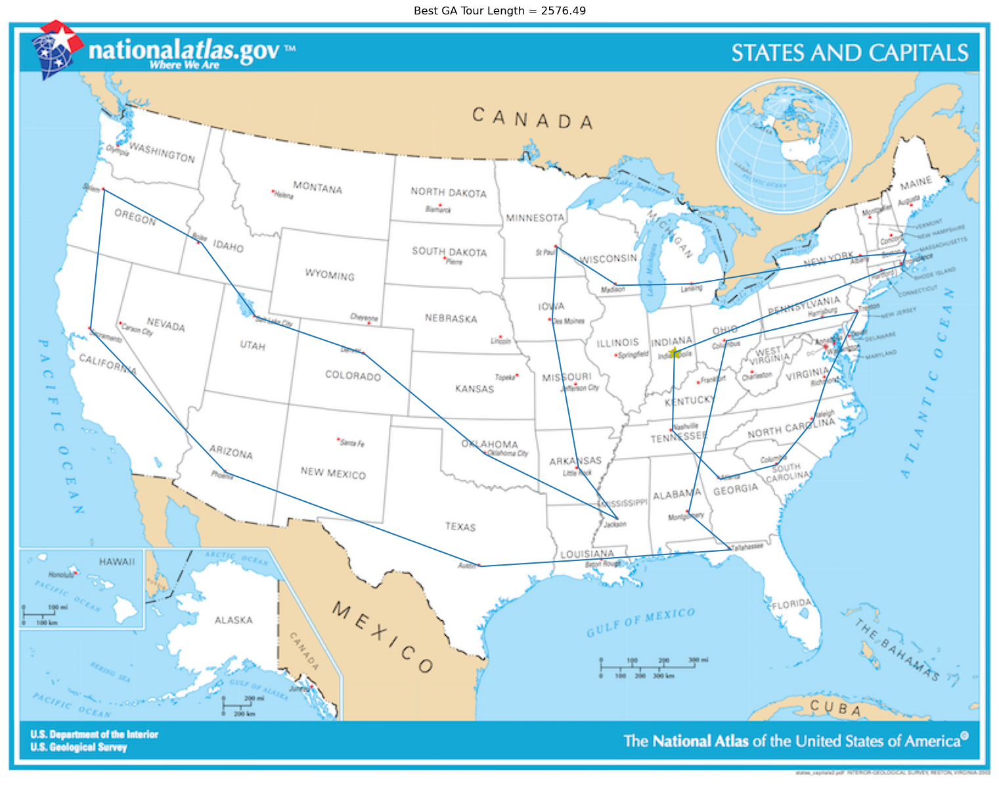

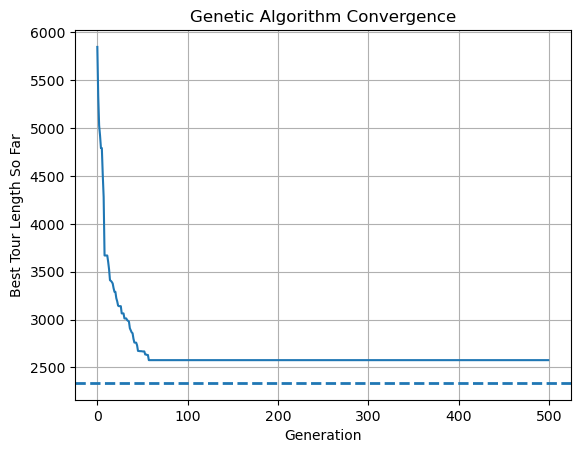

In [ ]:
# ============================================================
# GENETIC ALGORITHM HEURISTIC
# ============================================================

def genetic_algorithm_tsp(
    population_size=200,
    number_of_generations=500,
    crossover_probability=0.9,
    mutation_probability=0.2,
    elite_size=5,
    tournament_size=5
):
    """
    Run a genetic algorithm to search for a short TSP tour.
    Returns the best tour, its length, and the best-length history.
    """

    number_of_cities = len(capitals_list)

    # Initial population
    population = generate_initial_population(
        population_size=population_size,
        number_of_cities=number_of_cities
    )

    # Best-so-far tracking
    best_tour = None
    best_length = np.inf
    best_length_history = []

    # Evolve over generations
    for generation in range(number_of_generations):

        # Evaluate current population
        tour_lengths = evaluate_population(population)

        # Best in this generation
        gen_best_index = int(np.argmin(tour_lengths))
        gen_best_length = float(tour_lengths[gen_best_index])

        # Update global best
        if gen_best_length < best_length:
            best_length = gen_best_length
            best_tour = population[gen_best_index].copy()

        best_length_history.append(best_length)

        # Next generation
        population = build_next_population(
            current_population=population,
            current_lengths=tour_lengths,
            elite_size=elite_size,
            tournament_size=tournament_size,
            crossover_probability=crossover_probability,
            mutation_probability=mutation_probability,
            number_of_cities=number_of_cities
        )

    return best_tour, best_length, best_length_history

# ============================================================
# TEST GENETIC ALGORITHM HEURISTIC
# ============================================================

best_tour_ga, best_length_ga, best_length_history_ga = genetic_algorithm_tsp()
nearest_neighbour_length_to_beat = 2338.63

# Final results

print("Best Tour Length Found by the Genetic Algorithm:", f"{best_length_ga:.2f}")
print("Best Tour Found by the Genetic Algorithm:")
print([city[0] for city in best_tour_ga])

# Plot best tour on map

plt.clf()
show_path(best_tour_ga, best_tour_ga[0])
plt.title(f"Best GA Tour Length = {best_length_ga:.2f}")
plt.show()

# Plot convergence history

plt.figure()
plt.plot(best_length_history_ga)
plt.axhline(
    y=nearest_neighbour_length_to_beat,
    linestyle="--",
    linewidth=2,
    label=f"Target = {nearest_neighbour_length_to_beat}"
)
plt.xlabel("Generation")
plt.ylabel("Best Tour Length So Far")
plt.title("Genetic Algorithm Convergence")
plt.grid(True)
plt.show()

This function ran the full GA by starting from a population of random tours and evolving it over many generations. In each generation, all tours were evaluated, the best solution found so far was updated, and its length was recorded so convergence could be analysed later; new generations were built by keeping a small number of the best tours unchanged and filling the rest of the population using selection, crossover, and occasional mutation. 

Finally, the algorithm was run once, the best tour found was printed and plotted, and the convergence history was visualised. The GA improved very quickly from a poor starting population, with most of the progress happening in the early generations. The steep drop at the start of the convergence plot showed that selection and crossover were effective at rapidly discarding bad tours and combining better ones. After this initial phase, the curve flattened, indicating that the population had largely settled into a stable set of similar solutions and further improvement became difficult.
The best tour found had a length of 2576.49, which was not close to the NN result and also did not outperform the best SA solution; this suggested that despite making fast, large improvements, the GA eventually became stuck due to a loss of diversity in the population. Overall, the results portray that the GA was strong at early exploration and global improvement, but stagnated later on without additional mechanisms to reintroduce variation, demonstrating that like the SA algorithm it is susceptible to stochaistic effects.

#### 2.3.2 Multiple Runs of the Genetic Algorithm

Nearest Neighbour 2338.63 Beaten on GA Run #7: 2202.91


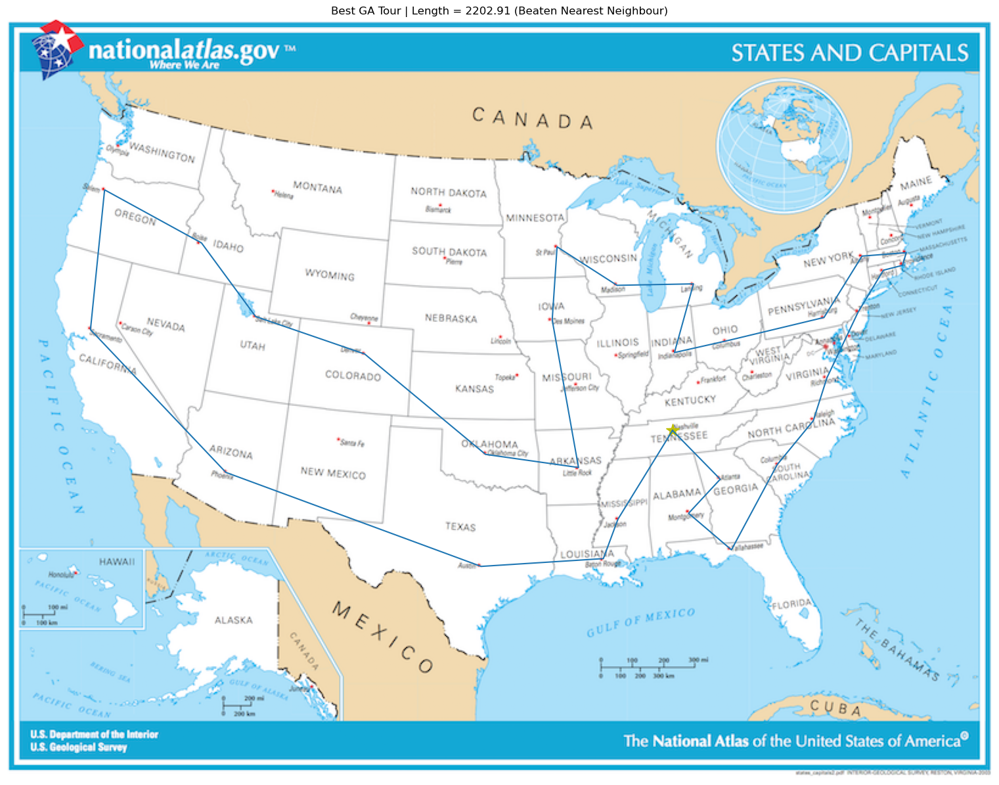

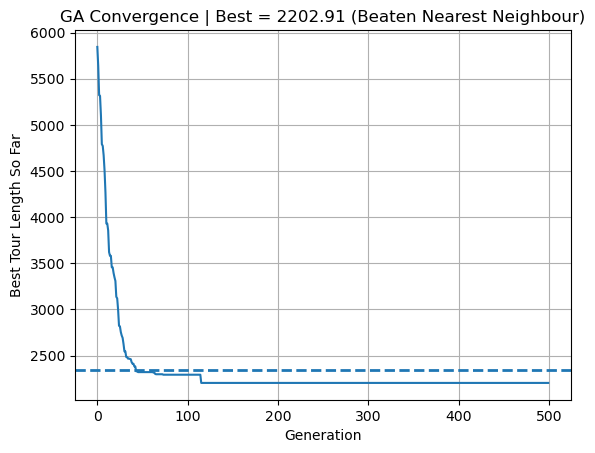

In [77]:
# ============================================================
# GA MULTI-RUN (BEAT NN BASELINE + TRACK BEST)
# ============================================================

nearest_neighbour_length_to_beat = 2338.63  # baseline to beat

runs_num_to_beat = 30
hard_cap_ga_runs = 100 # Ensure the algorithm does not run indefinitely


# Track best across all runs

best_overall_length = np.inf
best_overall_tour = None
best_overall_run = None
best_overall_length_history = None

# Track first run that beats nearest neighbour

beaten_run = None
beaten_length = None
beaten_tour = None
beaten_length_history = None

# Repeat GA runs until target is beaten (or hard cap)

run = 0
while run < hard_cap_ga_runs and beaten_run is None:
    run += 1

    # New seed each run (independent restart)
    seed = 1000 + run
    random.seed(seed)
    np.random.seed(seed)

    best_tour, best_length, best_length_history = genetic_algorithm_tsp(
        population_size=200,
        number_of_generations=500,
        crossover_probability=0.9,
        mutation_probability=0.2,
        elite_size=5,
        tournament_size=5
    )

    # Update overall best
    if best_length < best_overall_length:
        best_overall_length = best_length
        best_overall_tour = best_tour
        best_overall_run = run
        best_overall_length_history = best_length_history

    # Stop once NN baseline is beaten
    if best_length < nearest_neighbour_length_to_beat:
        beaten_run = run
        beaten_length = best_length
        beaten_tour = best_tour
        beaten_length_history = best_length_history
        break

    # One-time message at max_ga_runs if still not beaten
    if run == runs_num_to_beat:
        print(
            f"Nearest Neighbour {nearest_neighbour_length_to_beat} NOT Beaten Within "
            f"{runs_num_to_beat} GA Runs. Continuing..."
        )

# Report outcome

if beaten_run is not None:
    print(
        f"Nearest Neighbour {nearest_neighbour_length_to_beat} Beaten "
        f"on GA Run #{beaten_run}: {beaten_length:.2f}"
    )
else:
    print(
        f"Nearest Neighbour {nearest_neighbour_length_to_beat} NOT Beaten in "
        f"{hard_cap_ga_runs} GA Runs."
    )
    print(f"Best Achieved was {best_overall_length:.2f} on GA Run #{best_overall_run}.")


# Choose which run to plot

best_tour_ga = beaten_tour if beaten_run is not None else best_overall_tour
best_length_ga = beaten_length if beaten_run is not None else best_overall_length
best_length_history_ga = (
    beaten_length_history if beaten_run is not None else best_overall_length_history
)

status_label = "Beaten Nearest Neighbour" if beaten_run is not None else "Overall Best"


# Plot best tour on map

plt.clf()
show_path(best_tour_ga, best_tour_ga[0])
plt.title(f"Best GA Tour | Length = {best_length_ga:.2f} ({status_label})")
plt.show()


# Plot convergence history for the chosen best run

plt.figure()
plt.plot(best_length_history_ga)
plt.axhline(
    y=nearest_neighbour_length,
    linestyle="--",
    linewidth=2,
    label=f"Target = {nearest_neighbour_length}"
)
plt.xlabel("Generation")
plt.ylabel("Best Tour Length So Far")
plt.title(f"GA Convergence | Best = {best_length_ga:.2f} ({status_label})")
plt.grid(True)
plt.show()


Like with the SA algorithm, this section repeated the genetic algorithm as a set of independent restarts to test whether it could reliably beat the Nearest Neighbour baseline, rather than judging it from a single run. Each GA run used a different random seed so that the initial population and genetic operations were varied, and the best tour length from each run was compared against the NN baseline. Alongside this, the best result seen across all runs was tracked, so the experiment still produced a meaningful 'best achieved' outcome even if the baseline was never beaten.

The loop stopped as soon as a run produced a tour shorter than the NN baseline, with a hard cap in place to prevent the algorithm from running indefinitely. After the search finished, the code reported either the first run that beat NN or the overall best run if NN was not beaten, and finally, the chosen best tour was plotted on the map and its convergence history was displayed for further analysis.

The genetic algorithm did manage to beat the NN baseline, finding a tour of length 2202.91 on run 7, which was a clear improvement over the NN result. The resulting route looked more sensible overall, with fewer long, inefficient jumps that were seen in the NN maps, suggesting that the GA successfully combined good parts of different tours into a stronger global solution.

Furthermore, the convergence plot revealed that most of the progress happened very early on, with tour length dropping sharply in the first few generations, with the improvements slowing down noticeably and the curve flattening after the NN baseline was crossed, indicating that the population had settled into a stable set of similar solutions.

Overall, this showed that the genetic algorithm could outperform the greedy NN approach, but not in a smooth or guaranteed way. Its success relied on randomness and multiple runs (with this result taking 7 runs to obtain), with strong results appearing occasionally rather than consistently improving in every run - very similar in fashion to the simulated annealing algorithm. However, it is essential to consider other factors such as runtime, as the genetic algorithm takes significantly longer to run than the simulated annealing algorithm.

### 2.4 Other Extensions to the Travelling Salesman Problem

This report explored finding the typical TSP of finding the shortest tour lengths, however, the algorithms implemented are powerful in that they can be extended to other scenarios, for instance finding the longest tour length instead. For the Nearest Neighbour heuristic, this can be achieved by changing the minimum condition when performing the greedy selection to a maximum to select the farthest unvisited city instead. For the Simulated Annealing Heuristic, one would want the change in length to be greater than 0 for improvement as well as reverse the sign in the acceptance probability as seen in Equation 3 to achieve maximisation.
$$
P(\text{accept}) = \exp\!\left(\frac{\Delta E}{T}\right)
\tag{3}
$$ 
The Genetic Algorithm simply requires redefining fitness as the tour length itself and selecting individuals with larger lengths instead of smaller ones during tournament selection and elitism, thereby turning the optimisation from minimisation to maximisation.

One could also consider how the algorithms would need to be modified to avoid crossing the country transversally as much as possible in the winter time (due to snow conditions resulting in frequent road closures in the central states); this would entail modifying the cost/fitness function so crossing the country becomes undesirable. In the case of the NN algorithm, this would alter the distance so that large east–west jumps are heavily penalised, meaning the greedy choice would naturally avoid crossing the country because those moves would appear “longer” and less attractive. As for the SA algorithm, adding a penalty would mean that due to the algorithm's nature of minimising the total cost, it would  gradually favour routes that stayed within regions and avoid transversal crossings. For the GA, modifying the fitness function to have a penalty would mean that solutions crossing the central states would have a worse fit, such that over generations the population would evolve towards more regional, winter-safe routes. This sort of problem could be likened to navigation apps rerouting to avoid tolls or traffic. 

In relation to these, there are other variations of the TSP that could be explored, such as the Asymmetric Travelling Salesman Problem (ATSP) where the cost to travel from city A to B is not necessarily the same as from B to A, often due to one-way streets, traffic, or different flight costs for instance (Gilbert, 2015). The Multiple Travelling Salesman Problem (MTSP) is another extension that can be explored, involving assigning multiple salesmen to visit a set of targets from a common depot, with each target visited exactly once while minimising the total tour length. (Singh, Deka and Sundar, 2024)

## 3. Tacoma Bridge Is Falling Down: A Study of Structural Instability

Numerical modelling has enabled complex differential equations to be approximated and analysed when exact analytical solutions are not possible, proving to be crucial in the investigation of one of "the most dramatic failure in bridge engineering history" (Washington State Department of Transportation, n.d.): this was none other than the Tacoma Narrows Bridge. 

Opened on 1st July 1940 in Washington State, the two-lane bridge was the third-longest suspension bridge in the world, and despite being hailed as a “triumph of structural engineering” (Newspapers.com, 1940), it quickly earned the nickname “Galloping Gertie” after locals noticed how it heaved and undulated even in gentle winds. Four months later, the bridge twisted apart and collapsed into the Puget Sound below on the morning of November 7th, 1940, after experiencing sustained winds of roughly 40 miles per hour (Channel, 2024). Eyewitness accounts described the bridge prior to this event as starting a “lateral twisting motion, in addition to the vertical wave”, with comments that “the main span was rolling wildly; the deck was tipping from the horizontal to an angle approaching forty-five degrees” (www.wsdot.wa.gov, n.d.) – Figure 3 demonstrates the extent of this behaviour.  


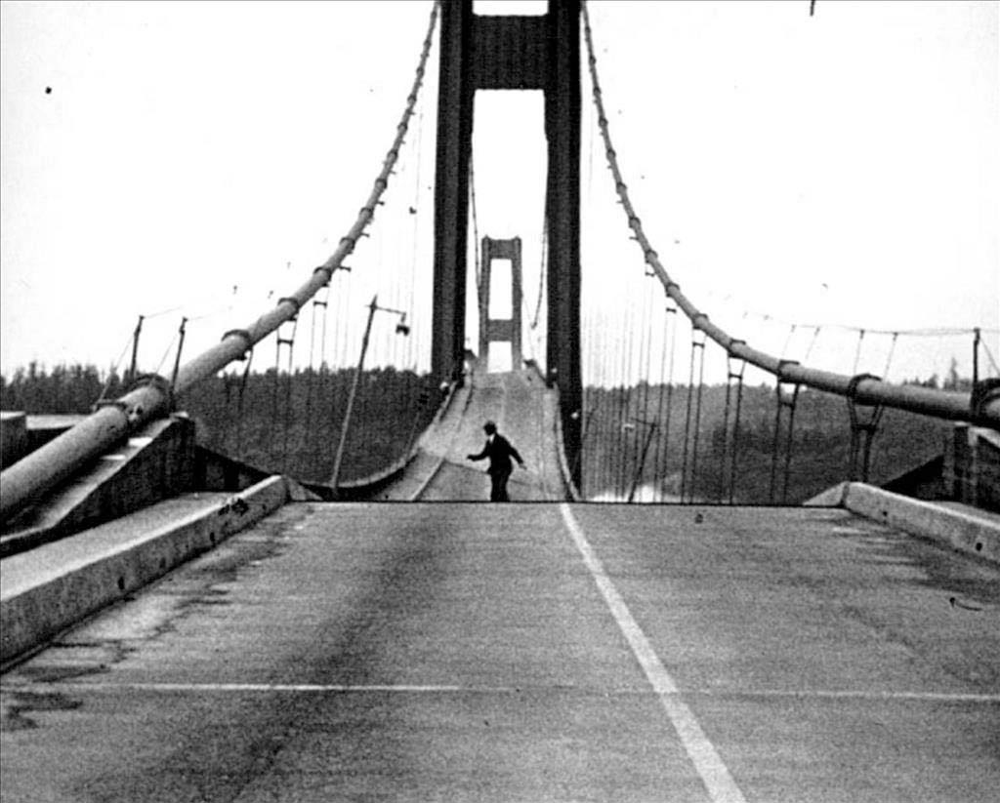

In [101]:
Image(filename='Howard_Clifford_Tacoma.png')

*Figure 3: Howard Clifford running off the Tacoma Narrows Bridge during its collapse, 7 November 1940 (Bashford, 1940).*

To this day, the event has been extensively studied by both scientists and engineers, with several explanations initially proposed for the bridge’s violent oscillations, in particular considering resonance arising when an external driving force matched the bridge’s natural frequency. However, it is now widely accepted that aeroelastic flutter was the culprit, due to the generation of vortices by high-speed winds being diverted above and below the roadway, producing a growing vertical force that drove the oscillatory motion of the bridge itself. (Masters, 2017)

One could model this by simplifying the bridge to be a suspended roadway supported by two cables, as seen in Figure 4; the variation of the two parameters of the vertical displacement $y$ and the torsional angle $\theta$ could then be investigated by constructing two equations to model each variable based on the forces affecting them; in particular, this would be the interaction between the gravitational force and the restoring forces on the bridge. 

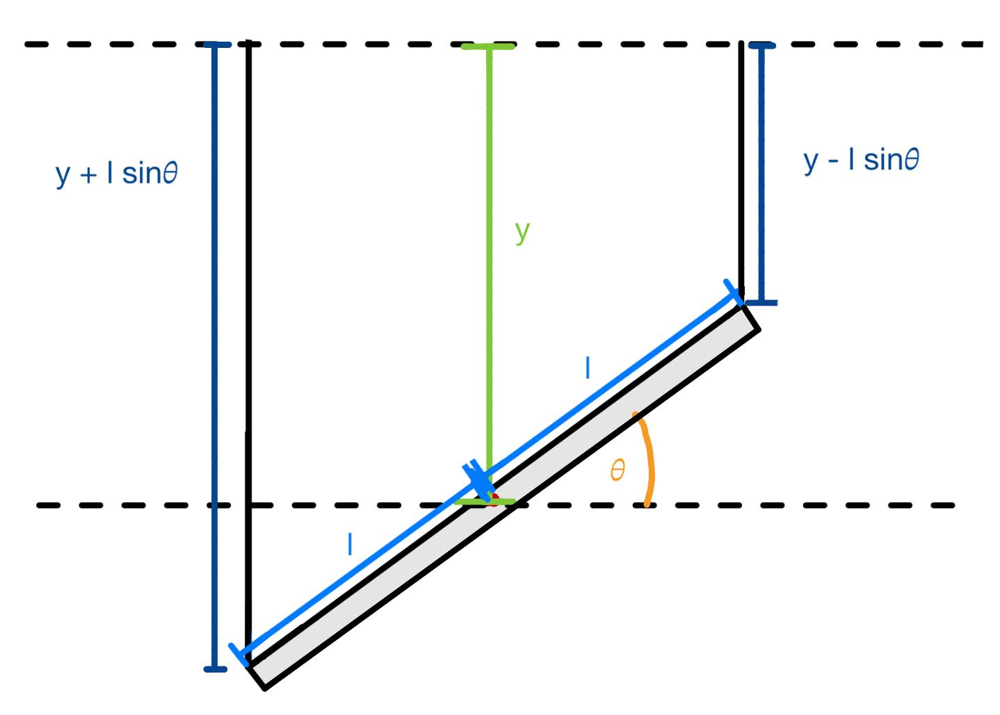

In [98]:
Image(filename='Tacoma_Diagram.png')

*Figure 4: A diagram modelling the Tacoma Bridge as a rod suspended by two wires, where $y$ is the vertical displacement and $\theta$ is the torsional angle*

Initial treatment could model the cables in accordance with Hooke’s law (Equation 4), leading to a linear response where the restoring force of the cables is proportional to the displacement. 

$$
F = -ky
\tag{4}
$$

Where:

- $ F $ is the restoring force (N)  
- $ k $ is the spring constant (N / m)  
- $ y $ is the extension or compression from equilibrium (m)

However, this report investigates a different approach based on the belief of McKenna and Tuama that the cables would in reality show more resistance on compression (so create a smaller restoring force) than when extended (McKenna and Tuama, 2001), as modelled by Equation 5.

$$
F(y) = \frac{K}{a}\left(e^{ay} - 1\right)
\tag{5}
$$

Where

- $a$ is the force parameter ($\text{m}^{-1}$)
- $K$ is the spring constant (N / m)  

The equations of motion could then be constructed through considering Equation 5 and Newton's law of gravitation, such that by also considering the geometry observed in Figure 4, the vertical components of the restoring force could be obtained using trigonometry, resulting in Equations 6 and 7 to model the system. 

$$
y'' = -d\,y' - \frac{K}{Ma}
\left(
e^{a(y - l\sin(\theta))}
+
e^{a(y + l\sin(\theta))} - 2
\right)
\tag{6}
$$

$$
\theta'' = -d\,\theta'
+ \frac{3\cos(\theta)}{l}\,\frac{K}{Ma}
\left(
e^{a(y - l\sin(\theta))}
-
e^{a(y + l\sin(\theta))}
\right)
\tag{7}
$$

However, the model was yet to incorporate wind, which was highly significant in contribution to the motion of the bridge as the vertical force was influenced by the aerostatic flutter mechanism; Equation 8 shows how the wind term was modelled. 

$$
F_{\text{wind}} = M A \sin(\omega t)
\tag{8}
$$

Where

- $\omega$ is the wind frequency ($\text{rad s}^{-1}$)
- $A$ is the forcing amplitude parameter ($\text{m s}^{-2}$)

With the sinusoidal form of this force capturing the periodic variation in wind strength and direction within the model, the final system equations could be obtained that governed the motion of the bridge.

$$
\ddot{y}
= -d\,\dot{y}
- \frac{K}{M a}
\left[
e^{a(y - l\sin\theta)}
+ e^{a(y + l\sin\theta)} - 2
\right]
+ \frac{A}{M}\sin(\omega t)
\tag{9}
$$

$$
\ddot{\theta}
= -d\,\dot{\theta}
+ \frac{3\cos\theta}{l}\,
\frac{K}{M a}
\left[
e^{a(y - l\sin\theta)}
- e^{a(y + l\sin\theta)}
\right]
\tag{10}
$$

Whilst Equations 9 and 10 correctly described the two parameters of the bridge, they were second order differential equations so needed to be reformulated into a form that was more amenable for numerical analysis:

$$
\frac{dy}{dt} = z
\tag{11}
$$

$$
\frac{dz}{dt}
= -d\,z
- \frac{K}{M a}
\left[
e^{a(y - l\sin\theta)} 
+ e^{a(y + l\sin\theta)} - 2
\right]
+ \frac{A}{M}\sin(\omega t)
\tag{12}
$$

$$
\frac{d\theta}{dt} = \gamma
\tag{13}
$$

$$
\frac{d\gamma}{dt}
= -d\,\gamma
+ \frac{3\cos\theta}{l}\,
\frac{K}{M a}
\left[
e^{a(y - l\sin\theta)}
- e^{a(y + l\sin\theta)}
\right]
\tag{14}
$$

By converting these second order differential equations into first order differential equations, Taylor's method could be utilised to obtain analytical solutions; the derivative is known at each point but not the function in a differential equation, so the function can be estimated between two points. For a given starting point, an algorithm can be iterated that is described by Equation 15 (also known as Euler's method) such that the shape of the function can be approximated with the number of obtained points depending on the step size $h$ chosen.

$$
y_{i+1} = y_i + h f(x_i, y_i)
\tag{15}
$$

A modified version of this is known as the Euler-Cromer method, that takes the form seen in Equation 16 and differs from the standard Euler approach in that it evaluates the derivative using the updated value at the next step instead.

$$
y_{i+1} = y_i + h f(x_{i+1}, y_{i+1})
\tag{16}
$$

Using these two methods in conjunction with Equations 11-14, one can perform the analysis of the relationship between the vertical displacement and the torsional angle through the variation of many other variables such as wind frequency or wind amplitude for the Tacoma Narrows, testing McKenna and Tuama's hypothesis as is done in this report.

### 3.1 McKenna-Tuama Tacoma Model Investigation

#### 3.1.1 Unforced Model Implementation

In [ ]:
# ============================================================
# MODEL PARAMETERS AND PHYSICAL CONSTANTS
# ============================================================


start_time = 0.0      # Start time (s)
end_time   = 100.0    # End time (s)

friction_coefficient = 0.01   # Linear damping coefficient
force_parameter      = 1.0    # Forcing scale (model parameter)

mass_of_bridge_segment  = 2500.0    # Segment mass (kg)
spring_constant         = 10000.0   # Effective stiffness (N m^-1)
width_of_bridge_segment = 6.0       # Deck width (m)

This section defined the model parameters used in the bridge simulation, which were specified in advance to keep the system well controlled and easy to interpret, as well enable them to be easily adjusted if other values wanted to be investigated. The values were physically reasonable but idealised, and were not intended to represent exact measurements from the real Tacoma Narrows Bridge.

In [78]:
# ============================================================
# TACOMA BRIDGE MODEL (NO WIND)
# ============================================================

"""
Nonlinear vertical–torsional bridge model with no external forcing.
"""

def tacoma_no_wind(
    time_step=0.01,
    use_euler_cromer=True,
    initial_vertical_displacement=0.0,
    initial_torsional_angle=0.0,
    initial_vertical_velocity=0.0,
    initial_torsional_velocity=0.0
):
    """
    State arrays:
      y, θ, y_dot, θ_dot

    Returns arrays:
      time_array, torsional_angle, vertical_displacement
    """

    # Time grid
    time_array = np.arange(start_time, end_time + time_step, time_step)
    num_steps = len(time_array)

    # State arrays
    vertical_displacement = np.zeros(num_steps)   # y
    torsional_angle = np.zeros(num_steps)         # θ
    vertical_velocity = np.zeros(num_steps)       # y_dot
    torsional_velocity = np.zeros(num_steps)      # θ_dot

    # Grouped constant: K / (M * a)
    stiffness_coefficient = spring_constant / (
        mass_of_bridge_segment * force_parameter
    )

    # Initial conditions
    vertical_displacement[0] = initial_vertical_displacement
    torsional_angle[0] = initial_torsional_angle
    vertical_velocity[0] = initial_vertical_velocity
    torsional_velocity[0] = initial_torsional_velocity

    # Time stepping
    for n in range(num_steps - 1):

        l_sin_theta = width_of_bridge_segment * np.sin(torsional_angle[n])

        exp_lower = np.exp(
            force_parameter * (vertical_displacement[n] - l_sin_theta)
        )
        exp_upper = np.exp(
            force_parameter * (vertical_displacement[n] + l_sin_theta)
        )

        # Accelerations

        vertical_acceleration = (
            -friction_coefficient * vertical_velocity[n]
            - stiffness_coefficient * (exp_lower + exp_upper - 2.0)
        )

        torsional_acceleration = (
            -friction_coefficient * torsional_velocity[n]
            + (3.0 * np.cos(torsional_angle[n]) / width_of_bridge_segment)
            * stiffness_coefficient
            * (exp_lower - exp_upper)
        )

        # Euler–Cromer or Euler - Euler-Cromer by default
        
        if use_euler_cromer:
            vertical_velocity[n + 1] = (
                vertical_velocity[n] + time_step * vertical_acceleration
            )
            torsional_velocity[n + 1] = (
                torsional_velocity[n] + time_step * torsional_acceleration
            )

            vertical_displacement[n + 1] = (
                vertical_displacement[n]
                + time_step * vertical_velocity[n + 1]
            )
            torsional_angle[n + 1] = (
                torsional_angle[n]
                + time_step * torsional_velocity[n + 1]
            )

        else:
            vertical_displacement[n + 1] = (
                vertical_displacement[n]
                + time_step * vertical_velocity[n]
            )
            torsional_angle[n + 1] = (
                torsional_angle[n]
                + time_step * torsional_velocity[n]
            )

            vertical_velocity[n + 1] = (
                vertical_velocity[n] + time_step * vertical_acceleration
            )
            torsional_velocity[n + 1] = (
                torsional_velocity[n] + time_step * torsional_acceleration
            )

    return time_array, torsional_angle, vertical_displacement

This function implemented the unforced Tacoma bridge model based on the McKenna Tuama formulation, and was useful as a baseline for comparing the Euler vs Euler–Cromer method as well as providing a foundation to expand upon when implementing the forced Tacoma bridge model.

#### 3.1.2 Comparison of Euler-Cromer vs Euler Method

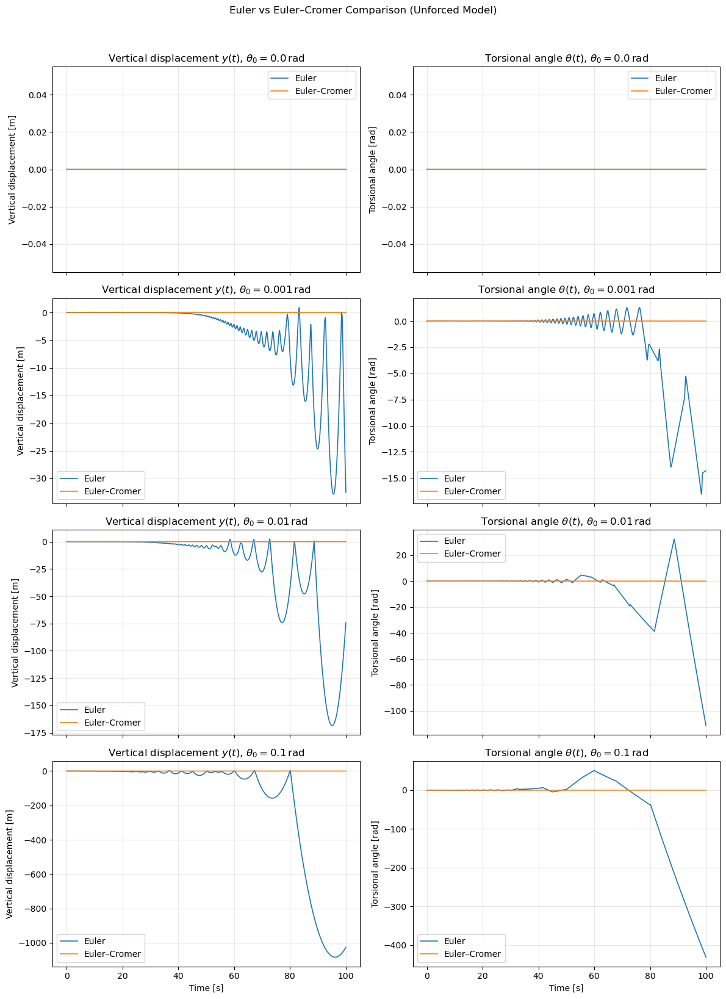

In [80]:
# ============================================================
# EULER VS EULER–CROMER (NO WIND): INITIAL TORSIONAL ANGLE SWEEP
# ============================================================

"""
Compare Euler and Euler–Cromer on the unforced model for a range of θ₀.
Rows = θ₀ values, columns = y(t) and θ(t).
"""

initial_torsional_angle_values = [0.0, 0.001, 0.01, 0.1]

# Figure layout: rows = θ₀ values, columns = [y(t), θ(t)]
rows = len(initial_torsional_angle_values)

fig, axes = plt.subplots(
    rows,
    2,
    figsize=(12, 4 * rows),
    sharex=True
)

axes = np.atleast_2d(axes)

# Run sweep over initial torsional angles
for row_index, initial_torsional_angle in enumerate(initial_torsional_angle_values):

    # Run both methods
    times_euler, torsional_angle_euler, vertical_displacement_euler = tacoma_no_wind(
        initial_torsional_angle=initial_torsional_angle,
        use_euler_cromer=False
    )

    times_cromer, torsional_angle_cromer, vertical_displacement_cromer = tacoma_no_wind(
        initial_torsional_angle=initial_torsional_angle,
        use_euler_cromer=True
    )

    # Left: y(t)
    ax_y = axes[row_index, 0]
    ax_y.plot(times_euler, vertical_displacement_euler, label="Euler", linewidth=1.2)
    ax_y.plot(times_cromer, vertical_displacement_cromer, label="Euler–Cromer", linewidth=1.2)
    ax_y.set_ylabel("Vertical displacement [m]")
    ax_y.set_title(
        rf"Vertical displacement $y(t)$, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$"
    )
    ax_y.grid(alpha=0.3)
    ax_y.legend()

    # Right: θ(t)
    ax_theta = axes[row_index, 1]
    ax_theta.plot(times_euler, torsional_angle_euler, label="Euler", linewidth=1.2)
    ax_theta.plot(times_cromer, torsional_angle_cromer, label="Euler–Cromer", linewidth=1.2)
    ax_theta.set_ylabel("Torsional angle [rad]")
    ax_theta.set_title(
        rf"Torsional angle $\theta(t)$, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$"
    )
    ax_theta.grid(alpha=0.3)
    ax_theta.legend()

# Shared x-labels (bottom row only)
axes[-1, 0].set_xlabel("Time [s]")
axes[-1, 1].set_xlabel("Time [s]")

fig.suptitle("Euler vs Euler–Cromer Comparison (Unforced Model)", y=1.02)
fig.tight_layout()
plt.show()

Plots of the vertical displacements and torsional angles against time for various initial torsional angles were presented to justify whether the Euler or Euler-Cromer method would be used for the remainder of the mini-project. By considering $\theta_0 = 0 \ \text{rad}$, a baseline validation of the model was obtained since both methods yielded identical zero solutions for both vertical displacement and torsional angle, demonstrating that that the equilibrium solution was correctly implemented as no spurious numerical excitation was introduced when the system started exactly at rest; this was consistent with the analytical expectation for the unforced system.However, for the other torsional angles, it was observed that the Euler-Cromer method maintained bounded motion close to zero throughout the simulation relative to the Euler method, that introduced numerical energy growth even for very initial torsional angles of $\theta_0 = 0.001 \ \text{rad}$, with the divergence between the two methods becoming more prominent for $\theta_0 = 0.01 \ \text{rad}$ and $\theta_0 = 0.1 \ \text{rad}$, oftentimes reaching non-physical magnitudes.

One could plot the percentage difference between the two methods as a function of time for each plot that could aid in pinpointing the regions where they agree, however, from these plots it was sufficient to justify only using the Euler-Cromer method for all subsequent investigations; by eye, one can identify that beyond a time of 60S most plots showed significant differences between the two methods. The Euler method exhibited severe numerical instability and artificial energy growth in the unforced coupled bridge model that could not be attributed to physics as there was no forcing due to wind involved that would inject energy, making it unsuitable for the investigation. 


#### 3.1.3 Wind-forced Model Implementation and Sweep

In [ ]:
# ============================================================ 
# TACOMA BRIDGE MODEL (WITH WIND FORCING)
# ============================================================

"""
Wind-forced version of the nonlinear vertical–torsional model.
Adds the sinusoidal forcing term to the vertical equation
"""

def tacoma_with_wind(
    time_step=0.01,
    use_euler_cromer=True,
    initial_vertical_displacement=0.0,
    initial_torsional_angle=0.1,
    initial_vertical_velocity=0.0,
    initial_torsional_velocity=0.0,
    wind_angular_frequency=3.0,
    wind_amplitude=1.0
):
    """
    State arrays:
      y, θ, y_dot, θ_dot

    Wind forcing (vertical equation):
      wind_amplitude * sin(wind_angular_frequency * t)

    Returns arrays:
      time_array, torsional_angle, vertical_displacement
    """

    # Time grid
    time_array = np.arange(start_time, end_time + time_step, time_step)
    num_steps = len(time_array)

    # State arrays
    vertical_displacement = np.zeros(num_steps)   # y
    torsional_angle = np.zeros(num_steps)         # θ
    vertical_velocity = np.zeros(num_steps)       # y_dot
    torsional_velocity = np.zeros(num_steps)      # θ_dot

    # Grouped constant: K / (M * a)
    stiffness_coefficient = spring_constant / (
        mass_of_bridge_segment * force_parameter
    )

    # Initial conditions
    vertical_displacement[0] = initial_vertical_displacement
    torsional_angle[0] = initial_torsional_angle
    vertical_velocity[0] = initial_vertical_velocity
    torsional_velocity[0] = initial_torsional_velocity

    # Time stepping
    for n in range(num_steps - 1):

        l_sin_theta = width_of_bridge_segment * np.sin(torsional_angle[n])

        exp_lower = np.exp(
            force_parameter * (vertical_displacement[n] - l_sin_theta)
        )
        exp_upper = np.exp(
            force_parameter * (vertical_displacement[n] + l_sin_theta)
        )

        # Accelerations
        vertical_acceleration = (
            -friction_coefficient * vertical_velocity[n]
            - stiffness_coefficient * (exp_lower + exp_upper - 2.0)
            + wind_amplitude * np.sin(wind_angular_frequency * time_array[n])
        )

        torsional_acceleration = (
            -friction_coefficient * torsional_velocity[n]
            + (3.0 * np.cos(torsional_angle[n]) / width_of_bridge_segment)
            * stiffness_coefficient
            * (exp_lower - exp_upper)
        )

        # Euler–Cromer or Euler - Euler-Cromer by default
        if use_euler_cromer:
            vertical_velocity[n + 1] = (
                vertical_velocity[n] + time_step * vertical_acceleration
            )
            torsional_velocity[n + 1] = (
                torsional_velocity[n] + time_step * torsional_acceleration
            )

            vertical_displacement[n + 1] = (
                vertical_displacement[n]
                + time_step * vertical_velocity[n + 1]
            )
            torsional_angle[n + 1] = (
                torsional_angle[n]
                + time_step * torsional_velocity[n + 1]
            )

        else:
            vertical_displacement[n + 1] = (
                vertical_displacement[n]
                + time_step * vertical_velocity[n]
            )
            torsional_angle[n + 1] = (
                torsional_angle[n]
                + time_step * torsional_velocity[n]
            )

            vertical_velocity[n + 1] = (
                vertical_velocity[n] + time_step * vertical_acceleration
            )
            torsional_velocity[n + 1] = (
                torsional_velocity[n] + time_step * torsional_acceleration
            )

    return time_array, torsional_angle, vertical_displacement

A wind-forced version of the Tacoma bridge model was implemented as function that built directly on the unforced case by introducing a sinusoidal term to represent the wind input in the vertical direction, as seen in EQUATIONS.

Hence, the model could capture how energy injected by the wind interacted with the existing coupling between the vertical displacements and the torsional angles, allowing the study of resonance behaviour and the onset of instability. To ensure that any changes in the response could be attributed solely to the addition of wind forcing, as opposed to modifications to the underlying bridge dynamics, the structure of the model was kept unchanged; as previously mentioned, the remainder of the report utilised Euler-Cromer, however, this function also included the option to use either method if a comparison wanted to be made. 


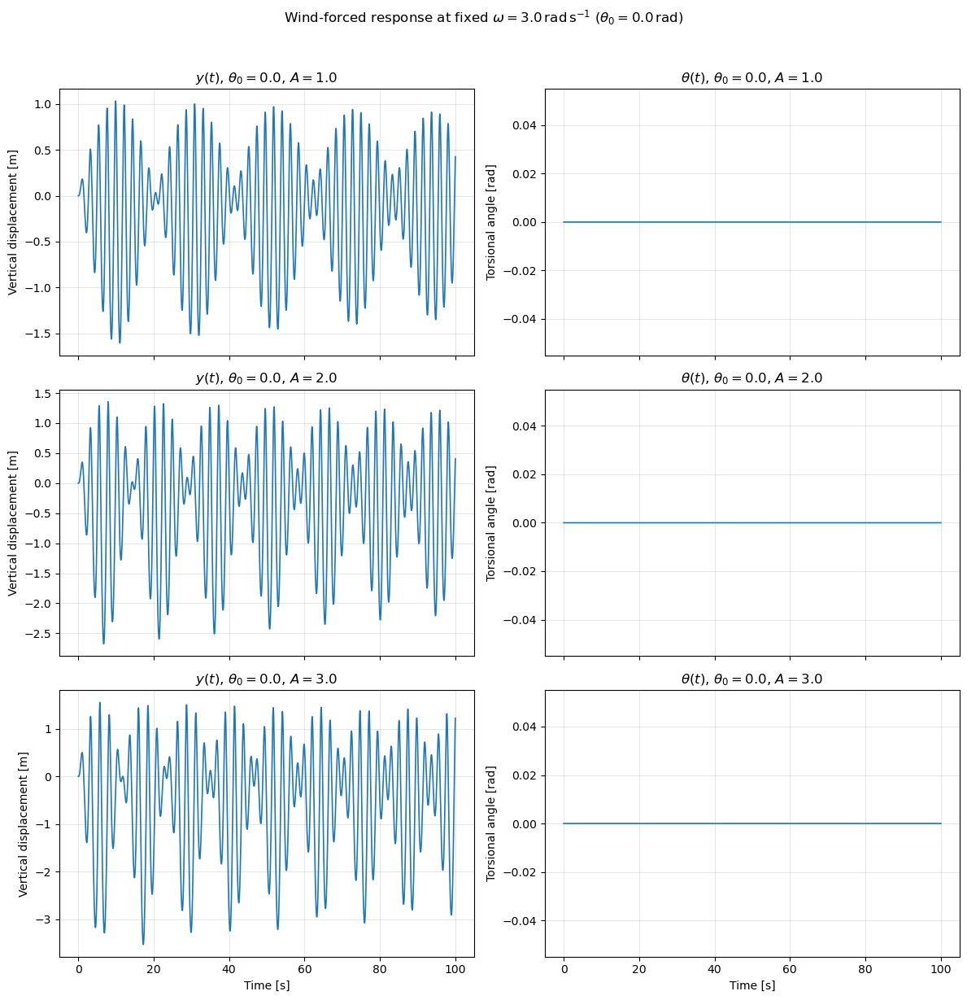

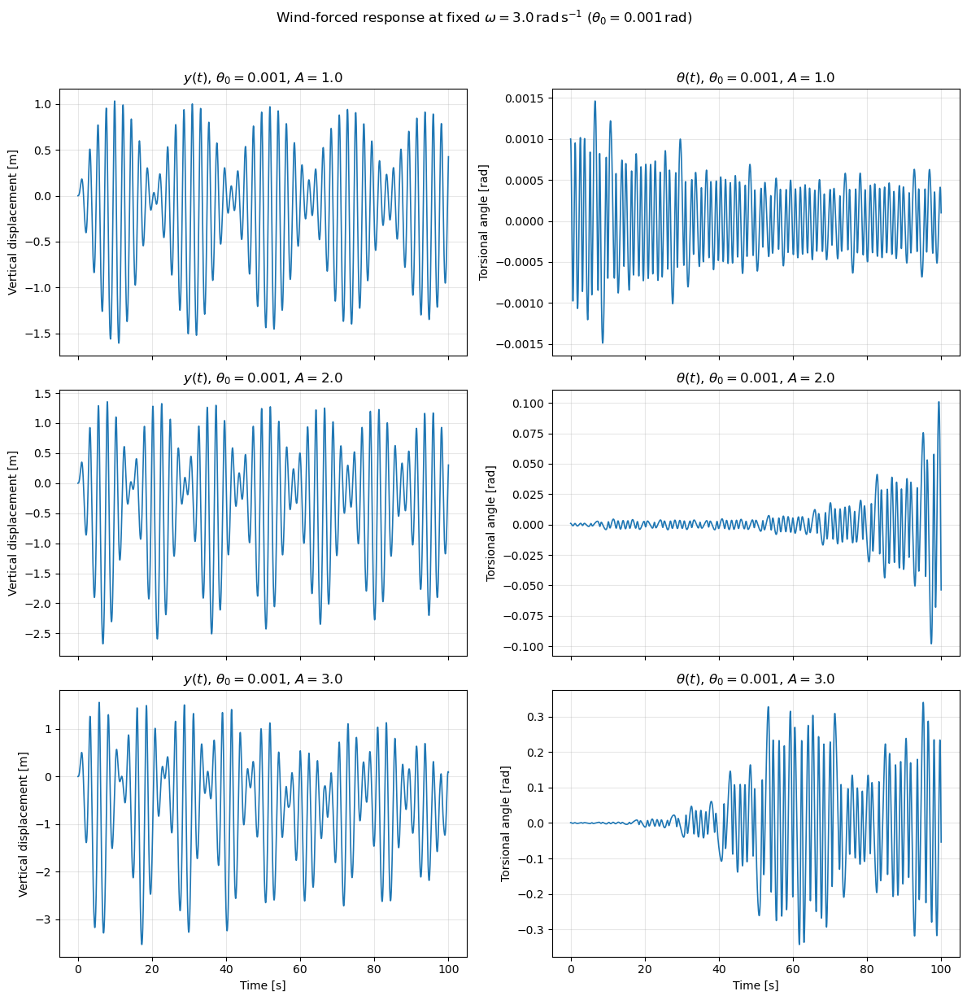

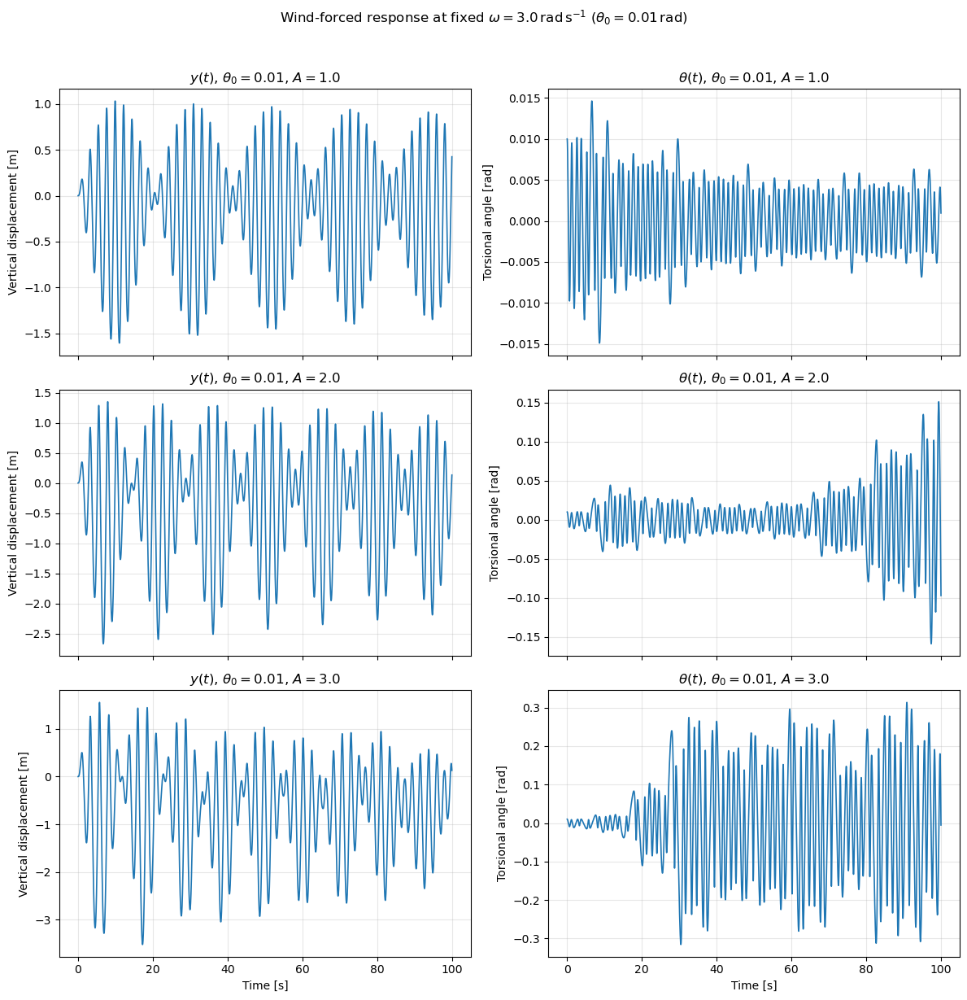

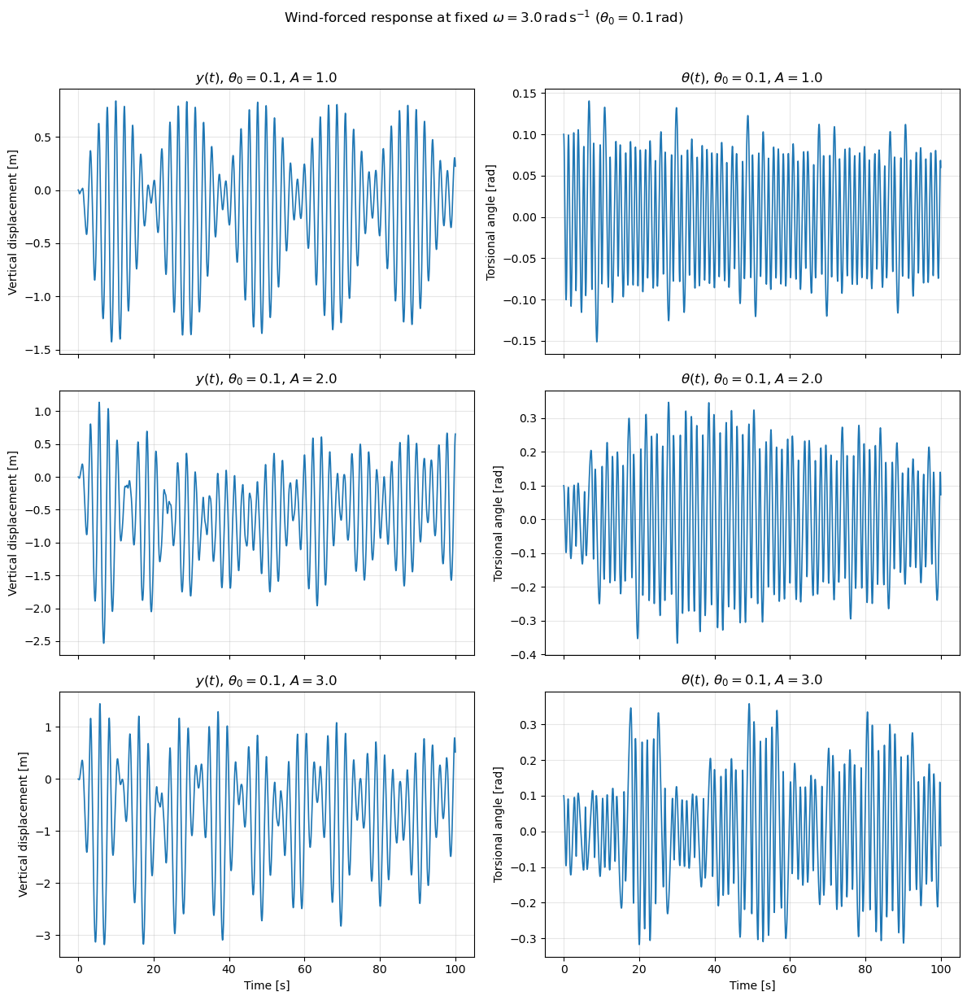

In [82]:
# ============================================================
# WIND-FORCED SWEEP: VARY A AND θ0 AT FIXED ω = 3
# ============================================================

"""
Fixed ω, sweep A for several θ_0 values.
For each θ_0: rows = A values, columns = y(t) and θ(t).
"""

initial_torsional_angle_values = [0.0, 0.001, 0.01, 0.1]
wind_amplitude_values = [1.0, 2.0, 3.0]
wind_angular_frequency = 3.0

time_step = 0.01


# Sweep over initial torsional angles
for initial_torsional_angle in initial_torsional_angle_values:

    # Figure layout: rows = A values, columns = [y(t), θ(t)]
    rows = len(wind_amplitude_values)

    fig, axes = plt.subplots(
        rows,
        2,
        figsize=(12, 4 * rows),
        sharex=True
    )

    axes = np.atleast_2d(axes)

    # Sweep over wind amplitudes at fixed ω
    for row_index, wind_amplitude in enumerate(wind_amplitude_values):

        # Run model (Euler–Cromer)
        time_array, torsional_angle, vertical_displacement = tacoma_with_wind(
            time_step=time_step,
            use_euler_cromer=True,
            initial_torsional_angle=initial_torsional_angle,
            wind_angular_frequency=wind_angular_frequency,
            wind_amplitude=wind_amplitude
        )

        # Left: y(t)
        ax_y = axes[row_index, 0]
        ax_y.plot(time_array, vertical_displacement, linewidth=1.2)
        ax_y.set_ylabel("Vertical displacement [m]")
        ax_y.set_title(
            rf"$y(t)$, $\theta_0 = {initial_torsional_angle}$, $A = {wind_amplitude}$"
        )
        ax_y.grid(alpha=0.3)

        # Right: θ(t)
        ax_theta = axes[row_index, 1]
        ax_theta.plot(time_array, torsional_angle, linewidth=1.2)
        ax_theta.set_ylabel("Torsional angle [rad]")
        ax_theta.set_title(
            rf"$\theta(t)$, $\theta_0 = {initial_torsional_angle}$, $A = {wind_amplitude}$"
        )
        ax_theta.grid(alpha=0.3)

    # Shared x-labels (bottom row only)
    axes[-1, 0].set_xlabel("Time [s]")
    axes[-1, 1].set_xlabel("Time [s]")

    fig.suptitle(
        rf"Wind-forced response at fixed $\omega = {wind_angular_frequency}\,\mathrm{{rad\,s^{{-1}}}}$ "
        rf"($\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$)",
        y=1.02
    )

    fig.tight_layout()
    plt.show()

The first analysis using this model involved systematically varying the wind amplitude $A$ and the initial torsional angle $\theta_0$ for a fixed forcing frequency of $\omega = 3$; the wind amplitude was increased in increments of $1$ from $1$ to $3$ for each value of $\theta_0$, with the resulting vertical displacements and torsional angles plotted as functions of time side by side to allow direct comparison on how the system response evolved with increasing forcing.

This sweep highlighted that the response of the system depended on both the wind forcing and the initial conditions; for $\theta_0 = 0 \mathrm{rad}$, the motion remained purely vertical for all values of $A$, with the amplitude of the vertical displacement increasing as the forcing strengthened, but ultimately no torsional motion developing – this demonstrated that when the system started in a perfectly symmetrical state, vertical forcing alone did not excite torsional dynamics.

It could be seen that breaking this symmetry by introducing even a small perturbation of $\theta_0 = 0.001 \mathrm{rad}$ could cause oscillations in the torsion, which was significantly small for $A = 1$, but grew in amplitude noticeably over time for $A = 2$ and for $A = 3$ grew strongly and became large. As for the vertical motion, this remained bounded and similar in structure across all cases, as seen for all initial torsional angles where beats-like behaviour appeared to occur.

Increasing this perturbation to $\theta_0 = 0.01 \mathrm{rad}$ led to torsional growth occurring earlier, with the amplitudes becoming larger and strong nonlinear behaviour appearing for $A = 2$ and $A = 3$. By $\theta_0 = 0.1 \mathrm{rad}$, the torsion is significant even for $A = 1$, with the torsion becoming very large and irregular for $A = 2$ and $A = 3$ as the oscillations looked strongly nonlinear and potentially chaotic.

Ultimately, it was decided that $A = 2$ would be used for the remainder of the investigation since it proved to generally be a balance between the torsional response being too small as was the case for $A = 1$ whilst also not being too strong like $A = 3$ where an explosion in amplitude could be observed.

#### 3.1.4 Forcing Frequency Sweep

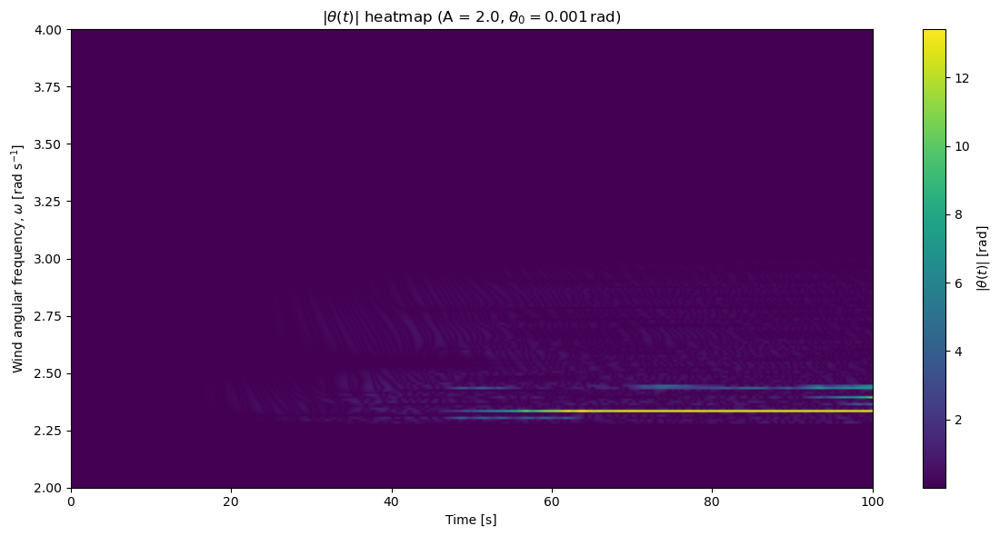

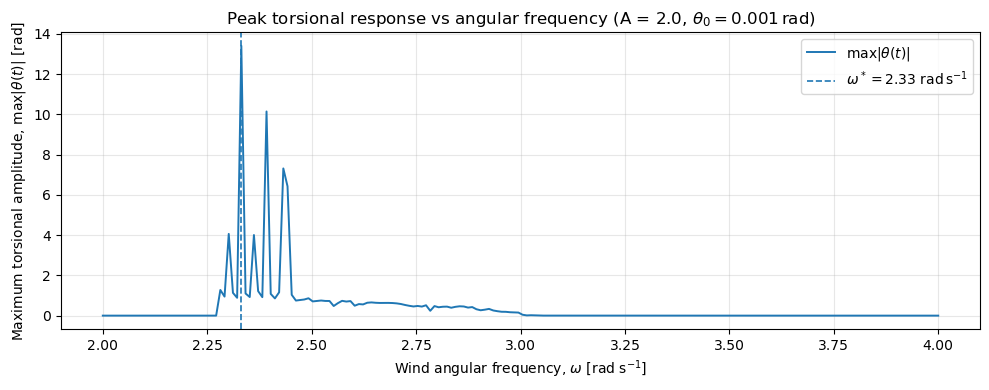


Peak torsional response (θ₀ = 0.001 rad)
ω* [rad s^-1]   : 2.33
max |θ(t)| [rad]: 13.41


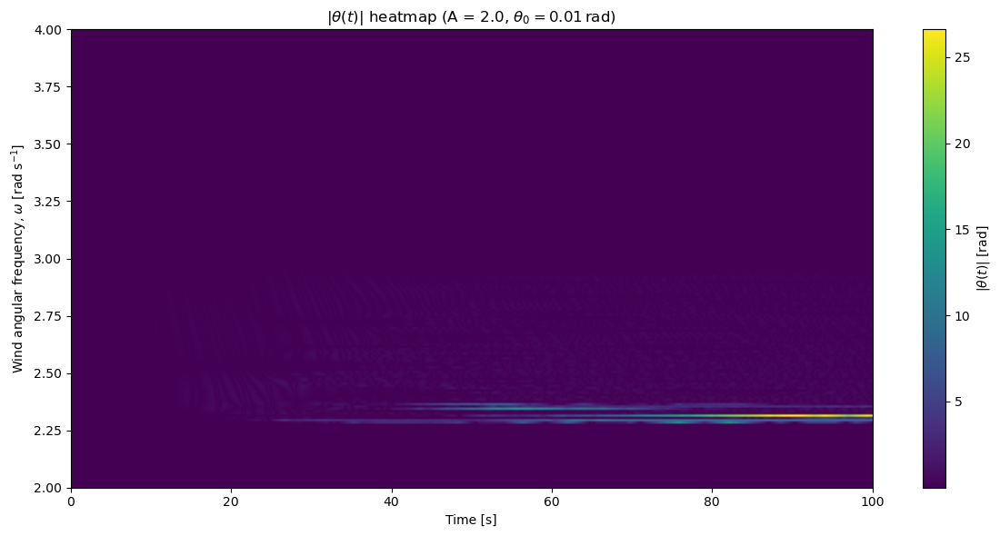

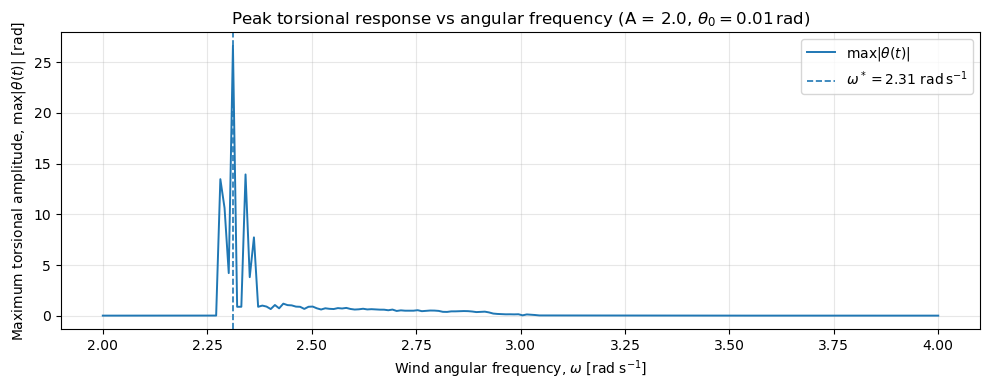


Peak torsional response (θ₀ = 0.01 rad)
ω* [rad s^-1]   : 2.31
max |θ(t)| [rad]: 26.61


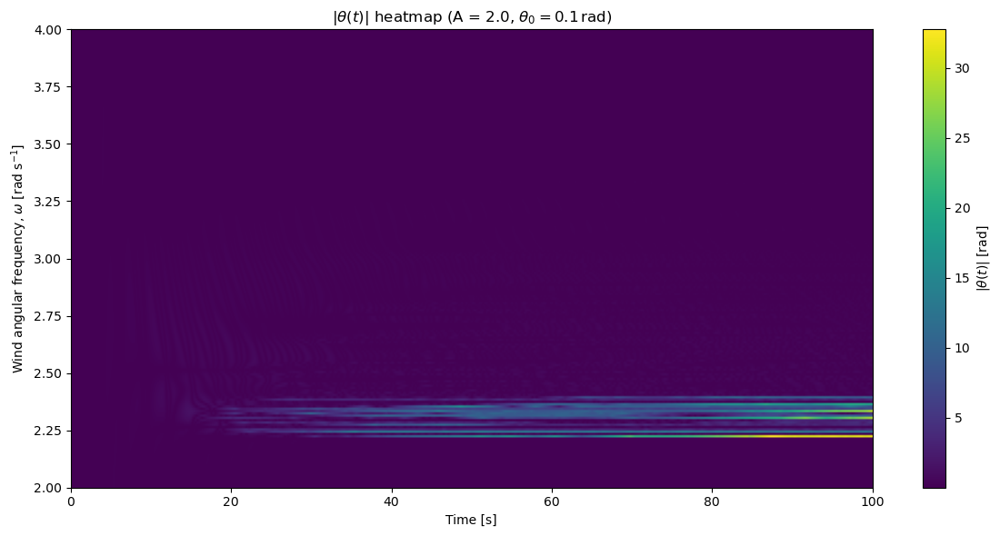

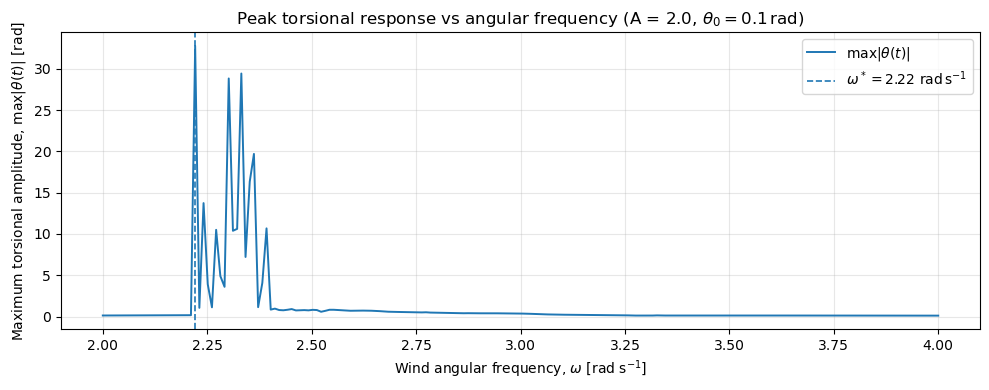


Peak torsional response (θ₀ = 0.1 rad)
ω* [rad s^-1]   : 2.22
max |θ(t)| [rad]: 32.77


In [93]:
# ============================================================
# TORSIONAL FREQUENCY RESPONSE (HEATMAPS + PEAK CURVES)
# ============================================================

# Build |θ(t)| grid across a sweep of ω values (common time grid for all runs)

def compute_torsional_magnitude_grid(
    tacoma_with_wind,
    wind_angular_frequency_min=2.0,   # [rad s^-1]
    wind_angular_frequency_max=4.0,   # [rad s^-1]
    num_frequencies=200,
    time_step=0.01,                  # [s]
    initial_torsional_angle=0.01,    # [rad]
    wind_amplitude=2.0,
):
    """
    Compute |θ(t)| for a sweep of ω values (common time grid for all runs).
    """
    wind_angular_frequencies = np.linspace(
        wind_angular_frequency_min,
        wind_angular_frequency_max,
        num_frequencies
    )

    # One run to initialise the time axis
    time_array, torsional_angle, _ = tacoma_with_wind(
        time_step=time_step,
        use_euler_cromer=True,
        initial_torsional_angle=initial_torsional_angle,
        wind_angular_frequency=wind_angular_frequencies[0],
        wind_amplitude=wind_amplitude,
    )

    torsional_magnitude = np.zeros((num_frequencies, len(time_array)))

    # Sweep ω and store |θ(t)|
    for frequency_index, wind_angular_frequency in enumerate(wind_angular_frequencies):
        _, torsional_angle, _ = tacoma_with_wind(
            time_step=time_step,
            use_euler_cromer=True,
            initial_torsional_angle=initial_torsional_angle,
            wind_angular_frequency=wind_angular_frequency,
            wind_amplitude=wind_amplitude,
        )

        torsional_magnitude[frequency_index, :] = np.abs(torsional_angle)

    return wind_angular_frequencies, time_array, torsional_magnitude


# Heatmap: |θ(t)| VS time and ω

def plot_torsional_heatmap(
    wind_angular_frequencies,
    time_array,
    torsional_magnitude,
    initial_torsional_angle,
    wind_amplitude,
):
    """
    Plot a time–frequency heatmap of |θ(t)|.
    """
    plt.figure(figsize=(12, 6))

    plt.imshow(
        torsional_magnitude,
        aspect="auto",
        origin="lower",
        extent=[
            time_array[0], time_array[-1],
            wind_angular_frequencies[0], wind_angular_frequencies[-1]
        ],
    )

    plt.colorbar(label=r"$|\theta(t)|$ [rad]")
    plt.xlabel("Time [s]")
    plt.ylabel(r"Wind angular frequency, $\omega$ [rad s$^{-1}$]")

    plt.title(
        rf"$|\theta(t)|$ heatmap "
        rf"(A = {wind_amplitude}, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$)"
    )

    plt.tight_layout()
    plt.show()


# Find max|θ(t)| for each ω

def peak_torsional_magnitude_vs_frequency(torsional_magnitude):
    return np.max(torsional_magnitude, axis=1)


# Print a quick summary of the peak response for a given θ₀ (ω* and max|θ(t)|)

def print_peak_summary(
    initial_torsional_angle,
    wind_angular_frequency_at_peak,
    max_torsional_amplitude,
):
    print(f"\nPeak torsional response (θ₀ = {initial_torsional_angle} rad)")
    print(f"ω* [rad s^-1]   : {wind_angular_frequency_at_peak:.2f}")
    print(f"max |θ(t)| [rad]: {max_torsional_amplitude:.2f}")

# Compare repsonse across θ₀ values

def compare_initial_torsional_angles(
    tacoma_with_wind,
    initial_torsional_angle_values=(0.001, 0.01, 0.1),  # [rad]
    wind_angular_frequency_min=2.0,                     # [rad s^-1]
    wind_angular_frequency_max=4.0,                     # [rad s^-1]
    num_frequencies=200,
    time_step=0.01,                                     # [s]
    wind_amplitude=2.0,
    show_heatmaps=True,
):
    """
    For each θ₀:
    Optionally show the |θ(t)| heatmap across the ω sweep,
    plot the peak curve of max|θ(t)| vs ω,
    and print a summary of the peak response (ω* and max|θ(t)|).
    """
    for initial_torsional_angle in initial_torsional_angle_values:

        wind_angular_frequencies, time_array, torsional_magnitude = compute_torsional_magnitude_grid(
            tacoma_with_wind=tacoma_with_wind,
            wind_angular_frequency_min=wind_angular_frequency_min,
            wind_angular_frequency_max=wind_angular_frequency_max,
            num_frequencies=num_frequencies,
            time_step=time_step,
            initial_torsional_angle=initial_torsional_angle,
            wind_amplitude=wind_amplitude,
        )

        if show_heatmaps: # Can be excluded for faster runs
            plot_torsional_heatmap(
                wind_angular_frequencies=wind_angular_frequencies,
                time_array=time_array,
                torsional_magnitude=torsional_magnitude,
                initial_torsional_angle=initial_torsional_angle,
                wind_amplitude=wind_amplitude,
            )

        peak_curve = peak_torsional_magnitude_vs_frequency(torsional_magnitude)

        peak_index = int(np.argmax(peak_curve))
        wind_angular_frequency_at_peak = wind_angular_frequencies[peak_index]
        max_torsional_amplitude = peak_curve[peak_index]

        plt.figure(figsize=(10, 4))
        plt.plot(
            wind_angular_frequencies,
            peak_curve,
            linewidth=1.4,
            label=r"$\max|\theta(t)|$"
        )
        plt.axvline(
            wind_angular_frequency_at_peak,
            linestyle="--",
            linewidth=1.2,
            label=rf"$\omega^* = {wind_angular_frequency_at_peak:.3g}\ \mathrm{{rad\,s^{{-1}}}}$"
        )

        plt.xlabel(r"Wind angular frequency, $\omega$ [rad s$^{-1}$]")
        plt.ylabel(r"Maximum torsional amplitude, $\max|\theta(t)|$ [rad]")
        plt.title(
            rf"Peak torsional response vs angular frequency "
            rf"(A = {wind_amplitude}, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$)"
        )
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

        print_peak_summary(
            initial_torsional_angle=initial_torsional_angle,
            wind_angular_frequency_at_peak=wind_angular_frequency_at_peak,
            max_torsional_amplitude=max_torsional_amplitude,
        )

# Example usage of the comparison function across multiple θ₀ values

compare_initial_torsional_angles(
    tacoma_with_wind=tacoma_with_wind,
    initial_torsional_angle_values=(0.001, 0.01, 0.1),
    wind_amplitude=2.0,
    show_heatmaps=True
)

By keeping the wind amplitude fixed at $A = 2$, a sweep of the wind forcing frequency was performed to explore how the torsional response of the model depended on it. This was achieved by integrating the system using the Euler–Cromer method and recording the magnitude of the torsional angle $\theta$ on a common time grid for each frequency. The results were presented on a heatmap so that the torsional magnitude $|\theta|$ could visualised simultaneously as a function of both time and forcing frequency, making regions of instability immediately identifiable. Additionally, to ease readability and allow clearer identification of resonant behaviour, the maximum torsional amplitude was extracted for each forcing frequency and plotted against frequency to produce a frequency–response curve. This enabled the frequency $\omega^*$ associated with the strongest torsional response to be identified directly.

The heatmaps revealed that, for all initial torsional angles, there existed a narrow window of instability within a small frequency band around
$\omega \approx 2.2$–$2.3 \mathrm{rad,s^{-1}}$, and the frequency–response curves complemented this observation by identifying sharp maxima in the torsional amplitude: these were found to occur at $\omega^* \approx 2.33 \mathrm{rads^{-1}}$ for $\theta_0 = 0.001 ,\mathrm{rad}$, $\omega^* \approx 2.31 ,\mathrm{rads^{-1}}$ for $\theta_0 = 0.01 ,\mathrm{rad}$, and $\omega^* \approx 2.22 \mathrm{rads^{-1}}$ for $\theta_0 = 0.1 \mathrm{rad}$, with peak torsional amplitudes increasing significantly as $\theta_0$ increased. The slight downward shift in $\omega^*$ and the rapid growth in peak amplitude highlighted the nonlinear nature of the response, demonstrating consistency with the proposition being investigated that torsional instability arises from nonlinear coupling and symmetry breaking. Beyond this narrow frequency window, the magnitude of $\theta$ remained minimal.

Another key observation from the heatmaps was the presence of a transient period before the onset of strong resonant growth. For $\theta_0 = 0.1 \mathrm{rad}$, this transient phase was the shortest, ending at approximately $t \approx 20 \mathrm{s}$, whereas for smaller initial angles it persisted slightly longer. This further supported the relationship that increasing the magnitude of the initial torsional perturbation reduces the transient time. Hence, to compromise between driving the system into strongly irregular behaviour too rapidly (as seen for $\theta_0 = 0.1 \mathrm{rad}$ ) and spending excessive time in the transient regime (as observed for $\theta_0 = 0.001 \mathrm{rad}$ ), the value $\theta_0 = 0.01 \mathrm{rad}$ was used for the remainder of the investigation. This value was sufficiently small to represent a realistic symmetry-breaking perturbation while still producing a clear and measurable torsional response.

#### 3.1.5 Phase-Space Trajectory Sweeps

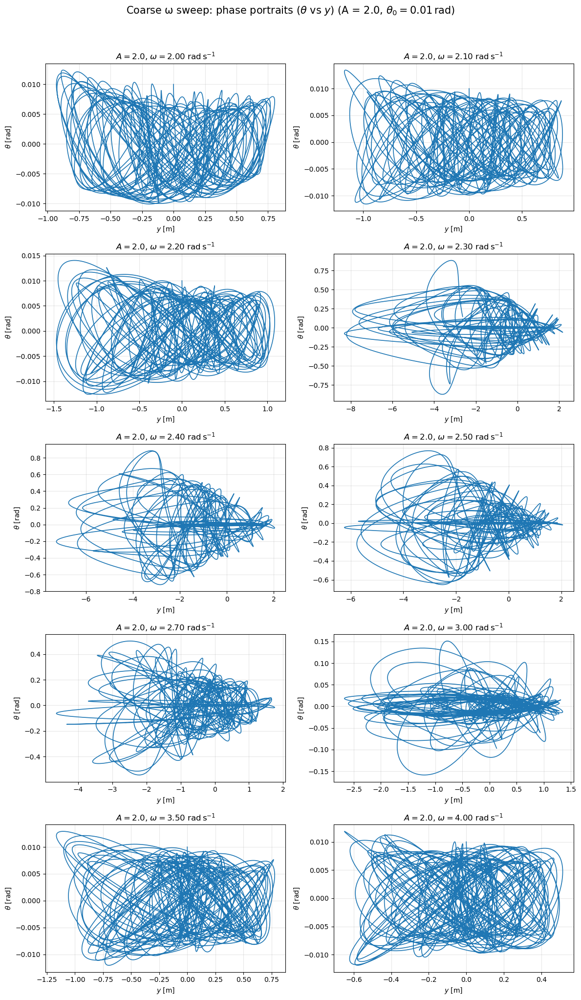

In [95]:
# ============================================================
# PHASE-SPACE TRAJECTORIES: θ VS y (COARSE ω SWEEP)
# ============================================================

"""
Plot phase portraits (θ vs y) for a coarse sweep of forcing frequencies ω,
with A and θ₀ held fixed.
"""

# Parameters

time_step = 0.01                 # Δt [s]
wind_amplitude = 2.0             # A (model parameter)
initial_torsional_angle = 0.01   # θ₀ [rad]

coarse_wind_angular_frequencies = np.array(
    [2.0, 2.1, 2.2, 2.3, 2.4, 2.5, 2.7, 3.0, 3.5, 4.0]
)  # ω values [rad s^-1]

# Figure layout: 2 plots per row

num_frequencies = len(coarse_wind_angular_frequencies)
rows = int(np.ceil(num_frequencies / 2))

fig, axes = plt.subplots(
    rows,
    2,
    figsize=(12, 4 * rows)
)

axes = np.array(axes).ravel()

# Frequency sweep: phase portraits

for ax, wind_angular_frequency in zip(axes, coarse_wind_angular_frequencies):

    time_array, torsional_angle, vertical_displacement = tacoma_with_wind(
        time_step=time_step,
        use_euler_cromer=True,
        initial_torsional_angle=initial_torsional_angle,
        wind_angular_frequency=wind_angular_frequency,
        wind_amplitude=wind_amplitude
    )

    ax.plot(vertical_displacement, torsional_angle, linewidth=1.2)

    ax.set_xlabel(r"$y$ [m]")
    ax.set_ylabel(r"$\theta$ [rad]")

    ax.set_title(
        rf"$A = {wind_amplitude}$, "
        rf"$\omega = {wind_angular_frequency:.2f}\ \mathrm{{rad\,s^{{-1}}}}$"
    )

    ax.grid(alpha=0.3)

# Disable unused axis if the number of ω values is odd - used during testing 

if num_frequencies % 2 != 0:
    axes[-1].axis("off")

# Figure title + layout

fig.suptitle(
    rf"Coarse ω sweep: phase portraits ($\theta$ vs $y$) "
    rf"(A = {wind_amplitude}, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$)",
    fontsize=15,
    y=1.02
)

fig.tight_layout()
plt.show()

As the amplitude was fixed at $A = 2$ and the initial torsional angle at $\theta_0 = 0.01 ,\mathrm{rad}$, phase–space trajectories of the torsional angle $\theta$ against vertical displacement $y$ were produced for a coarse sweep of different forcing frequencies, with these values chosen to explore the full range shown in the heatmap.

For low forcing frequencies of $\omega = 2.0$–$2.2 \mathrm{rads^{-1}}$, the trajectories were bounded and relatively compact, demonstrating behaviour that appeared quasi-periodic due to the dense but confined looping. No large growth in amplitude was observed and, whilst coupling between the vertical and torsional modes was present, it appeared weak; the system therefore behaved in a mostly stable regime. Physically, this can be justified by the energy input not strongly amplifying the motion since the forcing was off-resonance.

However, for $\omega = 2.30 \mathrm{rads^{-1}}$, there was a dramatic change in behaviour as the phase portraits expanded suddenly with large excursions in both modes as the structure became much more irregular and the trajectories stretched far from the origin, strongly suggesting resonant coupling and the onset of nonlinear instability.

Beyond $\omega = 2.40 \mathrm{rads^{-1}}$, the trajectories remained large yet somewhat more structured than at $2.30 \mathrm{rads^{-1}}$, although they still demonstrated nonlinear coupling, suggesting that there was still significant energy transfer into torsion, but slightly less than at the strongest resonance frequency. By $\omega = 3.0 \mathrm{rads^{-1}}$, the phase portrait shrank again, with the motion becoming more bounded and a reduction in torsional amplitude as the forcing moved further away from resonance; the heatmap and frequency–response graph could be used to verify these observations.

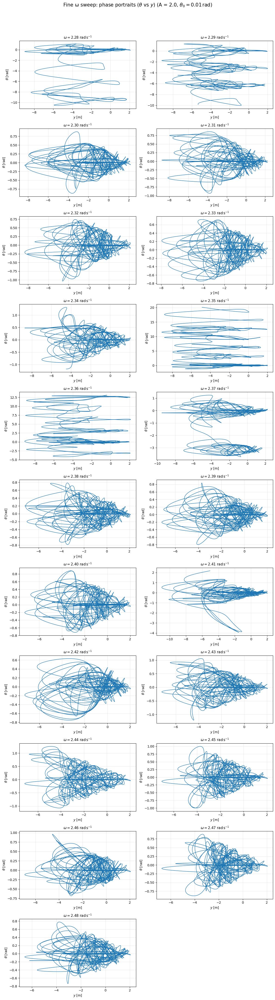

In [94]:
# ============================================================
# PHASE-SPACE TRAJECTORIES: θ VS y (FINE ω SWEEP)
# ============================================================

"""
Fine ω sweep of phase portraits (θ vs y) over a narrow frequency window.
"""

# Parameters

time_step = 0.01                 # Δt [s]
wind_amplitude = 2.0             # A (model parameter)
initial_torsional_angle = 0.01   # θ₀ [rad]

fine_omega_min = 2.28            # ω_min [rad s^-1]
fine_omega_max = 2.48            # ω_max [rad s^-1]
fine_omega_step = 0.01           # Δω [rad s^-1]

fine_wind_angular_frequencies = np.arange(
    fine_omega_min,
    fine_omega_max + 1e-12,
    fine_omega_step
)

# Figure layout: 2 plots per row

num_frequencies = len(fine_wind_angular_frequencies)
rows = int(np.ceil(num_frequencies / 2))

fig, axes = plt.subplots(
    rows,
    2,
    figsize=(12, 4 * rows)
)

axes = np.array(axes).ravel()

# Frequency sweep: phase portraits

for ax, wind_angular_frequency in zip(axes, fine_wind_angular_frequencies):

    time_array, torsional_angle, vertical_displacement = tacoma_with_wind(
        time_step=time_step,
        use_euler_cromer=True,
        initial_torsional_angle=initial_torsional_angle,
        wind_angular_frequency=wind_angular_frequency,
        wind_amplitude=wind_amplitude
    )

    ax.plot(vertical_displacement, torsional_angle, linewidth=1.1)

    ax.set_xlabel(r"$y$ [m]")
    ax.set_ylabel(r"$\theta$ [rad]")

    ax.set_title(
        rf"$\omega = {wind_angular_frequency:.2f}\ \mathrm{{rad\,s^{{-1}}}}$",
        fontsize=11
    )

    ax.grid(alpha=0.3)

# Disable unused axis if number of ω values is odd

if num_frequencies % 2 != 0:
    axes[-1].axis("off")

# Figure title + layout

fig.suptitle(
    rf"Fine ω sweep: phase portraits ($\theta$ vs $y$) "
    rf"(A = {wind_amplitude}, $\theta_0 = {initial_torsional_angle}\,\mathrm{{rad}}$)",
    fontsize=15
)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


The final analysis focused on phase portraits for a fine sweep of forcing frequencies between
$\omega = 2.28 \mathrm{rads^{-1}}$ and $\omega = 2.48 \mathrm{rads^{-1}}$, targeting the narrow instability region identified earlier.For frequencies slightly away from the critical values, the trajectories remained fairly compact and clustered, and although the vertical displacement was still large, the motion appeared bounded and more regular; the phase–space loops were mostly closed or tightly wound, suggesting quasi-periodic behaviour and limited transfer of energy into torsion.

However, at specific frequencies such as $\omega = 2.28$, $2.29$, $2.35$, and $2.36 \mathrm{rads^{-1}}$, the behaviour changed noticeably, with the phase portraits spreading out dramatically as both the vertical displacement $y$ and torsional angle $\theta$ increased sharply; this resulted in the trajectories becoming distorted and non-closed, indicating strong nonlinear coupling and sustained growth in the torsional response. In particular, at $\omega = 2.35 ,\mathrm{rad,s^{-1}}$, the torsional angle exceeded $20 \mathrm{rad}$, while $\omega = 2.36 \mathrm{rads^{-1}}$ also produced similarly large amplitudes, with these large excursions suggesting that the system was extremely close to a coupled resonance, such that even small changes in forcing frequency led to significant changes in response.

Overall, when considered alongside the heatmaps and frequency–response curves, the phase–space analysis supported the conclusion that within a narrow frequency window, energy injected by the vertical forcing was transferred efficiently into torsional motion, with the widening and distortion of the phase portraits in this region clearly indicating strong coupling between the vertical displacement $y$ and torsional angle $\theta$, with sustained growth in torsion occurring only near the critical frequencies. This behaviour was consistent with McKenna and Tuama's proposition that the collapse of the Tacoma Narrows Bridge was not simply due to a linear resonance, but rather the result of nonlinear coupling between vertical and torsional modes, suggesting that their proposed model yielded adequate results. 


### 3.2 Tuned Mass Damper 

A tuned mass damper (TMD) is a secondary mass attached to a structure using a spring and a damper, designed to oscillate out of phase with the main structure so that vibrational energy is transferred away from the primary motion and dissipated. When the structure begins to vibrate near a critical frequency, the TMD responds through relative motion, effectively absorbing energy that would otherwise accumulate in the main system. (Miyamoto International, 2025) 

The Taipei 101 building in Taiwan is an iconic example of where a TMD has been implemented, as it features a 660-ton steel pendulum sphere located between the 88th and 92nd floors to counteract typhoon winds and seismic tremors (David, 2010). Another example showing resemblance to the Tacoma Bridge investigated in this report is the London Millennium Bridge, that gained a nickname of its own “the Wobbly Bridge" as it developed an unexpected and significant lateral (sideways) sway, leading to its closure just two days later; initial claims of synchronous lateral excitation being the cause were favoured instead by the idea that pedestrians trying to not fall over and walking randomly on the bridge provided ‘negative damping’ whereby the energy from a person’s wobbling was transferred to the bridge (Hakimian, 2021). Nevertheless, the implementation of dampers resolved the swaying, and the bridge reopened two years later on February 22nd, 2002. 

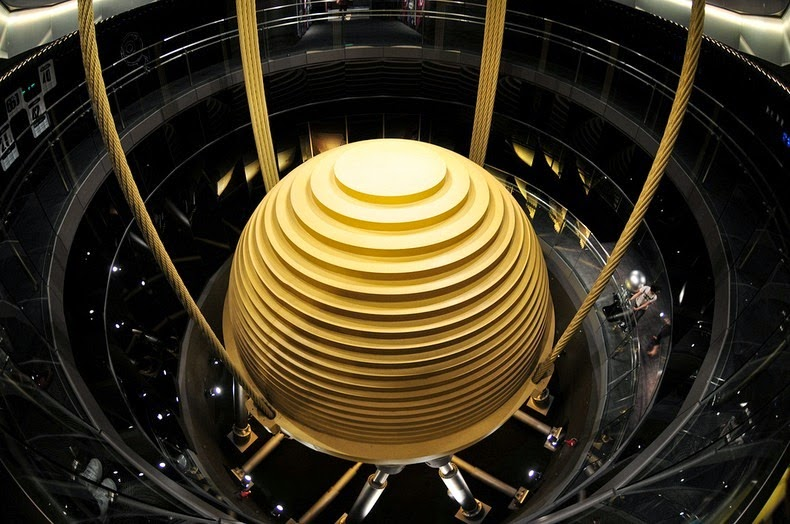

In [103]:
Image(filename='Taipei_101.png')

*Figure 5: Tuned mass damper inside Taipei 101 (Rinux, 2008).*

In this report, the TMD was represented by an additional vertical degree of freedom $x(t)$ coupled to the bridge’s vertical displacement $y(t)$, implemented through the relative displacement $(x - y)$ and relative velocity $(\dot{x} - \dot{y})$, which generates a reaction force given by:

$$ 
F_{\text{TMD}\to\text{bridge}} = k(x - y) + c(\dot{x} - \dot{y}) \tag{17} 
$$ 

Where Equation 17 represents a spring–damper connection between the TMD mass and the bridge deck.

The natural frequency of the TMD was tuned to match the forcing frequency by choosing $k_t$ such that
$$
\omega_t = \sqrt{\frac{k_t}{m_t}} = \omega
\tag{18}
$$

Where
- $\omega_t$ is the natural angular frequency of the TMD (rad / s)
- $k_t$ is the stiffness of the TMD spring (N / m)
- $m_t$ is the mass of the TMD (kg)
- $\omega$ is the target angular frequency being matched.

and the damping level was then tuned via a damping ratio based on the standard relation seen in Equation 19 (Purdue University, 2002).
$$
c_t = 2 \zeta \sqrt{k_t m_t} 
\tag{19}
$$

Where
- $c_t$ is the damping coefficient of the TMD (N·s / m)
- $\zeta$ is the damping ratio of the TMD (dimensionless)
- $k_t$ is the stiffness of the TMD spring (N / m)
- $m_t$ is the mass of the TMD (kg)

In [102]:
# ============================================================
# TACOMA BRIDGE MODEL (WIND + TUNED MASS DAMPER)
# ============================================================

"""
Wind-forced bridge model with an attached tuned mass damper (TMD).
"""

def tacoma_with_wind_and_tmd(
    time_step=0.01,
    use_euler_cromer=True,
    initial_vertical_displacement=0.0,
    initial_torsional_angle=0.1,
    initial_vertical_velocity=0.0,
    initial_torsional_velocity=0.0,
    wind_angular_frequency=3.0,
    wind_amplitude=1.0,
    # TMD parameters
    tmd_mass=50.0,                   # [kg]
    tmd_spring_constant=450.0,       # [N m^-1]
    tmd_damping_coefficient=30.0,    # [N s m^-1]
    # TMD initial conditions
    initial_tmd_displacement=0.0,    # x0 [m]
    initial_tmd_velocity=0.0         # x_dot0 [m s^-1]
):
    """
    State variables:
      y, θ, y_dot, θ_dot   : bridge
      x, x_dot             : tuned mass damper

    Coupling (relative motion):
      Δx = x - y
      Δv = x_dot - y_dot
      F_TMD_on_bridge = kΔx + cΔv
    """

    # Time grid
    
    time_array = np.arange(start_time, end_time + time_step, time_step)
    num_steps = len(time_array)

    # Bridge state arrays

    vertical_displacement = np.zeros(num_steps)   # y
    torsional_angle = np.zeros(num_steps)         # θ
    vertical_velocity = np.zeros(num_steps)       # y_dot
    torsional_velocity = np.zeros(num_steps)      # θ_dot

    # TMD state arrays

    tmd_displacement = np.zeros(num_steps)        # x
    tmd_velocity = np.zeros(num_steps)            # x_dot

    # Precomputed constant

    stiffness_coefficient = spring_constant / (
        mass_of_bridge_segment * force_parameter
    )

    # Initial conditions

    vertical_displacement[0] = initial_vertical_displacement
    torsional_angle[0] = initial_torsional_angle
    vertical_velocity[0] = initial_vertical_velocity
    torsional_velocity[0] = initial_torsional_velocity

    tmd_displacement[0] = initial_tmd_displacement
    tmd_velocity[0] = initial_tmd_velocity

    # Time stepping

    for time_index in range(num_steps - 1):

        l_sin_theta = width_of_bridge_segment * np.sin(torsional_angle[time_index])

        exp_lower = np.exp(force_parameter * (vertical_displacement[time_index] - l_sin_theta))
        exp_upper = np.exp(force_parameter * (vertical_displacement[time_index] + l_sin_theta))

        # Relative TMD–bridge motion
        relative_displacement = tmd_displacement[time_index] - vertical_displacement[time_index]
        relative_velocity = tmd_velocity[time_index] - vertical_velocity[time_index]

        # TMD reaction force on the bridge
        tmd_force_on_bridge = (
            tmd_spring_constant * relative_displacement
            + tmd_damping_coefficient * relative_velocity
        )

        # Bridge accelerations
        vertical_acceleration = (
            -friction_coefficient * vertical_velocity[time_index]
            - stiffness_coefficient * (exp_lower + exp_upper - 2.0)
            + wind_amplitude * np.sin(wind_angular_frequency * time_array[time_index])
            + (tmd_force_on_bridge / mass_of_bridge_segment)
        )

        torsional_acceleration = (
            -friction_coefficient * torsional_velocity[time_index]
            + (3.0 * np.cos(torsional_angle[time_index]) / width_of_bridge_segment)
            * stiffness_coefficient
            * (exp_lower - exp_upper)
        )

        # TMD acceleration (driven by relative motion)
        tmd_acceleration = (
            -(tmd_damping_coefficient / tmd_mass) * relative_velocity
            -(tmd_spring_constant / tmd_mass) * relative_displacement
        )

        # Update rule - Euler Cromer by default

        if use_euler_cromer:

            vertical_velocity[time_index + 1] = vertical_velocity[time_index] + time_step * vertical_acceleration
            torsional_velocity[time_index + 1] = torsional_velocity[time_index] + time_step * torsional_acceleration
            tmd_velocity[time_index + 1] = tmd_velocity[time_index] + time_step * tmd_acceleration

            vertical_displacement[time_index + 1] = vertical_displacement[time_index] + time_step * vertical_velocity[time_index + 1]
            torsional_angle[time_index + 1] = torsional_angle[time_index] + time_step * torsional_velocity[time_index + 1]
            tmd_displacement[time_index + 1] = tmd_displacement[time_index] + time_step * tmd_velocity[time_index + 1]

        else:

            vertical_displacement[time_index + 1] = vertical_displacement[time_index] + time_step * vertical_velocity[time_index]
            torsional_angle[time_index + 1] = torsional_angle[time_index] + time_step * torsional_velocity[time_index]
            tmd_displacement[time_index + 1] = tmd_displacement[time_index] + time_step * tmd_velocity[time_index]

            vertical_velocity[time_index + 1] = vertical_velocity[time_index] + time_step * vertical_acceleration
            torsional_velocity[time_index + 1] = torsional_velocity[time_index] + time_step * torsional_acceleration
            tmd_velocity[time_index + 1] = tmd_velocity[time_index] + time_step * tmd_acceleration

    return time_array, torsional_angle, vertical_displacement, tmd_displacement



Running ω = 2.000 rad s^-1
m_TMD = 50.000 kg | k_TMD = 200.000 N m^-1 | c_TMD = 20.000 N s m^-1


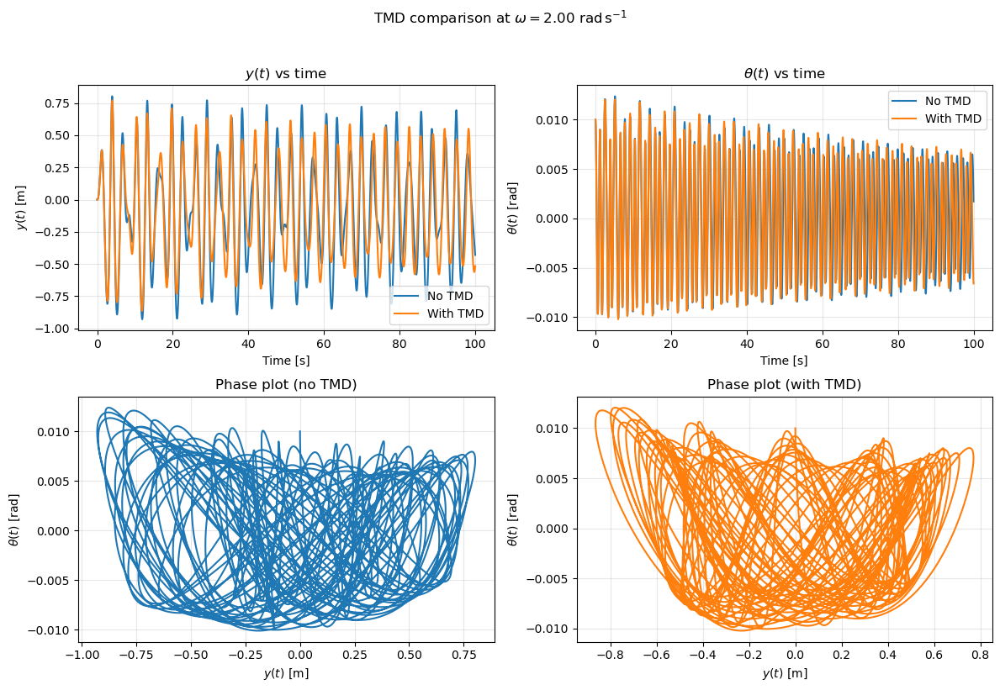


Running ω = 2.360 rad s^-1
m_TMD = 50.000 kg | k_TMD = 278.480 N m^-1 | c_TMD = 23.600 N s m^-1


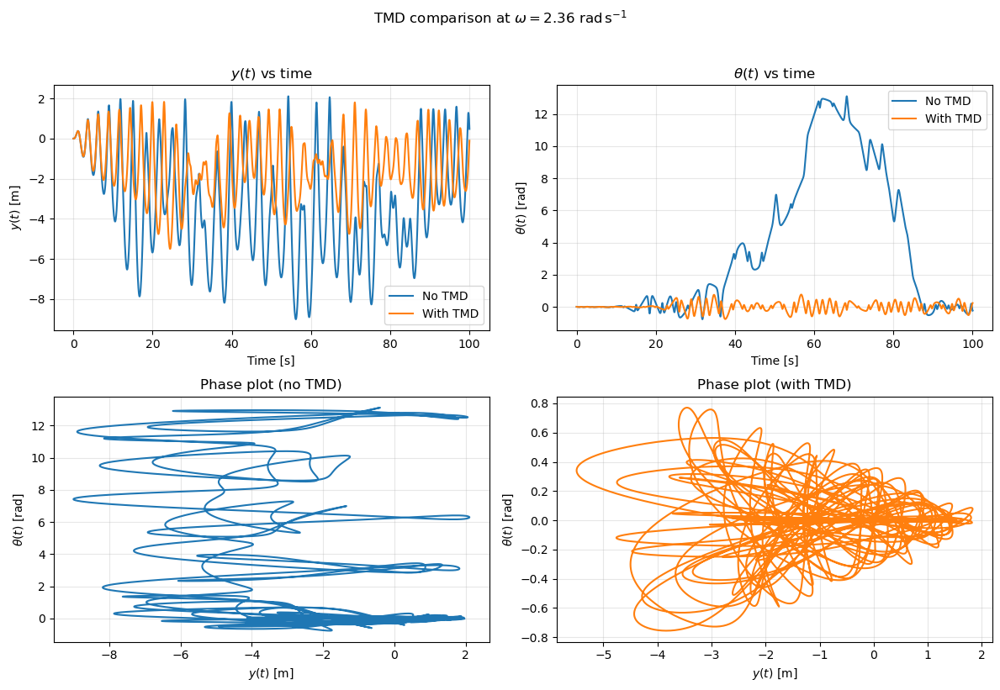


Running ω = 2.500 rad s^-1
m_TMD = 50.000 kg | k_TMD = 312.500 N m^-1 | c_TMD = 25.000 N s m^-1


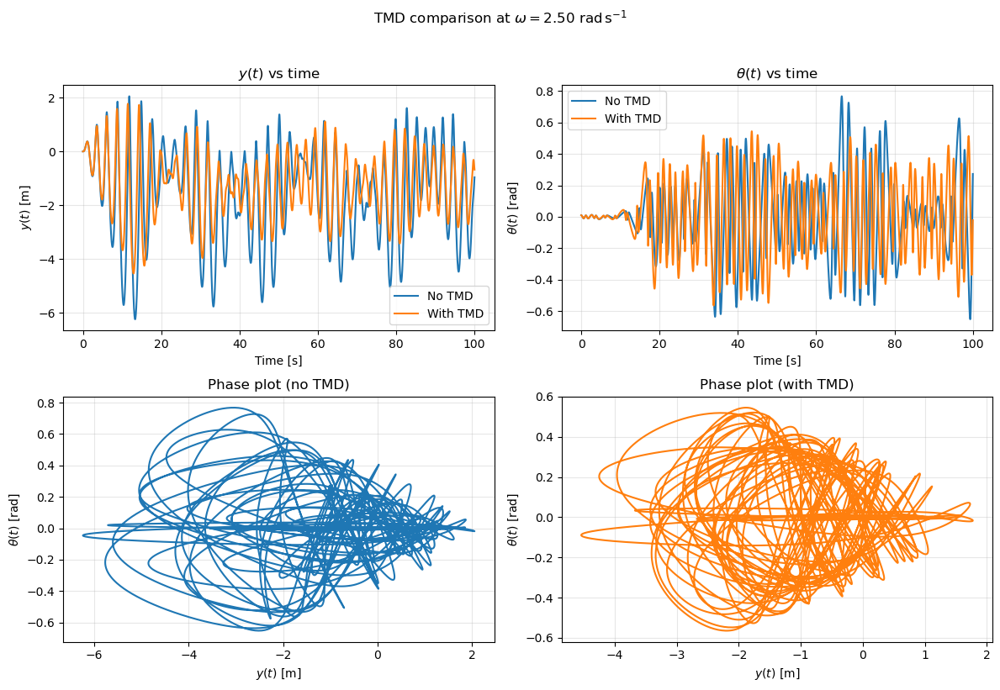


Running ω = 3.000 rad s^-1
m_TMD = 50.000 kg | k_TMD = 450.000 N m^-1 | c_TMD = 30.000 N s m^-1


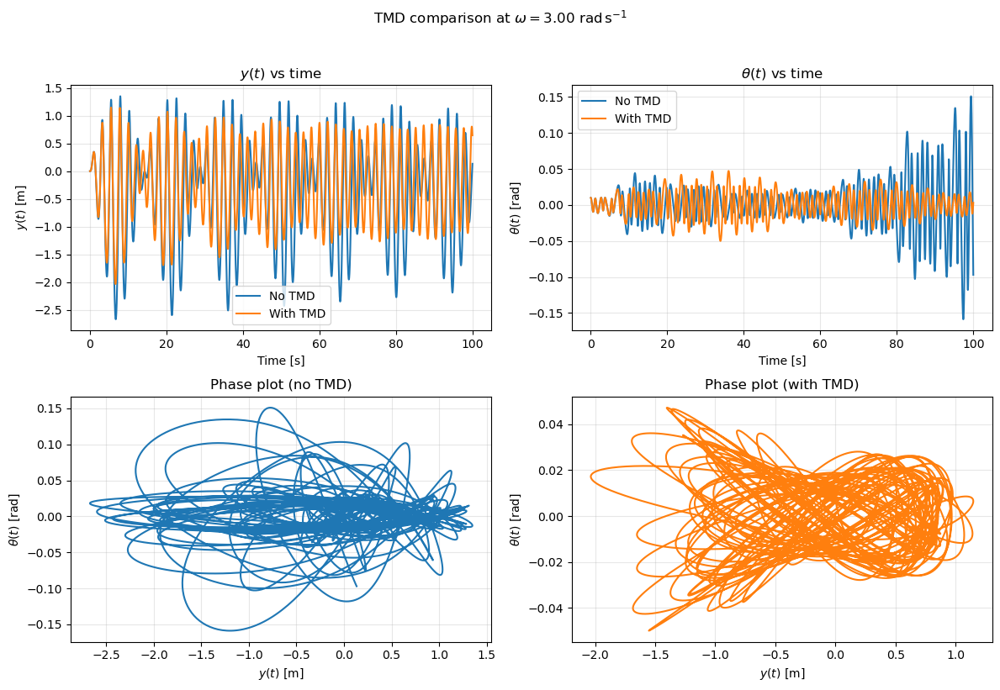

In [ ]:
# ============================================================
# TMD COMPARISON ACROSS MULTIPLE FORCING FREQUENCIES
# ============================================================

"""
Compare the wind-driven bridge response with and without a tuned mass damper (TMD)
for a small set of forcing frequencies ω. For each ω, the TMD is tuned and the
results are shown as time series and phase plots.
"""


# Bridge / simulation settings

segment_mass = 2500.0           # [kg]
time_step = 0.01                # [s]
wind_amplitude = 2.0            # forcing amplitude A
initial_torsional_angle = 0.01  # θ_0 [rad]

wind_angular_frequency_values = [2.0, 2.36, 2.5, 3.0]  # [rad s^-1]


# TMD design settings

tmd_mass_ratio = 0.02           # μ = m_TMD / M_segment
tmd_damping_ratio = 0.10        # ζ

color_no_tmd = "tab:blue"
color_with_tmd = "tab:orange"


for wind_angular_frequency in wind_angular_frequency_values:


    # Tune TMD to the current ω

    tmd_mass = tmd_mass_ratio * segment_mass
    tmd_spring_constant = tmd_mass * (wind_angular_frequency ** 2)  # k = m ω^2
    tmd_damping_coefficient = 2.0 * tmd_damping_ratio * np.sqrt(tmd_spring_constant * tmd_mass)

    print(f"\nRunning ω = {wind_angular_frequency:.3f} rad s^-1")
    print(f"m_TMD = {tmd_mass:.3f} kg | k_TMD = {tmd_spring_constant:.3f} N m^-1 | c_TMD = {tmd_damping_coefficient:.3f} N s m^-1")


    # Run: no TMD

    time_array, torsional_angle_no_tmd, vertical_displacement_no_tmd = tacoma_with_wind(
        time_step=time_step,
        use_euler_cromer=True,
        initial_torsional_angle=initial_torsional_angle,
        wind_angular_frequency=wind_angular_frequency,
        wind_amplitude=wind_amplitude
    )

    # Run: with TMD

    _, torsional_angle_with_tmd, vertical_displacement_with_tmd, _ = tacoma_with_wind_and_tmd(
        time_step=time_step,
        use_euler_cromer=True,
        initial_torsional_angle=initial_torsional_angle,
        wind_angular_frequency=wind_angular_frequency,
        wind_amplitude=wind_amplitude,
        tmd_mass=tmd_mass,
        tmd_spring_constant=tmd_spring_constant,
        tmd_damping_coefficient=tmd_damping_coefficient
    )


    # Plots of results for this ω

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # y(t) vs time
    axes[0, 0].plot(time_array, vertical_displacement_no_tmd, label="No TMD", color=color_no_tmd)
    axes[0, 0].plot(time_array, vertical_displacement_with_tmd, label="With TMD", color=color_with_tmd)
    axes[0, 0].set_title(r"$y(t)$ vs time")
    axes[0, 0].set_xlabel("Time [s]")
    axes[0, 0].set_ylabel(r"$y(t)$ [m]")
    axes[0, 0].grid(alpha=0.3)
    axes[0, 0].legend()

    # θ(t) vs time
    axes[0, 1].plot(time_array, torsional_angle_no_tmd, label="No TMD", color=color_no_tmd)
    axes[0, 1].plot(time_array, torsional_angle_with_tmd, label="With TMD", color=color_with_tmd)
    axes[0, 1].set_title(r"$\theta(t)$ vs time")
    axes[0, 1].set_xlabel("Time [s]")
    axes[0, 1].set_ylabel(r"$\theta(t)$ [rad]")
    axes[0, 1].grid(alpha=0.3)
    axes[0, 1].legend()

    # Phase plot: no TMD
    axes[1, 0].plot(vertical_displacement_no_tmd, torsional_angle_no_tmd, color=color_no_tmd)
    axes[1, 0].set_title("Phase plot (no TMD)")
    axes[1, 0].set_xlabel(r"$y(t)$ [m]")
    axes[1, 0].set_ylabel(r"$\theta(t)$ [rad]")
    axes[1, 0].grid(alpha=0.3)

    # Phase plot: with TMD
    axes[1, 1].plot(vertical_displacement_with_tmd, torsional_angle_with_tmd, color=color_with_tmd)
    axes[1, 1].set_title("Phase plot (with TMD)")
    axes[1, 1].set_xlabel(r"$y(t)$ [m]")
    axes[1, 1].set_ylabel(r"$\theta(t)$ [rad]")
    axes[1, 1].grid(alpha=0.3)

    fig.suptitle(rf"TMD comparison at $\omega = {wind_angular_frequency:.2f}\ \mathrm{{rad\,s^{{-1}}}}$", y=1.02)

    plt.tight_layout()
    plt.show()


These plots compared the wind-forced bridge response with and without a tuned mass damper (TMD) across a range of forcing frequencies that were deemed interesting to explore based on the heatmap and frequency-response graphs. It was observed at lower frequencies (e.g. $\omega = 2.0\mathrm{rad s^{-1}}$) that whilst the TMD did cause a modest reduction in the vertical displacement amplitude, the torsional response remained broadly similar for both cases. 

Contrastingly, the undamped system exhibited rapid growth in $\theta(t)$ and large, spreading phase-space trajectories near the sensitive frequency range around $\omega \approx 2.35\mathrm{rads^{-1}}$, however, the TMD significantly suppressed torsional motion, keeping $\theta(t)$ bounded and the phase portraits compact, indicating that it was effective at removing energy from the vertically forced motion before it could be transferred into torsion via nonlinear coupling. Furthermore, the vertical amplitudes were significantly reduced in comparison to with no TMD. For the higher forcing frequencies such as $\omega = 2.5\mathrm{rads^{-1}}$ and $3.0\mathrm{rads^{-1}}$), the stabilising effect of the TMD was still visible, though less dramatic, with reductions in both vertical amplitude and phase-space spread compared to the undamped case.

Overall, these results portrayed that while the TMD did not eliminate vertical motion entirely, it substantially reduced the conditions under which torsional instability developed, in particular near the critical frequency range; this supported the interpretation that the TMD acts by limiting the energy available for nonlinear vertical–torsional coupling, rather than directly damping torsional motion itself - this could be seen as further support of McKenna and Tuama's hypothesis. In relation to this, one could implement a torsional motion damper as an extension instead, since this model involves a TMD connected to the bridge deck via a linear spring and damper that responds only to the vertical motion of the bridge.

Interestingly, the replacement bridge to the Tacoma Narrows Bridge, nicknamed “Sturdy Gertie,” was completed in 1950 and tackled the problem of vortex-induced oscillations not by adding external damping devices, but by fundamentally changing the deck design itself; by introducing an open truss system and a more aerodynamically streamlined structure, the engineers reduced the bridge’s susceptibility to unstable airflow in the first place (Damn Interesting, n.d.). This suggests that carefully quantifying how aerodynamic a deck actually is could lead to a more genuine, root-cause solution to the aeroelastic instability as opposed to relying on a tuned mass damper that may only suppress extreme amplitudes but not remove the underlying aerodynamic mechanism driving the oscillations.

### 3.3 Constructing the Bridge Out of Segments using Object-Oriented Programming (OOP)



This final section involved constructing a bridge out of segments, which was achieved by treating each of the rods previously as sections of a bridge as opposed to being the whole bridge. Object-Oriented Programming (OOP) was powerful in this implementation as it enabled each segment to become a self-contained object that stored its own state (displacement, velocity, torsion) and behaviour, making the system modular and scalable. 

However, a coupling mechanism had to be implemented to connect adjacent segments and allow them to interact dynamically; this was chosen to be the discrete Laplacian. One can derive this from the continuous form, but ultimately the discrete form results in Equation 20. (Zhang, 2020)

$$
\nabla^2 u_i \;\approx\; \frac{u_{i+1} - 2u_i + u_{i-1}}{h^2}
\tag{20}
$$

Where  
- $ u_i $ is the value at grid point $ i $  
- $ h $ is the spatial step size

Dirichlet boundary conditions were applied in this implementation, meaning the ends were clamped and fixed and that outside of the domain the displacement was 0; this meant fixed supports in the case of the bridge. Ultimately, the discrete Laplacian measures how different a point is from the local average so was viable as a joining method.


In [86]:
# ============================================================
# SINGLE BRIDGE SEGMENT (STATE CONTAINER)
# ============================================================

class BridgeSegment:
    """
    Stores the instantaneous state of one bridge deck segment.

    State variables:
        vertical_displacement       : y       [m]
        torsional_angle             : θ       [rad]
        vertical_velocity           : y_dot   [m s^-1]
        torsional_angular_velocity  : θ_dot   [rad s^-1]
    """

    def __init__(
        self,
        initial_vertical_displacement=0.0,
        initial_torsional_angle=0.0,
        initial_vertical_velocity=0.0,
        initial_torsional_angular_velocity=0.0
    ):
        self.vertical_displacement = initial_vertical_displacement
        self.torsional_angle = initial_torsional_angle
        self.vertical_velocity = initial_vertical_velocity
        self.torsional_angular_velocity = initial_torsional_angular_velocity

In [85]:
# ============================================================
# FULL BRIDGE SYSTEM (N SEGMENTS + LAPLACIAN COUPLING)
# ============================================================

class BridgeSystem:
    """
    Multi-segment bridge model using discrete Laplacian coupling.

    Each segment has two coupled state variables:
      - vertical displacement y
      - torsional angle θ

    Neighbour coupling is applied via a discrete Laplacian

    """

    def __init__(
        self,
        number_of_bridge_segments=8,
        simulation_start_time=0.0,
        simulation_end_time=60.0,
        time_step=0.01,
        friction_coefficient=0.01,
        force_parameter=1.0,
        mass_of_bridge_segment=2500.0,
        spring_constant=10000.0,
        width_of_bridge_segment=6.0,
        vertical_coupling_strength=10.0,
        torsional_coupling_strength=5.0,
        wind_force_amplitude=2.0,
        wind_angular_frequency=2.35
    ):
        # Basic configuration

        self.number_of_bridge_segments = number_of_bridge_segments

        self.simulation_start_time = simulation_start_time
        self.simulation_end_time = simulation_end_time
        self.time_step = time_step

        # Physical parameters

        self.friction_coefficient = friction_coefficient
        self.force_parameter = force_parameter
        self.mass_of_bridge_segment = mass_of_bridge_segment
        self.spring_constant = spring_constant
        self.width_of_bridge_segment = width_of_bridge_segment

        # Coupling strengths

        self.vertical_coupling_strength = vertical_coupling_strength
        self.torsional_coupling_strength = torsional_coupling_strength

        # Wind forcing parameters

        self.wind_force_amplitude = wind_force_amplitude
        self.wind_angular_frequency = wind_angular_frequency

        # Precomputed constant for stiffness coefficient

        self.effective_stiffness_coefficient = (
            self.spring_constant
            / (self.mass_of_bridge_segment * self.force_parameter)
        )

        # Create segments

        self.bridge_segments = [
            BridgeSegment() for _ in range(self.number_of_bridge_segments)
        ]

    # Initial conditions
   
    def set_initial_conditions(
        self,
        initial_vertical_displacement=0.0,
        initial_torsional_angle=0.01,
        initial_vertical_velocity=0.0,
        initial_torsional_angular_velocity=0.0,
        perturbed_segment_index=None,
        vertical_displacement_perturbation=0.0,
        torsional_angle_perturbation=0.0
    ):
        """
        Apply uniform initial conditions to every segment, with an optional
        perturbation applied to one chosen segment.
        """
        for segment in self.bridge_segments:
            segment.vertical_displacement = initial_vertical_displacement
            segment.torsional_angle = initial_torsional_angle
            segment.vertical_velocity = initial_vertical_velocity
            segment.torsional_angular_velocity = initial_torsional_angular_velocity

        if perturbed_segment_index is not None:
            self.bridge_segments[perturbed_segment_index].vertical_displacement += (
                vertical_displacement_perturbation
            )
            self.bridge_segments[perturbed_segment_index].torsional_angle += (
                torsional_angle_perturbation
            )

    # Discrete Laplacian (fixed-end boundaries)

    def compute_discrete_laplacian(self, field_values):
        """
        Discrete Laplacian on a 1D chain with fixed ends (outside values = 0):

            Δf_i = f_{i-1} - 2 f_i + f_{i+1}
        """
        number_of_segments = len(field_values)
        laplacian_field = np.zeros(number_of_segments)

        for segment_index in range(number_of_segments):

            left_neighbour_value = field_values[segment_index - 1] if segment_index > 0 else 0.0
            right_neighbour_value = (
                field_values[segment_index + 1]
                if segment_index < number_of_segments - 1
                else 0.0
            )

            laplacian_field[segment_index] = (
                left_neighbour_value
                - 2.0 * field_values[segment_index]
                + right_neighbour_value
            )

        return laplacian_field

    # Run the simulation

    def run_simulation(self, use_euler_cromer=True):
        """
        Run the multi-segment model and return time histories:
          - torsional_angle_history: θ(t) for each segment (Nt, N)
          - vertical_displacement_history: y(t) for each segment (Nt, N)
        """
        time_array = np.arange(
            self.simulation_start_time,
            self.simulation_end_time + self.time_step,
            self.time_step
        )

        number_of_time_steps = len(time_array)
        number_of_segments = self.number_of_bridge_segments

        vertical_displacement_history = np.zeros((number_of_time_steps, number_of_segments))
        torsional_angle_history = np.zeros((number_of_time_steps, number_of_segments))

        # Store initial state
        for segment_index, segment in enumerate(self.bridge_segments):
            vertical_displacement_history[0, segment_index] = segment.vertical_displacement
            torsional_angle_history[0, segment_index] = segment.torsional_angle

        for time_index in range(number_of_time_steps - 1):

            vertical_displacements = np.array([
                segment.vertical_displacement for segment in self.bridge_segments
            ])
            torsional_angles = np.array([
                segment.torsional_angle for segment in self.bridge_segments
            ])
            vertical_velocities = np.array([
                segment.vertical_velocity for segment in self.bridge_segments
            ])
            torsional_velocities = np.array([
                segment.torsional_angular_velocity for segment in self.bridge_segments
            ])

            vertical_laplacian = self.compute_discrete_laplacian(vertical_displacements)
            torsional_laplacian = self.compute_discrete_laplacian(torsional_angles)

            vertical_accelerations = np.zeros(number_of_segments)
            torsional_accelerations = np.zeros(number_of_segments)

            for segment_index in range(number_of_segments):

                l_sin_theta = (
                    self.width_of_bridge_segment
                    * np.sin(torsional_angles[segment_index])
                )

                exp_lower = np.exp(
                    self.force_parameter
                    * (vertical_displacements[segment_index] - l_sin_theta)
                )
                exp_upper = np.exp(
                    self.force_parameter
                    * (vertical_displacements[segment_index] + l_sin_theta)
                )

                wind_forcing_term = (
                    self.wind_force_amplitude
                    * np.sin(self.wind_angular_frequency * time_array[time_index])
                )

                local_vertical_acceleration = (
                    -self.friction_coefficient * vertical_velocities[segment_index]
                    - self.effective_stiffness_coefficient
                    * (exp_lower + exp_upper - 2.0)
                    + wind_forcing_term
                )

                local_torsional_acceleration = (
                    -self.friction_coefficient * torsional_velocities[segment_index]
                    + (3.0 * np.cos(torsional_angles[segment_index]) / self.width_of_bridge_segment)
                    * self.effective_stiffness_coefficient
                    * (exp_lower - exp_upper)
                )

                vertical_accelerations[segment_index] = (
                    local_vertical_acceleration
                    + self.vertical_coupling_strength * vertical_laplacian[segment_index]
                )

                torsional_accelerations[segment_index] = (
                    local_torsional_acceleration
                    + self.torsional_coupling_strength * torsional_laplacian[segment_index]
                )

            for segment_index, segment in enumerate(self.bridge_segments):

                if use_euler_cromer:
                    segment.vertical_velocity += self.time_step * vertical_accelerations[segment_index]
                    segment.torsional_angular_velocity += self.time_step * torsional_accelerations[segment_index]

                    segment.vertical_displacement += self.time_step * segment.vertical_velocity
                    segment.torsional_angle += self.time_step * segment.torsional_angular_velocity

                else:
                    segment.vertical_displacement += self.time_step * segment.vertical_velocity
                    segment.torsional_angle += self.time_step * segment.torsional_angular_velocity

                    segment.vertical_velocity += self.time_step * vertical_accelerations[segment_index]
                    segment.torsional_angular_velocity += self.time_step * torsional_accelerations[segment_index]

                vertical_displacement_history[time_index + 1, segment_index] = segment.vertical_displacement
                torsional_angle_history[time_index + 1, segment_index] = segment.torsional_angle

        return time_array, torsional_angle_history, vertical_displacement_history

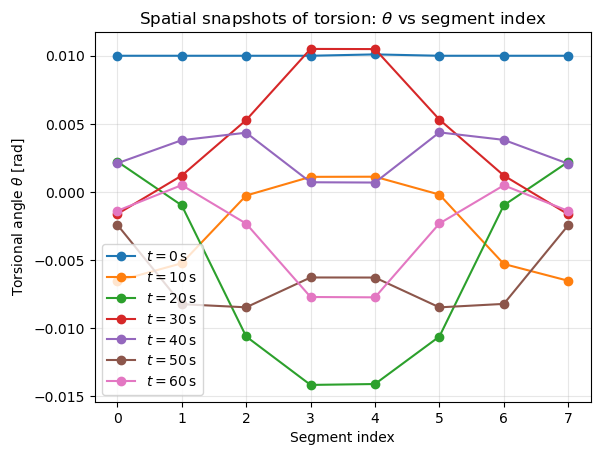

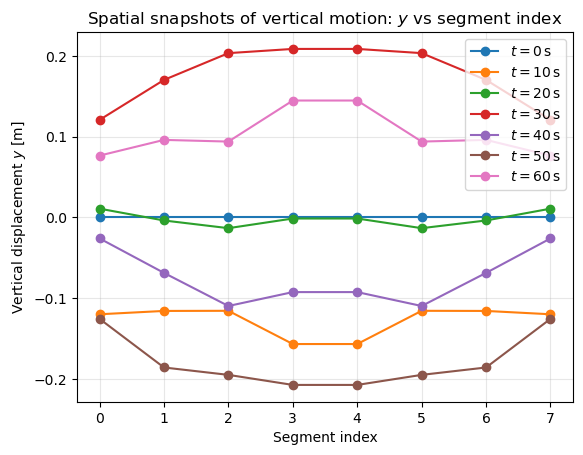

In [90]:
# ============================================================
# EXAMPLE RUN (MULTI-SEGMENT + SMALL PERTURBATION)
# ============================================================

bridge_system = BridgeSystem(
    number_of_bridge_segments=8,
    simulation_end_time=60.0,
    time_step=0.01,
    vertical_coupling_strength=10.0,
    torsional_coupling_strength=5.0,
    wind_force_amplitude=2.0,
    wind_angular_frequency=2.35
)

# Apply a small torsional perturbation to the middle segment (to break symmetry)

middle_segment_index = bridge_system.number_of_bridge_segments // 2

bridge_system.set_initial_conditions(
    initial_vertical_displacement=0.0,
    initial_torsional_angle=0.01,
    initial_vertical_velocity=0.0,
    initial_torsional_angular_velocity=0.0,
    perturbed_segment_index=middle_segment_index,
    torsional_angle_perturbation=1e-4
)

time_array, torsional_angle_history, vertical_displacement_history = bridge_system.run_simulation(
    use_euler_cromer=True
)

# Spatial snapshots of the torsional angle and vertical displacement along the bridge at selected times.

snapshot_times_seconds = [0, 10, 20, 30, 40, 50, 60]
segment_index_array = np.arange(bridge_system.number_of_bridge_segments)

plt.figure()

for snapshot_time in snapshot_times_seconds:

    snapshot_index = int(snapshot_time / bridge_system.time_step)
    if snapshot_index >= len(time_array):
        continue

    plt.plot(
        segment_index_array,
        torsional_angle_history[snapshot_index, :],
        marker="o",
        label=rf"$t = {snapshot_time}\,\mathrm{{s}}$"
    )

plt.xlabel("Segment index")
plt.ylabel(r"Torsional angle $\theta$ [rad]")
plt.title(r"Spatial snapshots of torsion: $\theta$ vs segment index")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

plt.figure()

for snapshot_time in snapshot_times_seconds:

    snapshot_index = int(snapshot_time / bridge_system.time_step)
    if snapshot_index >= len(time_array):
        continue

    plt.plot(
        segment_index_array,
        vertical_displacement_history[snapshot_index, :],
        marker="o",
        label=rf"$t = {snapshot_time}\,\mathrm{{s}}$"
    )

plt.xlabel("Segment index")
plt.ylabel(r"Vertical displacement $y$ [m]")
plt.title(r"Spatial snapshots of vertical motion: $y$ vs segment index")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

These final plots show an example run of this model with 8 segments and a pertubation to the centre. The torsional amplitudes could be seen to become significantly larger in the central segments for $t = 20s$ and $t = 30s$, indicating strong coupling and possible resonant growth before later reversing sign, whilst the vertical displacement appeared to display continuously large deflections between positive and negative during the 60 seconds. The graphs together ultimately suggest energy transfer between vertical and torsional modes, with the central segments experiencing the greatest oscillatory response. A deeper analysis could entail varying the initial conditions such as wind amplitude and forcing frequency to observe any changes in behaviour, as done with the sweeps in the previous sections.

## 4. Conclusion

Ultimately, the 5CCP211C Introduction to Numerical Modelling course has equipped me with the skills required to solve (or approximate solutions to) two interesting computational problems, and by extension many more. 

Considering randomisation with Monte Carlo algorithms alongside understanding the different steps of the Metropolis method and applying this to the Ising model enabled me to be able to create heuristics to tackle a version of the Travelling Salesman Problem considering 30 capital cities in the USA. It was found that the easy to interpret and simpler to implement Nearest Neighbour algorithm yielded a best tour length of 2338.63, although this solution was not optimal due to the greedy decisions made that are part of the algorithm’s nature. On the other hand, the Simulated Annealing algorithm had a best tour length of 2285.92 yet was beaten by the Genetic Algorithm with a tour length of 2202.91 that also visually looked like one of the most optimal solutions on the map presented. However, it was key to note that the latter two required tuning of parameters and their implementations were more advanced, alongside the fact that they required multiple runs to explore for more optimal solutions (due to stochastic effects) in contrast to the deterministic nature of the NN algorithm. Outlooks regarding these algorithms include the investigation of different temperature schedules for the SA algorithm, such as linear, quadratic, or logarithmic, whilst different types of mutations such as inversion and scramble mutations could be utilised in the GA. Furthermore, the exploration of machine learning in later weeks of the course could be relevant when tuning parameters, or when making the algorithms more adaptive, for instance in the creation of an adaptive temperature schedule for the SA algorithm. 

The exploration of solving ordinary differential equations with the contexts of pendulums and quantum boxes in the course also enabled me to investigate the Tacoma Narrows collapse, modelling the vertical displacement and torsional angle to investigate the relationship proposed by McKenna and Tuama, with the interlinking of the heatmaps, frequency-response graphs and phase plots revealed the relationship that at resonant or close to resonant frequencies the transfer of energy was maximised from the vertical mode to the torsional mode, resulting in chaotic behaviour that could have led to the collapse of the bridge. Future work could entail utilising linear algebra techniques explored in later weeks of the course to model forces or other properties of the bridge using matrices (research on the discrete Laplacian revealed a matrix representation of it), or expanding on the Object-Oriented Programming (OOP) model of the bridge by including other aspects like dampers or pylons, as well as investigating what happens to the bridge for various different conditions such as greater wind amplitudes or different initial tortional angles; the modularity of OOP enables it to be very flexible for such applications, and the implementation in this report serves only as a foundation. Additionally, other integration methods could be trialled, such as Runge-Kutta.

Overall, the results obtained were significant as the first project demonstrated the impact of stochastic effects, which can be noteworthy when modelling systems with lots of randomness; it also demonstrated the compromise between computational cost and attaining an accurate result, as it was shown that whilst the GA obtained the shortest length it had a very long run time relative to the other two heuristics – this would have to be considered in real-world applications such as in navigation and route-planning. Additionally, it was briefly mentioned how variations of the TSP could be solved, so these implementations serve as a framework that can be expanded on to solve other optimisation problems. In relation to the second project, it was worthwhile in equipping one with the skills to model complex systems, and as mentioned in the introduction the ability to extrapolate this to other scenarios (beyond the structural engineering applications investigated in this report) makes it extremely powerful in various industries, for instance in modelling the spread of disease or global financial markets. 


### Acknowledgements

I would like to give my thanks to Dr Jim Dobson for allowing me to undertake these projects and equipping me with the knowledge to complete them, as well as 
show my gratitude to any GTAs that have provided assistance too.

## References

Allen, M. (2016) How computers have changed how we do Physics: Chaos and Climate. Lecture presented at the Martin Wood Lecture Theatre, Clarendon Laboratory, University of Oxford, 6 February. Available at: http://groups.physics.ox.ac.uk/sattheory/events/presentations/Myles%20Allen%20(revised).pdf Date Accessed: 17 February 2026

Ambainis, A., Balodis, K., Iraids, J., Kokainis, M., Prūsis, K. and Vihrovs, J. (2019). Quantum Speedups for Exponential-Time Dynamic Programming Algorithms. Proceedings of the Thirtieth Annual ACM-SIAM Symposium on Discrete Algorithms, pp.1783–1793. doi:https://doi.org/10.1137/1.9781611975482.107. Date Accessed: 17 February 2026

Bashford, J. (1940) Howard Clifford running off the Tacoma Narrows Bridge during the collapse, 7 November 1940 [photograph]. Courtesy of University of Washington Special Collections (FAR021). Date Accessed: 22 February 2026

Brownlee, J. (2021). Simulated Annealing From Scratch in Python. [online] Machine Learning Mastery. Available at: https://machinelearningmastery.com/simulated-annealing-from-scratch in-python/. Date Accessed: 03 January 2026

Cook, W.J., (2012). In Pursuit of the Traveling Salesman: Mathematics at the Limit of Computation. Princeton: Princeton University Press. Date Accessed: 17 February 2026

Channel, T.W. (2024). On Today’s Date: When Wind Tore A Bridge Apart. [online] Weather.com. Available at: https://weather.com/news/weather/news/2024-11-06-on-todays-date-wind-galloping-gertie Date Accessed: 22 February 2026

David, T. (2010). Tuned Mass Damper of Taipei 101. [online] Atlas Obscura. Available at: https://www.atlasobscura.com/places/tuned-mass-damper-of-taipei-101. Date Accessed: 03 January 2026

Damn Interesting. (n.d.). The Fall of Galloping Gertie. [online] Available at: https://www.damninteresting.com/the-fall-of-galloping-gertie/. Accessed: 22 February 2026

Dorigo, M. (2007). Ant colony optimization. Scholarpedia, [online] 2(3), p.1461. doi:https://doi.org/10.4249/scholarpedia.1461. Date Accessed: 17 February 2026

GeeksforGeeks (2017). Genetic Algorithms. [online] GeeksforGeeks. Available at: https://www.geeksforgeeks.org/dsa/genetic-algorithms/. Date Accessed: 03 January 2026

GeeksforGeeks (2020). Proof that traveling salesman problem is NP Hard. [online] GeeksforGeeks. Available at: https://www.geeksforgeeks.org/dsa/proof-that-traveling-salesman-problem-is-np-hard/. Date Accessed: 03 January 
2026

GeeksforGeeks (2024). What is Simulated Annealing. [online] GeeksforGeeks. Available at: https://www.geeksforgeeks.org/artificial-intelligence/what-is-simulated-annealing/. Date Accessed: 03 January 2026

Gilbert, S. (2015). The Asymmetric Traveling Salesman. [online] Available at: https://www.comp.nus.edu.sg/~gilbert/CS4234/2015/lectures/06.ATSP.pdf. Accessed: 22 February 2026

Government Office for Science (2018) Computational modelling: technological futures. The Blackett Review. London: Government Office for Science. Available at: https://assets.publishing.service.gov.uk/media/5a8c1a6fe5274a1277ce76c4/computational-modelling-blackett-review.pdf Date Accessed: 03 January 2026

Guo, X., Mo, B. and Wang, Q. (2023). Amazon Last-Mile Delivery Trajectory Prediction Using Hierarchical TSP with Customized Cost Matrix. [online] arXiv.org. Available at: https://arxiv.org/abs/2302.02102. Date Accessed: 17 February 2026

Hayes-Roth, F. (1975). Review of ‘Adaptation in Natural and Artificial Systems by John H. Holland’, The U. of Michigan Press, 1975. ACM SIGART Bulletin, (53), p.15. doi:https://doi.org/10.1145/1216504.1216510. Date Accessed: 03 January 2026

Hakimian, R. (2021). New study uncovers real reason behind Millennium Bridge wobble. [online] New Civil Engineer. Available at: https://www.newcivilengineer.com/latest/new-study-uncovers-real-reason-behind-millennium-bridge-wobble-15-12-2021/. Date Accessed: 17 February 2026

HM Government (2023) National Quantum Strategy. London: HM Government. Available at: https://assets.publishing.service.gov.uk/media/6411a602e90e0776996a4ade/national_quantum_strategy.pdf Date Accessed: 17 February 2026

Kirkpatrick, S., Gelatt, C.D. and Vecchi, M.P. (1983). Optimization by Simulated Annealing. Science, 220(4598), pp.671–680. doi:https://doi.org/10.1126/science.220.4598.671. Date Accessed: 03 January 2026

Krymgand, A. (n.d.). The Christofides Algorithm. [online] Alon Krymgand. Available at: https://alon.kr/posts/christofides. Date Accessed: 17 February 2026

Luu, Q.T. (2023). Baeldung. Baeldung on Computer Science. [online] doi:https://doi.org/10.1145//321043.321046. Date Accessed: 22 February 2026

Masters, B. (2017). Aeroelastic Flutter & the Collapse of the Tacoma Narrows Bridge. [online] Bridge Masters. Available at: https://bridgemastersinc.com/aeroelastic-flutter-collapse tacoma-narrows-bridge/. Date Accessed: 03 January 2026

McKee, A. (2024). Genetic Algorithm: Complete Guide With Python Implementation. [online] Datacamp.com. Available at: https://www.datacamp.com/tutorial/genetic-algorithm-python. Date Accessed: 03 January 2026

McKenna, P.J. and Tuama, C.O. (2001). Large Torsional Oscillations in Suspension Bridges Visited Again: Vertical Forcing Creates Torsional Response. The American Mathematical Monthly, 108(8), p.738. doi:https://doi.org/10.2307/2695617. Date Accessed: 03 January 2026

Newman, M. (2016) Structure in Complex Systems. Lecture presented at the Martin Wood Lecture Theatre, Clarendon Laboratory, University of Oxford, 6 February. Available at: https://groups.physics.ox.ac.uk/sattheory/events/presentations/Newman.pdf Date Accessed: 17 February 2026

Newspapers.com. (1940). Article clipped from The News Tribune. [online] Available at: https://www.newspapers.com/article/the-news-tribune/183904654/ Accessed: 22 February 2026

Purdue University (2002). Tuned Mass Damper Systems 4.1 INTRODUCTION. [online] Available at: https://engineering.purdue.edu/~ce573/Documents/Intro%20to%20Structural%20Motion%20Control_Chapter4.pdf Date Accessed: 03 January 2026

Ricardo, A. (2014) Jogo icosiano 01 [Photograph]. Matemateca (IME/USP). Available at: https://upload.wikimedia.org/wikipedia/commons/1/1d/Jogo_icosiano_01.jpg Date Accessed: 22 February 2026

Rinux (2008) Taipei 101 damper. Available at: https://www.flickr.com/photos/rinux/2885419140/in/photostream/ Date Accessed: 23 February 2026

Singh, B.A., Deka, D. and Sundar, K. (2024). Equitable Routing--Rethinking the Multiple Traveling Salesman Problem. [online] arXiv.org. Available at: https://arxiv.org/abs/2404.08157 Accessed: 22 February 2026

Uwaterloo.ca. (2023). Available at: https://www.math.uwaterloo.ca/tsp/methods/dfj/index.html. Date Accessed: 17 February 2026

Wahl, T.B. (2016) Breaking through the quantum barrier. Lecture presented at the Martin Wood Lecture Theatre, Clarendon Laboratory, University of Oxford, 6 February. Available at: https://groups.physics.ox.ac.uk/sattheory/events/presentations/Wahl.pdf Date Accessed: 17 February 2026

Washington State Department of Transportation (n.d.). WSDOT - Tacoma Narrows Bridge: Extreme History. [online] www.wsdot.wa.gov. Available at: https://www.wsdot.wa.gov/tnbhistory/. Date Accessed: 03 January 2026

www.maths.manchester.ac.uk. (n.d.). Numerical analysis and scientific computing - Department of Mathematics - The University of Manchester. [online] Available at: https://www.maths.manchester.ac.uk/research/themes/numerical-analysis-and-scientific-computing/ Date Accessed: 03 January 2026

www.math.uwaterloo.ca. (n.d.). TSP Applications. [online] Available at: https://www.math.uwaterloo.ca/tsp/apps/index.html Date Accessed: 03 January 2026

www.wsdot.wa.gov. (n.d.). Tacoma Narrows Bridge history - Eyewitness accounts. [online] Available at: https://www.wsdot.wa.gov/tnbhistory/eyewitnesses.htm. Date Accessed: 03 January 2026

Zhang, R. (2020) 18.085/18.0851 Computational Science and Engineering I: Week 7 Lecture Notes (July 20–24). Summer 2020. Massachusetts Institute of Technology OpenCourseWare. Available at: https://ocw.mit.edu/courses/18-085-computational-science-and-engineering-i summer-2020/3710ae376bc38588cef86d2762c3e3b2_MIT18_085Summer20_lec_w7.pdf Date Accessed: 16 January 2026

Zhang, Y., Luo, M., Wu, P., Wu, S., Lee, T.-Y. and Bai, C. (2022). Application of Computational Biology and Artificial Intelligence in Drug Design. International Journal of Molecular Sciences, 23(21), p.13568. doi:https://doi.org/10.3390/ijms232113568. Date Accessed: 03 January 2026
